# EDA dữ liệu Round 3 – BI10

> **Bước 1/5 · Hiểu dữ liệu** · bản đồ toàn bài: `README.md`
>
> **Câu hỏi của đề được trả lời ở đây:**
> - What data are needed to understand shop performance (phần dữ liệu)
>
> **Đầu vào → đầu ra:** `Round3_BI10_dataset/` → các quy tắc làm sạch đề xuất (dùng ở `02_clean_data.py`)
>
> **Đọc tiếp:** `02_clean_data.py`

Kiểm tra chất lượng toàn bộ 7 bảng dữ liệu Round 3 theo 5 nhóm:

1. **Tổng quan**: số dòng, số cột, kiểu dữ liệu, xu hướng theo thời gian
2. **Null**: null thật và *null trá hình* (`XNA`, `-1`, chuỗi rỗng, ngày `3000-01-01`)
3. **Duplicated**: trùng toàn dòng và trùng khóa chính
4. **Outlier**: phân vị, ngưỡng IQR, giá trị âm / bằng 0
5. **Logic & khóa nối**: ràng buộc nghiệp vụ và độ khớp khóa giữa các bảng

Mỗi mục có **biểu đồ** để đọc nhanh; bảng số chi tiết vẫn giữ ở những chỗ cần tra cứu.
Cuối notebook có **bảng tổng hợp các vấn đề** cần xử lý trước khi phân tích.

> Công cụ: DuckDB (đọc trực tiếp CSV 1 GB mà không cần nạp hết vào RAM) + pandas + matplotlib / seaborn.
> Quy ước màu: **xanh** = giá trị bình thường, **đỏ** = giá trị giữ chỗ / bất thường, **xám** = tham chiếu.

In [1]:
import duckdb, pandas as pd, numpy as np, pathlib, textwrap
import matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

DATA = pathlib.Path(r'D:/Thi/BI/BI_ROUND 3/Round3_BI10_dataset')
con = duckdb.connect()
con.sql("SET preserve_insertion_order=false")

# Bảng lớn (CSV) -> nạp vào DuckDB; bảng nhỏ (XLSX) -> đọc bằng pandas rồi đăng ký vào DuckDB
for t in ['leads', 'contract', 'contract_product', 'emp_2_salesroom']:
    con.sql(f"CREATE OR REPLACE TABLE {t} AS SELECT * FROM read_csv('{(DATA / (t + '.csv')).as_posix()}')")
for t in ['salesroom', 'seller', 'cl_lead_fin_reason']:
    df = pd.read_excel(DATA / f'{t}.xlsx')
    con.register(f'{t}_df', df)
    con.sql(f'CREATE OR REPLACE TABLE {t} AS SELECT * FROM {t}_df')

# các cột ngày trong file Excel đang là chuỗi 'dd-mm-yyyy hh:mm:ss' -> đổi sang timestamp
con.sql("""CREATE OR REPLACE TABLE salesroom AS SELECT * REPLACE (
    strptime(SALESROOM_START, '%d-%m-%Y %H:%M:%S') AS SALESROOM_START,
    try_strptime(SALESROOM_END, '%d-%m-%Y %H:%M:%S') AS SALESROOM_END) FROM salesroom""")
con.sql("""CREATE OR REPLACE TABLE seller AS SELECT * REPLACE (
    strptime(SELLER_ACTIVE_DATE, '%d-%m-%Y %H:%M:%S') AS SELLER_ACTIVE_DATE) FROM seller""")

TABLES = ['leads', 'contract', 'contract_product', 'emp_2_salesroom', 'salesroom', 'seller', 'cl_lead_fin_reason']
q = lambda s: con.sql(s).df()
ISSUES = []   # (bảng, nhóm, vấn đề, số dòng, cách xử lý)
def issue(tbl, group, desc, n, action):
    ISSUES.append((tbl, group, desc, n, action))

# contract: bỏ hợp đồng không xác định được khách (skp_client = -1 là mã giữ chỗ, hoặc null)
n_no_client = con.sql("SELECT count(*) FROM contract WHERE skp_client IS NULL OR skp_client = -1").fetchone()[0]
con.sql("DELETE FROM contract WHERE skp_client IS NULL OR skp_client = -1")
issue('contract', 'Null trá hình', 'skp_client = -1 / null', n_no_client, 'Bỏ ngay khi nạp dữ liệu')
print(f'contract: bỏ {n_no_client:,} hợp đồng có skp_client = -1 / null')

# ---------- style & hàm vẽ dùng chung ----------
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.9)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.titlelocation': 'left',
                     'axes.spines.top': False, 'axes.spines.right': False})
PAL = sns.color_palette('tab10')
C_MAIN, C_ALT, C_BAD, C_GREY, C_OK = '#416aaf', '#ea5739', '#ce2827', '#a0aec0', '#6399c7'
PLACEHOLDER = {'XNA', '.', '-1', '', 'None', '<null>', 'nan', 'NULL'}
PRODUCTS = ['CL', 'BNPL', 'CD', 'CC', 'TW', 'CW']
PCOLOR = dict(zip(PRODUCTS + ['None'], PAL))   # màu cố định cho từng sản phẩm ở mọi biểu đồ

def human(x, _=None):
    """1234567 -> 1.2M"""
    x = float(x)
    for d, s in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(x) >= d:
            return f'{x / d:,.1f}'.rstrip('0').rstrip('.') + s
    return f'{x:,.0f}'

def short(s, n=32):
    s = str(s)
    return s if len(s) <= n else s[:n - 1] + '…'

def barh(ax, labels, values, title=None, color=C_MAIN, pct=False, log=False, fmt=None, maxlen=45):
    """Bar ngang có nhãn giá trị; phần tử đầu tiên nằm trên cùng."""
    labels = [short(l, maxlen) for l in labels]
    values = np.asarray(values, dtype=float)
    y = np.arange(len(values))
    ax.barh(y, values, color=color)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    fmt = fmt or ((lambda v: f'{v:.1f}%') if pct else human)
    if log:
        ax.set_xscale('log'); ax.set_xlim(left=0.8)
    else:
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=None) if pct else mtick.FuncFormatter(human))
    for yi, v in zip(y, values):
        pos = v if np.isfinite(v) else 0
        ax.annotate(fmt(v) if np.isfinite(v) else '–', (max(pos, 1) if log else pos, yi), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8)
    ax.margins(x=0.18)
    ax.grid(axis='y', visible=False)
    if title: ax.set_title(title)
    return ax

def colors_for(labels):
    return [C_BAD if str(v) in PLACEHOLDER else C_MAIN for v in labels]
import seaborn as sns
RDYLBU = sns.color_palette('RdYlBu', 11).as_hex()       # bảng màu chung của mọi biểu đồ
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[RDYLBU[i] for i in (10, 1, 8, 3, 0, 9, 2, 7)])
plt.rcParams['image.cmap'] = 'RdYlBu'


contract: bỏ 332 hợp đồng có skp_client = -1 / null


**Nhãn biểu đồ tiếng Anh:** cell dưới dịch mọi chữ trên biểu đồ (tiêu đề, trục, chú thích, nhãn) sang tiếng Anh ngay trước khi hiện. Bảng và câu in ra giữ tiếng Việt.

In [2]:
# --- Nhãn biểu đồ bằng tiếng Anh: mọi chữ trên biểu đồ được dịch ngay trước khi hiện; bảng và câu in ra giữ tiếng Việt ---
import re as _re
import matplotlib.pyplot as plt
_EN = {
 # ===== 03 Current Actual =====
 '% HĐ': '% contracts', '% HĐ CD/TW trễ kỳ 1–4': '% CD/TW contracts late in instalments 1–4', '% HĐ thành công': '% successful contracts',
 '% HĐ thành công theo kênh (quý nộp)': '% successful contracts by channel (application quarter)', '% HĐ trễ kỳ 1–4 theo vùng': '% contracts late in instalments 1–4 by region',
 '% giá trị': '% value', '% giá trị khoản vay đã ký': '% signed loan value', '% giá trị khoản vay đã ký theo kênh': '% signed loan value by channel',
 '% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, theo nơi vay': '% first-time CD/TW shop customers taking CL/CC/CW within 12 months, by where they borrow',
 '% shop (xếp theo năng suất giảm dần)': '% shops (ranked by productivity, descending)', '% shop của mỗi lứa (tháng mở) hiện đã đóng cửa': '% of each opening cohort now closed',
 '% shop đang hoạt động theo giai đoạn': '% active shops by lifecycle stage', '% shop đang mở có phát sinh HĐ ký trong tháng': '% open shops with ≥ 1 signed contract in the month',
 '% shop đã đóng cửa theo vùng': '% shops closed by region', '% số HĐ ký': '% signed contracts', '% số shop': '% shops',
 '1. Mới mở (0–2 tháng)': '1. New (0–2 months)', '2. Tăng tốc (3–5 tháng)': '2. Ramp-up (3–5 months)', '3. Ổn định (≥ 6 tháng)': '3. Mature (≥ 6 months)',
 '100 hồ sơ nộp Q3/2026 đi về đâu (theo phân khúc)': 'Where 100 applications in Q3/2026 end up (by segment)',
 '25% shop bán cao nhất': 'Top 25% shops by sales', '25% shop bán thấp nhất (có HĐ)': 'Bottom 25% shops by sales (with contracts)',
 'Bị từ chối': 'Rejected', 'Chiến dịch (SOB, GMA_SCORING)': 'Campaign (SOB, GMA_SCORING)', 'Chưa từng có HĐ': 'Never had a contract', 'Cùng shop': 'Same shop',
 'Cơ cấu HĐ thành công theo sản phẩm': 'Successful contracts by product', 'Cơ cấu sản phẩm theo kênh (HĐ thành công, Q3/2026)': 'Product mix by channel (successful contracts, Q3/2026)',
 'Dòng hàng chính': 'Main product line', 'FOLLOW_UP: lead → HĐ ký': 'FOLLOW_UP: lead → signed contract', 'FPD của shop: trung vị → P90 theo phân khúc': 'Shop FPD: median → P90 by segment',
 'Giá trị / shop / tháng (triệu đ)': 'Value / shop / month (VND m)', 'Giá trị / shop / tháng theo tuổi shop (triệu đ)': 'Value / shop / month by shop age (VND m)',
 'Giá trị khoản vay / shop / tháng': 'Loan value / shop / month', 'Giá trị khoản vay đã ký (VND)': 'Signed loan value (VND)', 'Giá trị khoản vay đã ký / tháng': 'Signed loan value / month',
 'Giá trị khoản vay đã ký mỗi tháng (loan_amount_eff)': 'Signed loan value per month (loan_amount_eff)', 'Huỷ': 'Cancelled',
 'HĐ / shop / tháng': 'Contracts / shop / month', 'HĐ / tháng': 'Contracts / month', 'HĐ ký / shop / tháng': 'Signed contracts / shop / month',
 'HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)': 'Signed contracts / shop / month (shops ≥ 1 month old)',
 'HĐ ký / shop theo tuổi shop – theo lứa mở': 'Signed contracts / shop by shop age – by opening cohort',
 'HĐ ký / shop theo tuổi shop – theo phân khúc (CD · Aldi xem bảng)': 'Signed contracts / shop by shop age – by segment (CD · Aldi: see table)',
 'HĐ ký / tháng Q3/2026 (thang log)': 'Signed contracts / month Q3/2026 (log scale)', 'HĐ ký 03/2025 – 05/2026 (đủ tuổi)': 'Contracts signed 03/2025 – 05/2026 (matured)',
 'HĐ ký mỗi tháng theo giai đoạn vòng đời của shop': 'Signed contracts per month by shop lifecycle stage', 'HĐ thành công / tháng (Q3/2026)': 'Successful contracts / month (Q3/2026)',
 'HĐ thành công / tháng của từng shop, theo phân khúc chi tiết': 'Successful contracts / month per shop, by peer group', 'HĐ đã ký': 'Signed contracts',
 'HĐ đã ký / shop': 'Signed contracts / shop', 'HĐ đã ký / tháng (Q3/2026)': 'Signed contracts / month (Q3/2026)', 'HĐ đã ký mỗi tháng': 'Signed contracts per month',
 'Hồ sơ / tháng': 'Applications / month', 'Instant (trong phiên bán)': 'Instant (during the sale)', 'Khoản vay BQ': 'Avg loan size',
 'Khoản vay bình quân (triệu đ)': 'Avg loan size (VND m)', 'Khoản vay bình quân của shop (trung vị, triệu đ, không tính CC)': 'Avg loan size per shop (median, VND m, excl. CC)',
 'Khoản vay bình quân theo tuổi shop (triệu đ)': 'Avg loan size by shop age (VND m)', 'Khoản vay trung vị (VND)': 'Median loan size (VND)', 'Khác': 'Other',
 'Khách huỷ': 'Customer cancelled', 'Khách hàng có HĐ ký (Q3/2026)': 'Customers with signed contracts (Q3/2026)', 'Khách mới / shop / tháng (Q3/2026)': 'New customers / shop / month (Q3/2026)',
 'Khách theo sản phẩm đã dùng': 'Customers by products used', 'Không rõ': 'Unknown', 'Kết quả xử lý lead': 'Lead outcome',
 'Kỳ 1 (FPD)': 'Instalment 1 (FPD)', 'Kỳ 2': 'Instalment 2', 'Kỳ 3': 'Instalment 3', 'Kỳ 4': 'Instalment 4',
 'Lead / shop / tháng (bỏ RTDM), theo loại lead': 'Leads / shop / month (excl. RTDM), by lead type', 'Lead → HĐ ký (30 ngày)': 'Lead → signed contract (30 days)',
 'Lead → HĐ ký (30 ngày), theo loại lead': 'Lead → signed contract (30 days), by lead type', 'Loại đại lý': 'Partner type',
 'Mô hình (Aldi = NV shop tự làm HĐ)': 'Model (Aldi = partner staff handle applications)', 'Mỗi chấm = 1 shop (kích thước = số HĐ); đường chấm = trung vị phân khúc': 'Each dot = 1 shop (size = # contracts); dotted lines = segment median',
 'Mỗi shop Non-Aldi có bao nhiêu SA quy đổi?': 'How many SA FTE does each Non-Aldi shop have?', 'Mới mở (từ 07/2026)': 'New (opened from 07/2026)',
 'Mở 2025-H1': 'Opened 2025-H1', 'Mở 2025-H2': 'Opened 2025-H2', 'Mở 2026 (01–09)': 'Opened 2026 (01–09)', 'Mở mới': 'Opened', 'Mở ròng': 'Net openings',
 'Ngừng phát sinh': 'Stopped selling', 'Nhiều SA hơn có nhiều HĐ hơn không?': 'Do more SAs mean more contracts?', 'Nhiều sản phẩm': 'Multiple products',
 'Nhóm hàng (số HĐ)': 'Goods group (# contracts)', 'Năng suất vs tỷ lệ trễ hạn (shop ≥ 30 HĐ CD/TW đủ tuổi)': 'Productivity vs delinquency (shops with ≥ 30 matured CD/TW contracts)',
 'ORIGINATION: lead → hồ sơ / HĐ ký': 'ORIGINATION: lead → application / signed contract', 'POS ngoài danh sách shop': 'POS outside shop master',
 'Phân bổ trạng thái hồ sơ theo sản phẩm': 'Application status by product', 'Q3/2026 · không phải tỷ lệ duyệt': 'Q3/2026 · not the approval rate', 'Quy mô shop': 'Shop size',
 'SA quy đổi': 'SA FTE', 'SA quy đổi của shop': 'Shop SA FTE', 'Shop bán nhiều có rủi ro cao hơn không? (mỗi chấm = 1 shop)': 'Do high-selling shops carry more risk? (each dot = 1 shop)',
 'Shop bán tốt khác shop bán kém chủ yếu ở số hồ sơ, không ở tỷ lệ không bị từ chối/hoàn tất': 'Strong and weak shops differ mainly in applications, not in approval/completion rates',
 'Shop mới – Current Actual (Q3/2026)': 'New shops – Current Actual (Q3/2026)', 'Shop mở mới, đóng cửa và mở ròng mỗi tháng': 'Shop openings, closures and net openings per month',
 'Shop trung vị (trưởng thành)': 'Median shop (mature)', 'Shop vật lý': 'Physical shop', 'Shop vật lý khác': 'Other physical shop', 'Shop vật lý ≥ 3 tháng tuổi': 'Physical shops ≥ 3 months old',
 'Shop đang hoạt động': 'Active shops', 'Shop đang hoạt động (09/2026)': 'Active shops (09/2026)', 'Shop ảo (Virtual)': 'Virtual shop',
 'Số hồ sơ vay mỗi tháng (theo sản phẩm)': 'Loan applications per month (by product)', 'Số hợp đồng ĐÃ KÝ mỗi tháng (theo sản phẩm)': 'SIGNED contracts per month (by product)',
 'Số hợp đồng đã ký trên mỗi khách': 'Signed contracts per customer', 'Số kỳ trả góp trung vị': 'Median number of instalments', 'Số shop mở mới mỗi tháng, theo dòng hàng': 'New shops per month, by product line',
 'Số shop theo trạng thái hoạt động thực tế (cuối Q3/2026)': 'Shops by actual activity status (end of Q3/2026)', 'Số shop theo vùng': 'Shops by region', 'Số shop đang hoạt động': 'Active shops',
 'TB trượt 3 tháng': '3-month moving average', 'Thay đổi HĐ ký / tháng so với quý trước, tách theo nguồn': 'Change in signed contracts / month vs previous quarter, by source',
 'Thành HĐ': 'Signed', 'Thời gian nộp → ký của shop: dải P25–P75, chấm = trung vị, vạch = P90': 'Shop application → signing time: band P25–P75, dot = median, tick = P90',
 'Thời gian từ nộp hồ sơ đến ký (HĐ ký)': 'Time from application to signing (signed contracts)', 'Thời gian xử lý': 'Processing time', 'Top 15 tỉnh theo số shop': 'Top 15 provinces by shop count',
 'Top hãng sản xuất (số HĐ)': 'Top manufacturers (# contracts)', 'Toàn bộ': 'All', 'Trạng thái': 'Status', 'Trả trước trung vị (% giá hàng)': 'Median down payment (% of price)',
 'Trễ hạn kỳ 1–4 theo sản phẩm': 'Late in instalments 1–4 by product', 'Trễ hạn kỳ 1–4 theo vùng': 'Late in instalments 1–4 by region', 'Trễ kỳ đầu (FPD) theo tháng ký': 'First-payment default (FPD) by signing month',
 'Trễ ngay kỳ đầu (FPD) theo sản phẩm': 'First-payment default (FPD) by product', 'Trễ ≥ 1 kỳ trong kỳ 1–4 theo tháng ký': 'Late in ≥ 1 of instalments 1–4 by signing month',
 'Tăng trưởng HĐ ký so với quý trước (QoQ)': 'Signed contracts growth vs previous quarter (QoQ)', 'Tăng trưởng HĐ ký so với tháng trước (MoM)': 'Signed contracts growth vs previous month (MoM)',
 'Từ chối': 'Rejected', 'Tỷ lệ DEAL theo nguồn lead': 'DEAL rate by lead source', 'Tỷ lệ DEAL theo sản phẩm': 'DEAL rate by product', 'Tỷ lệ bị từ chối': 'Rejection rate',
 'Tỷ lệ bị từ chối (theo tháng nộp hồ sơ)': 'Rejection rate (by application month)', 'Tỷ lệ duyệt (khoảng cận dưới – cận trên)': 'Approval rate (lower – upper bound)', 'Tỷ lệ hoàn tất': 'Completion rate',
 'Tỷ lệ huỷ': 'Cancellation rate', 'Tỷ lệ huỷ (theo tháng nộp hồ sơ)': 'Cancellation rate (by application month)', 'Tỷ lệ không bị từ chối': 'Non-rejection rate', 'Tỷ lệ ký': 'Signing rate',
 'Tỷ lệ ký (HĐ ký / hồ sơ)': 'Signing rate (signed / applications)', 'Tỷ lệ ký (HĐ thành công / hồ sơ)': 'Signing rate (successful contracts / applications)',
 'Tỷ lệ ký (HĐ đã ký / hồ sơ) – toàn bộ sản phẩm': 'Signing rate (signed / applications) – all products', 'Tỷ lệ ký (theo tháng nộp hồ sơ)': 'Signing rate (by application month)',
 'Tỷ lệ ký và khoảng tỷ lệ duyệt theo tháng nộp': 'Signing rate and approval-rate range by application month', 'Tỷ lệ ra HĐ ký theo nguồn lead': 'Lead → signed contract rate by lead source',
 'Tỷ lệ trễ hạn kỳ 1–4': 'Delinquency rate, instalments 1–4', 'Tỷ lệ trễ hạn kỳ 1–4 theo tháng ký (vintage)': 'Delinquency rate, instalments 1–4, by signing month (vintage)',
 'Tỷ lệ trễ hạn theo từng kỳ, theo tháng ký': 'Delinquency rate per instalment, by signing month', 'Tỷ trọng theo loại đối tác': 'Share by partner type',
 'Tỷ trọng theo mô hình cửa hàng': 'Share by shop model', 'Tỷ trọng theo vùng': 'Share by region', 'Xoá nợ (written off)': 'Written off',
 'bội số so với trung vị phân khúc (thang log)': 'multiple of segment median (log scale)', 'hiệu ứng mạng lưới (thêm shop)': 'network effect (more shops)', 'hiệu ứng năng suất': 'productivity effect',
 'lead giao 06–08/2026, có trọng số': 'leads assigned 06–08/2026, weighted', 'loan_amount_eff; chưa xác minh giải ngân thực tế': 'loan_amount_eff; actual disbursement not verified',
 'phút': 'minutes', 'phút (trung vị của từng shop)': 'minutes (median per shop)', 'ra HĐ ký (sign)': 'signed contract (sign)', 'tháng thứ k sau khi mở': 'month k after opening',
 'trung bình mỗi shop đang hoạt động': 'average per active shop', 'trung vị': 'median', 'tạo hồ sơ (apply)': 'application created (apply)',
 'Đang bán đều / tăng': 'Selling steadily / growing', 'Đang suy giảm': 'Declining', 'Đang xử lý': 'In process', 'Đã ký – bình thường': 'Signed – normal', 'Đã đóng': 'Closed',
 'Đóng cửa (âm)': 'Closed (negative)', 'Đường tập trung doanh số (Pareto)': 'Sales concentration curve (Pareto)',
 # ===== 05 =====
 'Chốt kém': 'Weak closing', 'Shop đang hoạt động: từ BAU tới Ceiling (HĐ ký / tháng)': 'Active shops: from BAU to Ceiling (signed contracts / month)',
 'Thiếu khách': 'Too few customers', 'Thị trường chưa chạm': 'Untapped market', 'Thiếu sản phẩm': 'Missing products', 'Thiếu SA': 'No SA assigned',
 # ===== 01 EDA =====
 '% HĐ có cờ trễ ≥ 1 kỳ, theo trạng thái': '% contracts with ≥ 1 late flag, by status', '% HĐ đã ký có cờ trễ, theo kỳ': '% signed contracts with a late flag, by instalment',
 '% credit_amount = 0 – theo trạng thái': '% credit_amount = 0 – by status', '% dòng khớp': '% rows matched', '% giá trị = 0': '% values = 0',
 '% hợp đồng (shop trong phạm vi) có nhân khẩu học Round 2 – theo tháng nộp hồ sơ: 01/2025 gần 100%, các tháng sau ~6%': '% contracts (in-scope shops) with Round 2 demographics – by application month: 01/2025 ~100%, later months ~6%',
 '% hợp đồng có credit_amount = 0 – theo sản phẩm': '% contracts with credit_amount = 0 – by product', '% khóa (giá trị khác nhau) khớp': '% keys (distinct values) matched',
 '% link có giờ giao lead SAU date_apply': '% links with lead assigned AFTER date_apply', '% link có giờ giao lead SAU date_sign': '% links with lead assigned AFTER date_sign',
 '% null theo SẢN PHẨM (contract)': '% null by PRODUCT (contract)', '% null theo TRẠNG THÁI (contract)': '% null by STATUS (contract)',
 '% null thật và null trá hình (XNA / -1 / 3000-01-01 / rỗng)\n– chỉ hiện các cột có thiếu': '% true nulls and disguised nulls (XNA / -1 / 3000-01-01 / empty)\n– only columns with missing values',
 '% nằm ngoài ngưỡng IQR': '% outside IQR fences', '% nữ': '% female', '% shop khác tỉnh với đại lý': '% shops in a different province from their partner',
 '% shop khác vùng với đại lý': '% shops in a different region from their partner', '% số dòng': '% rows', '% trá hình': '% disguised',
 '% trễ kỳ 1 theo tháng ký (vintage) – các tháng gần cuối chưa đủ thời gian quan sát': '% late on instalment 1 by signing month (vintage) – latest months not yet observable',
 '% ĐH trở lên': '% university or higher', '% ở TP.HCM': '% in HCMC', '0 (đạt)': '0 (pass)', '<18 (bất thường)': '<18 (abnormal)', '>80 (bất thường)': '>80 (abnormal)',
 'Bảng leads (có trọng số sample_weight; vạch đen = % số dòng thô)': 'Table leads (weighted by sample_weight; black tick = % raw rows)',
 'Dòng thừa theo khóa chính (thang log)': 'Extra rows by primary key (log scale)', 'Dòng trùng toàn bộ (thang log)': 'Fully duplicated rows (log scale)',
 'Hợp đồng nằm ở shop trong / ngoài phạm vi': 'Contracts at in-scope / out-of-scope shops', 'Hợp đồng theo tháng nộp hồ sơ (date_apply), chia theo sản phẩm': 'Contracts by application month (date_apply), by product',
 'Khách ở cùng tỉnh với shop?': 'Do customers live in the shop\'s province?', 'Nhóm tuổi (tính đến 05/06/2025)': 'Age group (as of 05/06/2025)', 'Null trá hình': 'Disguised null',
 'Round 2 – biến nhân khẩu học dạng phân loại': 'Round 2 – categorical demographic variables', 'Round 2 – hồ sơ nhân khẩu học: % null / trá hình': 'Round 2 – demographic profile: % null / disguised',
 'Round 2 – top 15 tỉnh nơi ở của khách (địa giới cũ)': 'Round 2 – top 15 customer home provinces (old boundaries)', 'Shop khác địa bàn với đại lý sở hữu': 'Shops located away from their owning partner',
 'Shop mở mới theo tháng (SALESROOM_START) – salesroom chỉ chứa shop mở từ 01/2025': 'New shops by month (SALESROOM_START) – salesroom only contains shops opened from 01/2025',
 'Số cột': 'Columns', 'Số dòng mỗi bảng (thang log)': 'Rows per table (log scale)', 'Số dòng vi phạm từng kiểm tra logic (thang log; nhãn xanh lá = đạt)': 'Rows violating each logic check (log scale; green label = pass)',
 'Số shop / đại lý (trục y log)': 'Shops per partner (log y-axis)', 'Thu nhập trung vị (tr)': 'Median income (VND m)',
 'Top 10 shop KHÔNG có trong salesroom (số hợp đồng) – kênh trung tâm / online': 'Top 10 shops NOT in salesroom (# contracts) – central / online channels',
 'Top luồng khác tỉnh: nơi ở (cũ) → tỉnh shop': 'Top cross-province flows: home (old) → shop province', 'Tuổi TB': 'Avg age', 'Tệp khách được phủ có giống tổng thể Round 2 không?': 'Is the covered customer base similar to the Round 2 population?',
 'Tỉnh shop có % khách cùng tỉnh THẤP nhất (≥ 300 HĐ)': 'Shop provinces with the LOWEST % same-province customers (≥ 300 contracts)', 'amt_billing_1st – chỉ BNPL / CC (log)': 'amt_billing_1st – BNPL / CC only (log)',
 'amt_loan_limit theo sản phẩm (log) – vùng đỏ nhạt: < 1 triệu hoặc > 1 tỷ': 'amt_loan_limit by product (log) – shaded: < VND 1m or > VND 1bn',
 'code_lead_status trong leads (thang log) – không có mã DEAL': 'code_lead_status in leads (log scale) – no DEAL code',
 'contract · Cancelled nhưng có ngày ký thật': 'contract · Cancelled but has a real signing date', 'contract · Giá ≠ trả trước + tiền vay (lệch > 1%) – chỉ CD/TW': 'contract · Price ≠ down payment + loan (gap > 1%) – CD/TW only',
 'contract · Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026)': 'contract · Signed after the last application date (30/09/2026)', 'contract · Ngày ký trước ngày nộp hồ sơ': 'contract · Signed before application date',
 'contract · Rejected nhưng có ngày ký thật': 'contract · Rejected but has a real signing date', 'contract · Thiếu product': 'contract · Missing product', 'contract · Thiếu skp_client': 'contract · Missing skp_client',
 'contract · Trạng thái đã ký (Active/Finished/Paid off/Written off) nhưng date_s…': 'contract · Signed status (Active/Finished/Paid off/Written off) but no date_sign',
 'contract · Trả trước > giá món hàng': 'contract · Down payment > price', 'credit_amount > 0 theo sản phẩm (log)': 'credit_amount > 0 by product (log)',
 'có trọng số (sum sample_weight)': 'weighted (sum of sample_weight)', 'cùng tỉnh': 'same province', 'khác tỉnh': 'other province',
 'emp_2_salesroom · Cùng nhân viên – cùng shop – các giai đoạn chồng lấn nhau': 'emp_2_salesroom · Same employee – same shop – overlapping periods',
 "emp_2_salesroom · code_status = 'a' nhưng đã hết hạn (valid_to < 30/09/2026)": "emp_2_salesroom · code_status = 'a' but expired (valid_to < 30/09/2026)",
 "emp_2_salesroom · code_status = 'n' nhưng valid_to = 3000": "emp_2_salesroom · code_status = 'n' but valid_to = 3000",
 'id_uuid trùng: tổ hợp sản phẩm được chào': 'Duplicated id_uuid: product combinations offered', 'kỳ 1': 'instalment 1', 'kỳ 2': 'instalment 2', 'kỳ 3': 'instalment 3', 'kỳ 4': 'instalment 4',
 'leads · Có số hợp đồng nhưng skp_credit_case = -1': 'leads · Has a contract but skp_credit_case = -1', 'leads · date_assigned trước dtime_created': 'leads · date_assigned before dtime_created',
 'max / p99  (> 3 → nghi đuôi bất thường)': 'max / p99  (> 3 → suspicious tail)', 'payment_num (số kỳ)': 'payment_num (instalments)', 'price (giá món hàng) – chỉ CD / TW (log)': 'price (goods price) – CD / TW only (log)',
 'salesroom · Có SALESROOM_END nhưng status ≠ Closed': 'salesroom · Has SALESROOM_END but status ≠ Closed', 'salesroom · Shop mở trước khi seller được kích hoạt': 'salesroom · Shop opened before seller activation',
 'salesroom · Status = Closed nhưng không có SALESROOM_END': 'salesroom · Status = Closed but no SALESROOM_END', 'salesroom · Đóng cửa trước ngày mở': 'salesroom · Closed before opening date',
 'shop CÓ trong salesroom (phạm vi)': 'shop IN salesroom (in scope)', 'shop KHÔNG có trong salesroom': 'shop NOT in salesroom', 'shop ngoài salesroom': 'shop outside salesroom',
 'shop trong salesroom': 'shop in salesroom', 'số dòng thô': 'raw rows', 'số hợp đồng': '# contracts', 'số shop': '# shops', 'số đại lý': '# partners', 'tuổi': 'age',
 'tổng credit_amount': 'total credit_amount', 'Độ khớp khóa nối bảng con → bảng cha': 'Key match rate: child table → parent table', 'Độ phủ theo phạm vi shop': 'Coverage by shop scope',
 'Độ phủ theo sản phẩm (trong phạm vi)': 'Coverage by product (in scope)', 'Độ phủ theo vùng (trong phạm vi)': 'Coverage by region (in scope)',
 'địa giới CŨ (còn quận/huyện)': 'OLD boundaries (still has district)', "địa giới MỚI (SALESROOM_DISTRICT = '.')": "NEW boundaries (SALESROOM_DISTRICT = '.')",
}
_G = lambda s: _tr(s)   # dịch đệ quy phần chữ trong nhóm
_RULES = [
 (r'^(\d+)% shop ký < 1 HĐ/tháng$', lambda m: f'{m[1]}% of shops sign < 1 contract/month'),
 (r'^([+-]?[\d.,]+) tỷ$', lambda m: f'{m[1]} bn'),
 (r'^(.*) HĐ/tháng$', lambda m: f'{m[1]} contracts/month'),
 (r'^(\d+\+?) HĐ$', lambda m: f'{m[1]} contracts'),
 (r'^(\w+): leads / tuần$', lambda m: f'{m[1]}: leads / week'),
 (r'^(.+)\nHĐ ký / tháng$', lambda m: f'{m[1]}\nSigned contracts / month'),
 (r'^(.+)\nmạng lưới$', lambda m: f'{m[1]}\nnetwork'), (r'^(.+)\nnăng suất$', lambda m: f'{m[1]}\nproductivity'),
 (r'^(.+): (Q\d/\d{4}) → (Q\d/\d{4}) \(sọc = mạng lưới, đặc = năng suất\)$', lambda m: f'{_G(m[1])}: {m[2]} → {m[3]} (hatched = network, solid = productivity)'),
 (r'^HĐ ký / tháng$', lambda m: 'Signed contracts / month'), (r'^Giá trị khoản vay đã ký / tháng \(VND\)$', lambda m: 'Signed loan value / month (VND)'),
 (r'^/ ([\d,]+) shop đã mở · (\d+)% đã đóng$', lambda m: f'/ {m[1]} shops opened · {m[2]}% closed'),
 (r'^gấp ([\d.]+) lần (Q\d/\d{4})$', lambda m: f'{m[1]}× {m[2]}'),
 (r'^(Q\d/\d{4}): ([\d.]+) → gần như không đổi$', lambda m: f'{m[1]}: {m[2]} → almost unchanged'),
 (r'^khách duy nhất · (.+)$', lambda m: f'unique customers · {m[1]}'),
 (r'^top 20% shop = (\d+)% HĐ$', lambda m: f'top 20% shops = {m[1]}% of contracts'),
 (r'^Phân bố năng suất (Q\d/\d{4}) \(([\d,]+) shop\)$', lambda m: f'Productivity distribution {m[1]} ({m[2]} shops)'),
 (r'^([\d,.]+)×$', lambda m: m[1].replace(',', '.') + '×'),
 (r'^(.+)  \(([\d,]+) giá trị\)$', lambda m: f'{m[1]}  ({m[2]} values)'),
 (r'^(.+)  \((.+) HĐ\)$', lambda m: f'{_G(m[1])}  ({m[2]} contracts)'),
 (r'^(.+)  \((\d+) tỉnh\)$', lambda m: f'{m[1]}  ({m[2]} provinces)'),
 (r'^(\w+): ([\d,]+) khóa trùng\n% khóa có cột này khác nhau$', lambda m: f'{m[1]}: {m[2]} duplicated keys\n% of keys where this column differs'),
 (r'^Lead theo tuần \(date_assigned\): (.+) → (.+) – tuần đầu/cuối không đủ ngày$', lambda m: f'Leads per week (date_assigned): {m[1]} → {m[2]} – first/last weeks incomplete'),
 (r'^Phân bố tuổi – (\d+) khách < 18, (\d+) khách > 80 \(toàn bộ\)$', lambda m: f'Age distribution – {m[1]} customers < 18, {m[2]} > 80 (all)'),
 (r'^Thu nhập chính – (\d+) < 1 triệu, (\d+) > 200 triệu$', lambda m: f'Main income – {m[1]} < VND 1m, {m[2]} > VND 200m'),
 (r'^Số shop theo SALESROOM_PROVINCE \((\d+) tên tỉnh\) – tên tỉnh cũ chỉ đến từ shop ghi địa giới cũ$', lambda m: f'Shops by SALESROOM_PROVINCE ({m[1]} names) – old province names only come from shops with old boundaries'),
 (r'^Số vấn đề ghi nhận theo bảng × nhóm \(tổng (\d+)\)$', lambda m: f'Issues logged by table × group (total {m[1]})'),
 (r'^Bảng (\w+)$', lambda m: f'Table {m[1]}'),
 (r'^khách R2 còn lại\n\(n=(.+)\)$', lambda m: f'other R2 customers\n(n={m[1]})'), (r'^mua ở shop R3\n\(n=(.+)\)$', lambda m: f'bought at R3 shops\n(n={m[1]})'),
]
_RULES = [(_re.compile(p, _re.S), f) for p, f in _RULES]


def _tr(s):
    if not s:
        return s
    if s in _EN:
        return _EN[s]
    for p, f in _RULES:
        m = p.match(s)
        if m:
            return f(m)
    return s


def _translate_fig(fig):
    fig.canvas.draw()
    txt = list(fig.texts) + ([fig._suptitle] if getattr(fig, '_suptitle', None) else [])
    for lg in fig.legends:
        txt += list(lg.get_texts())
    for ax in fig.axes:
        txt += [ax.title, ax._left_title, ax._right_title, ax.xaxis.label, ax.yaxis.label] + list(ax.texts)
        lg = ax.get_legend()
        if lg:
            txt += list(lg.get_texts()) + [lg.get_title()]
        for axis, get, setter, lim, setlim in [('x', ax.get_xticklabels, ax.set_xticks, ax.get_xlim, ax.set_xlim),
                                                ('y', ax.get_yticklabels, ax.set_yticks, ax.get_ylim, ax.set_ylim)]:
            labs = get()
            new = [_tr(t.get_text()) for t in labs]
            if any(n != t.get_text() for n, t in zip(new, labs)):
                t0, l0 = labs[0], lim()
                setter(getattr(ax, f'get_{axis}ticks')(), new, rotation=t0.get_rotation(), ha=t0.get_ha(), fontsize=t0.get_fontsize())
                setlim(l0)
    for t in txt:
        s = t.get_text()
        n_ = _tr(s)
        if n_ != s:
            t.set_text(n_)


if not getattr(plt.show, '_en', False):
    _show_vi = plt.show
    def _show_en(*a, **k):
        for f in map(plt.figure, plt.get_fignums()):
            _translate_fig(f)
        return _show_vi(*a, **k)
    _show_en._en = True
    plt.show = _show_en

## 1. Tổng quan

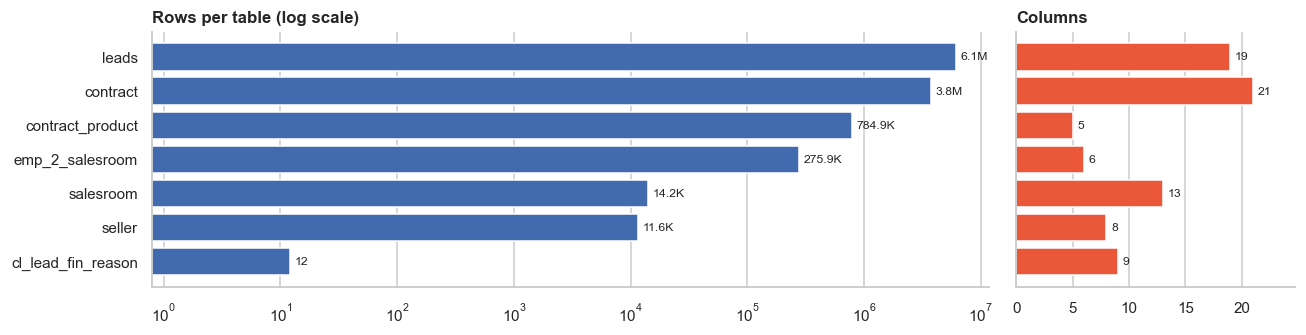

bảng,số dòng,các cột (kiểu)
leads,"6,130,637","id_uuid (VARCHAR), dtime_created (TIMESTAMP), date_assigned (TIMESTAMP), id_lead_source (VARCHAR), text_accepted_by (VARCHAR), skp_employee (VARCHAR), amt_loan_limit (BIGINT), code_pos (VARCHAR), skp_salesroom (BIGINT), code_lead_status (BIGINT), text_contract_number (VARCHAR), text_tenor (VARCHAR), code_sa (VARCHAR), result (DOUBLE), skp_credit_case (BIGINT), skp_client (BIGINT), sample_weight (DOUBLE), code_product_type_original (VARCHAR), code_product_type (VARCHAR)"
contract,"3,775,039","skp_salesroom (BIGINT), skp_credit_case (BIGINT), skp_emp_pre_process (DOUBLE), skp_product (DOUBLE), product (VARCHAR), name_status (VARCHAR), price (DOUBLE), init_pay (DOUBLE), credit_amount (DOUBLE), ins_amount (DOUBLE), payment_num (DOUBLE), skp_client (DOUBLE), date_sign (TIMESTAMP), date_apply (TIMESTAMP), amt_billing_1st (DOUBLE), amt_billing_2nd (DOUBLE), amt_billing_3rd (DOUBLE), dpd_1pd (DOUBLE), dpd_2pd (DOUBLE), dpd_3pd (DOUBLE), dpd_4pd (DOUBLE)"
contract_product,"784,902","skp_credit_case (BIGINT), name_producer (VARCHAR), name_goods_category (VARCHAR), name_goods_type (VARCHAR), goods_group (VARCHAR)"
emp_2_salesroom,"275,856","role (VARCHAR), skp_salesroom (BIGINT), skp_employee (BIGINT), dtime_valid_from (TIMESTAMP), dtime_valid_to (TIMESTAMP), code_status (VARCHAR)"
salesroom,"14,231","SKP_SALESROOM (BIGINT), SALESROOM_CATEGORY (VARCHAR), SALESROOM_MODEL (VARCHAR), SALESROOM_PRODUCT (VARCHAR), SALESROOM_STATUS (VARCHAR), SALESROOM_START (TIMESTAMP), SALESROOM_END (TIMESTAMP), SALESROOM_TOWN (VARCHAR), SALESROOM_DISTRICT (VARCHAR), SALESROOM_PROVINCE (VARCHAR), SALESROOM_AREA (VARCHAR), SKP_EMP_MANAGE (BIGINT), SKP_SELLER (BIGINT)"
seller,"11,639","SKP_SELLER (BIGINT), SELLER_MODEL (VARCHAR), SELLER_STATUS (VARCHAR), SELLER_ACTIVE_DATE (TIMESTAMP), SELLER_TYPE (VARCHAR), SELLER_PRODUCT (VARCHAR), SELLER_PROVINCE (VARCHAR), SELLER_AREA (VARCHAR)"
cl_lead_fin_reason,12,"SKP_LDS_EMP_FSH_RSN_DICT (BIGINT), CODE_SOURCE_SYSTEM (VARCHAR), ID_SOURCE (BIGINT), DATE_EFFECTIVE (TIMESTAMP_NS), SKP_PROC_INSERTED (BIGINT), SKP_PROC_UPDATED (BIGINT), FLAG_DELETED (VARCHAR), CODE_FINISH (VARCHAR), DESC_DESCRIPTION (VARCHAR)"


In [3]:
ov = []
for t in TABLES:
    n = con.sql(f'SELECT count(*) FROM {t}').fetchone()[0]
    cols = q(f'DESCRIBE {t}')
    ov.append((t, n, len(cols), ', '.join(f'{c} ({ty})' for c, ty in zip(cols.column_name, cols.column_type))))
ov = pd.DataFrame(ov, columns=['bảng', 'số dòng', 'số cột', 'các cột (kiểu)'])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={'width_ratios': [3, 1]})
barh(axes[0], ov['bảng'], ov['số dòng'], 'Số dòng mỗi bảng (thang log)', log=True)
barh(axes[1], ov['bảng'], ov['số cột'], 'Số cột', color=C_ALT, fmt=lambda v: f'{v:.0f}')
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

display(ov[['bảng', 'số dòng', 'các cột (kiểu)']].style.hide(axis='index').format({'số dòng': '{:,}'})
        .set_properties(subset=['các cột (kiểu)'], **{'text-align': 'left', 'white-space': 'normal'}))

### 1.1 Xu hướng theo thời gian
Kiểm tra khoảng thời gian thực có dữ liệu của từng bảng – quyết định cửa sổ phân tích chung.

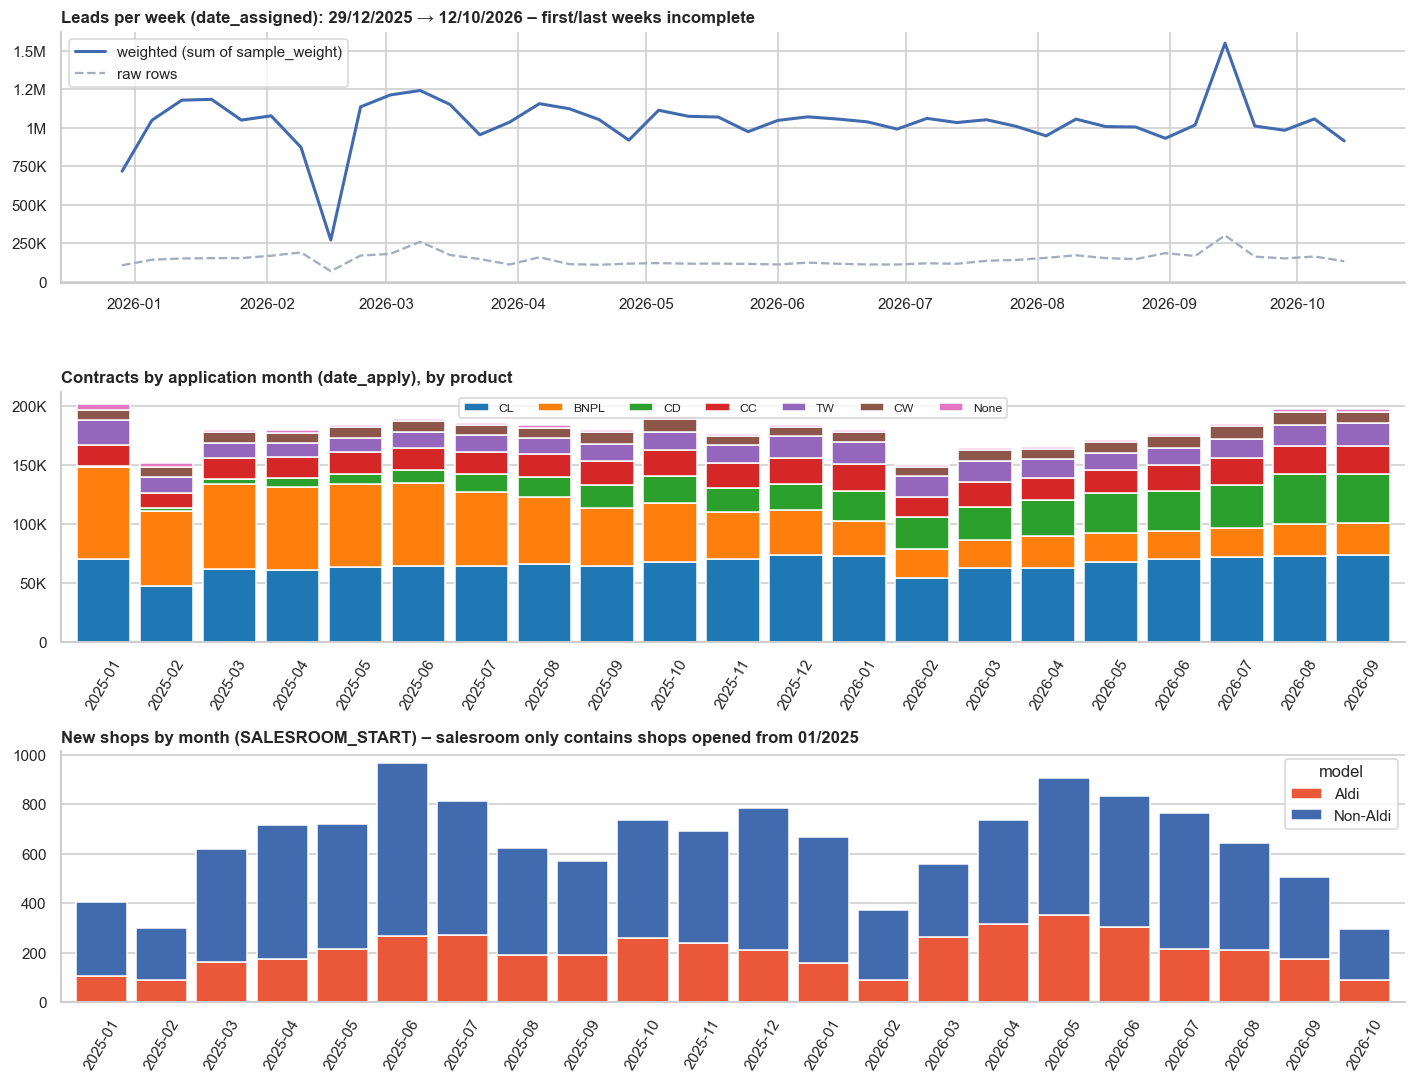

In [4]:
lead_w = q('''SELECT date_trunc('week', date_assigned) tuan, sum(sample_weight) n_w, count(*) n
  FROM leads GROUP BY 1 ORDER BY 1''')
ctr_m = q('''SELECT strftime(date_apply, '%Y-%m') thang, coalesce(product, 'None') product, count(*) n
  FROM contract GROUP BY all''').pivot_table(index='thang', columns='product', values='n', aggfunc='sum').fillna(0)
ctr_m = ctr_m[[p for p in PRODUCTS + ['None'] if p in ctr_m.columns]]
shop_m = q('''SELECT strftime(SALESROOM_START, '%Y-%m') thang, SALESROOM_MODEL model, count(*) n
  FROM salesroom GROUP BY all''').pivot_table(index='thang', columns='model', values='n', aggfunc='sum').fillna(0)

fig, axes = plt.subplots(3, 1, figsize=(13, 10))
ax = axes[0]
ax.plot(lead_w.tuan, lead_w.n_w, color=C_MAIN, lw=2, label='có trọng số (sum sample_weight)')
ax.plot(lead_w.tuan, lead_w.n, color=C_GREY, ls='--', label='số dòng thô')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax.legend()
ax.set_title(f'Lead theo tuần (date_assigned): {lead_w.tuan.min():%d/%m/%Y} → {lead_w.tuan.max():%d/%m/%Y} – tuần đầu/cuối không đủ ngày')

ctr_m.plot(kind='bar', stacked=True, ax=axes[1], width=.85, color=[PCOLOR[c] for c in ctr_m.columns])
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(human)); axes[1].set_xlabel('')
axes[1].set_title('Hợp đồng theo tháng nộp hồ sơ (date_apply), chia theo sản phẩm'); axes[1].legend(ncol=7, fontsize=8)

shop_m.plot(kind='bar', stacked=True, ax=axes[2], width=.85, color=[C_ALT, C_MAIN])
axes[2].set_title('Shop mở mới theo tháng (SALESROOM_START) – salesroom chỉ chứa shop mở từ 01/2025'); axes[2].set_xlabel('')
for a in axes[1:]:
    a.tick_params(axis='x', rotation=60); a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

## 2. Null

Ngoài null thật, dữ liệu dùng nhiều **giá trị giữ chỗ** mang nghĩa “không có”:

| Giá trị | Ý nghĩa thường gặp |
|---|---|
| `XNA` | Not Available |
| `-1` | không có mã (ví dụ `skp_credit_case = -1`: lead chưa thành hồ sơ) |
| `3000-01-01` | ngày chưa xảy ra / còn hiệu lực |
| chuỗi rỗng | thiếu |

Bảng dưới đếm cả hai loại cho từng cột.

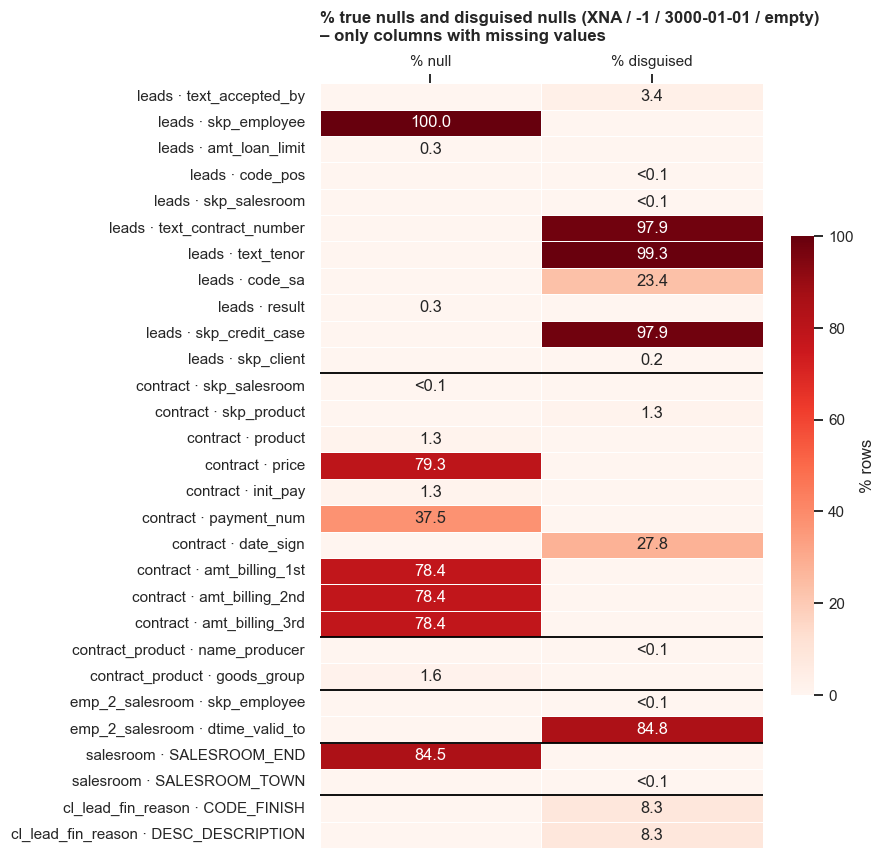

Số cột KHÔNG thiếu / tổng số cột: {'leads': '8/19', 'contract': '11/21', 'contract_product': '3/5', 'emp_2_salesroom': '4/6', 'salesroom': '11/13', 'seller': '8/8', 'cl_lead_fin_reason': '7/9'}


In [5]:
def null_profile(t):
    cols = q(f'DESCRIBE {t}')
    n = con.sql(f'SELECT count(*) FROM {t}').fetchone()[0]
    rows = []
    for c, typ in zip(cols.column_name, cols.column_type):
        col = f'"{c}"'
        if typ == 'VARCHAR':
            fake = f"count(*) FILTER (WHERE trim({col}) IN ('', 'XNA', 'NULL', 'nan', '-1'))"
        elif typ.startswith('TIMESTAMP') or typ == 'DATE':
            fake = f'count(*) FILTER (WHERE year({col}) >= 2999)'
        elif typ in ('BIGINT', 'INTEGER', 'DOUBLE'):
            fake = f'count(*) FILTER (WHERE {col} = -1)'
        else:
            fake = '0'
        r = con.sql(f'SELECT count(*) - count({col}), {fake}, approx_count_distinct({col}) FROM {t}').fetchone()
        rows.append((c, typ, r[0], r[0] / n * 100, r[1], r[1] / n * 100, r[2]))
    return pd.DataFrame(rows, columns=['cột', 'kiểu', 'null', '% null', 'null trá hình', '% trá hình', '~ số giá trị khác nhau'])

def plot_nulls(nulls, title):
    """Heatmap % null / % trá hình – chỉ các cột có thiếu; vạch đen ngăn giữa các bảng."""
    rows = [(f"{t} · {r['cột']}", r['% null'], r['% trá hình'], t)
            for t, d in nulls.items() for _, r in d.iterrows() if r['% null'] > 0 or r['% trá hình'] > 0]
    h = pd.DataFrame(rows, columns=['cột', '% null', '% trá hình', 'bảng']).set_index('cột')
    v = h[['% null', '% trá hình']]
    annot = v.map(lambda x: '' if x == 0 else (f'{x:.1f}' if x >= 0.1 else '<0.1'))
    fig, ax = plt.subplots(figsize=(6.5, 0.27 * len(h) + 1.2))
    sns.heatmap(v, annot=annot, fmt='', cmap='Reds', vmin=0, vmax=100, linewidths=.5, linecolor='white',
                cbar_kws={'label': '% số dòng', 'shrink': .6}, ax=ax)
    b = h['bảng'].values
    for i in range(1, len(b)):
        if b[i] != b[i - 1]:
            ax.axhline(i, color='black', lw=1.2)
    ax.xaxis.tick_top(); ax.set_ylabel(''); ax.set_title(title, pad=28)
    plt.show()
    clean = {t: f"{int(((d['% null'] == 0) & (d['% trá hình'] == 0)).sum())}/{len(d)}" for t, d in nulls.items()}
    print('Số cột KHÔNG thiếu / tổng số cột:', clean)

NULLS = {t: null_profile(t) for t in TABLES}
plot_nulls(NULLS, '% null thật và null trá hình (XNA / -1 / 3000-01-01 / rỗng)\n– chỉ hiện các cột có thiếu')
# xem chi tiết một bảng: display(NULLS['leads'])

In [6]:
# ghi nhận vào bảng tổng hợp: cột thiếu > 5% (null thật hoặc trá hình)
for t, d in NULLS.items():
    for _, r in d.iterrows():
        if r['% null'] >= 5:
            issue(t, 'Null', f"{r['cột']}: {r['% null']:.1f}% null", int(r['null']), '')
        if r['% trá hình'] >= 5:
            issue(t, 'Null trá hình', f"{r['cột']}: {r['% trá hình']:.1f}% là XNA/-1/3000", int(r['null trá hình']), '')

### 2.1 Các cột null đáng chú ý
- `leads.skp_employee`: kiểm tra có trống hoàn toàn không.
- `contract.price`, `payment_num`: null theo sản phẩm (CC/BNPL không có giá món hàng / số kỳ cố định?).
- `contract.amt_billing_*`, `dpd_*`: null theo độ “chín” của hợp đồng (chưa đến kỳ trả).

leads.skp_employee: 0 / 6,130,637 dòng có giá trị  ->  trống hoàn toàn


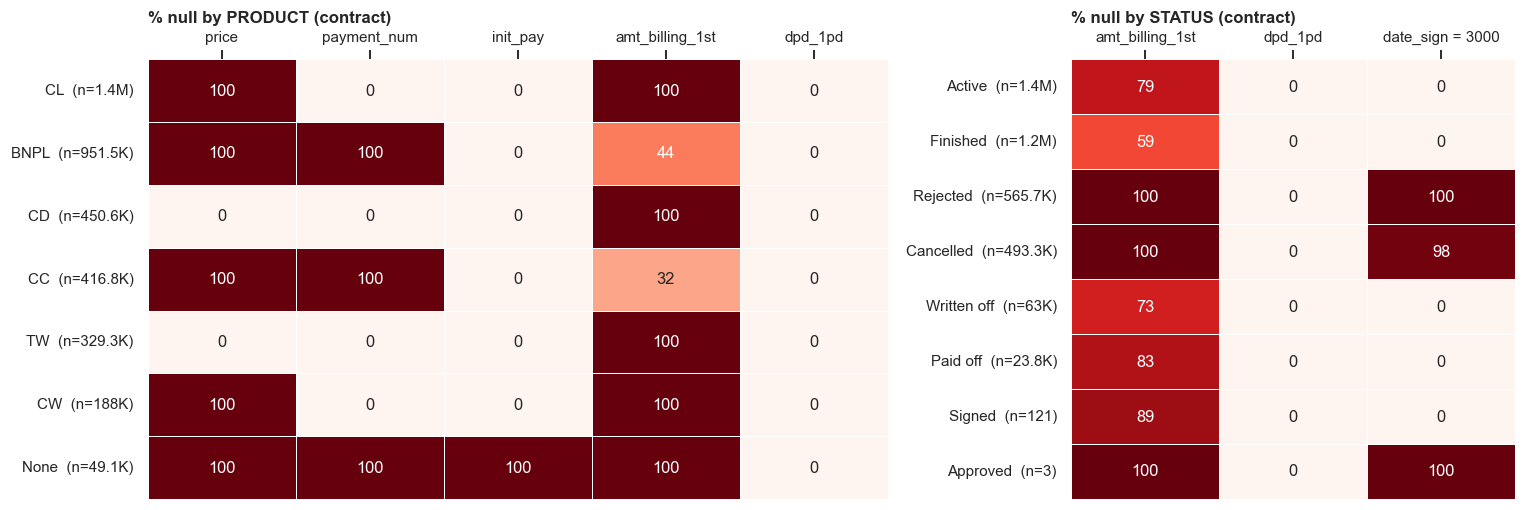

In [7]:
emp = q('SELECT count(*) n, count(skp_employee) non_null_emp, count(code_sa) non_null_sa FROM leads')
print(f"leads.skp_employee: {emp.non_null_emp[0]:,} / {emp.n[0]:,} dòng có giá trị  ->  trống hoàn toàn")

by_prod = q('''SELECT coalesce(product, 'None') product, count(*) n,
    100*avg((price IS NULL)::int) price, 100*avg((payment_num IS NULL)::int) payment_num,
    100*avg((init_pay IS NULL)::int) init_pay, 100*avg((amt_billing_1st IS NULL)::int) amt_billing_1st,
    100*avg((dpd_1pd IS NULL)::int) dpd_1pd
  FROM contract GROUP BY 1 ORDER BY 2 DESC''').set_index('product')
by_status = q('''SELECT name_status, count(*) n, 100*avg((amt_billing_1st IS NULL)::int) amt_billing_1st,
    100*avg((dpd_1pd IS NULL)::int) dpd_1pd, 100*avg((year(date_sign) >= 2999)::int) "date_sign = 3000"
  FROM contract GROUP BY 1 ORDER BY 2 DESC''').set_index('name_status')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [5, 3]})
for ax, d, title in [(axes[0], by_prod, '% null theo SẢN PHẨM (contract)'), (axes[1], by_status, '% null theo TRẠNG THÁI (contract)')]:
    sns.heatmap(d.drop(columns='n'), annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar=False, linewidths=.5, ax=ax)
    ax.set_yticklabels([f'{i}  (n={human(n)})' for i, n in d.n.items()], rotation=0)
    ax.xaxis.tick_top(); ax.set_ylabel(''); ax.set_title(title, pad=24)
plt.tight_layout(); plt.show()

## 3. Duplicated
Hai mức kiểm tra:
- **Trùng toàn dòng**: hai dòng giống hệt nhau ở mọi cột → gần như chắc chắn là lỗi, nên bỏ.
- **Trùng khóa**: cùng khóa chính nhưng khác cột khác → cần hiểu vì sao trước khi xử lý.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

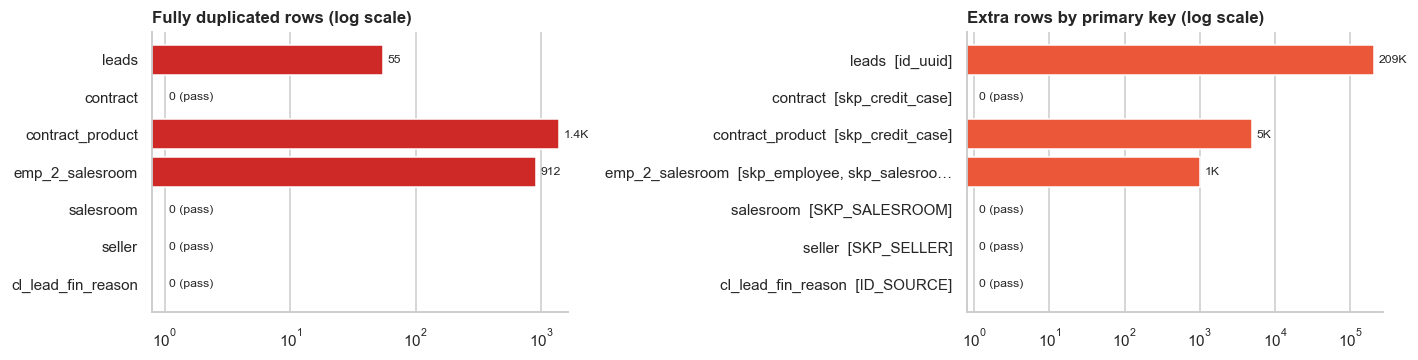

In [8]:
KEYS = {
    'leads': ['id_uuid'],
    'contract': ['skp_credit_case'],
    'contract_product': ['skp_credit_case'],
    'emp_2_salesroom': ['skp_employee', 'skp_salesroom', 'dtime_valid_from'],
    'salesroom': ['SKP_SALESROOM'],
    'seller': ['SKP_SELLER'],
    'cl_lead_fin_reason': ['ID_SOURCE'],
}
dup = []
for t, k in KEYS.items():
    n = con.sql(f'SELECT count(*) FROM {t}').fetchone()[0]
    n_distinct_row = con.sql(f'SELECT count(*) FROM (SELECT DISTINCT * FROM {t})').fetchone()[0]
    kk = ', '.join(k)
    n_key = con.sql(f'SELECT count(*) FROM (SELECT DISTINCT {kk} FROM {t})').fetchone()[0]
    dup.append((t, kk, n, n - n_distinct_row, n - n_key))
    if n - n_distinct_row:
        issue(t, 'Duplicated', 'Trùng toàn dòng', n - n_distinct_row, 'Bỏ dòng trùng (DISTINCT)')
    if n_distinct_row - n_key > 0:
        issue(t, 'Duplicated', f'Trùng khóa ({kk}) nhưng khác nội dung', n_distinct_row - n_key, 'Xem mục 3.1')
dup = pd.DataFrame(dup, columns=['bảng', 'khóa', 'số dòng', 'dòng trùng toàn bộ', 'dòng thừa theo khóa'])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
barh(axes[0], dup['bảng'], dup['dòng trùng toàn bộ'], 'Dòng trùng toàn bộ (thang log)', log=True, color=C_BAD,
     fmt=lambda v: '0 (đạt)' if v == 0 else human(v))
barh(axes[1], dup['bảng'] + '  [' + dup['khóa'] + ']', dup['dòng thừa theo khóa'], 'Dòng thừa theo khóa chính (thang log)',
     log=True, color=C_ALT, fmt=lambda v: '0 (đạt)' if v == 0 else human(v))
plt.tight_layout(); plt.show()

### 3.1 Trùng khóa – khác nhau ở cột nào?

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Không có khóa trùng: ['contract']


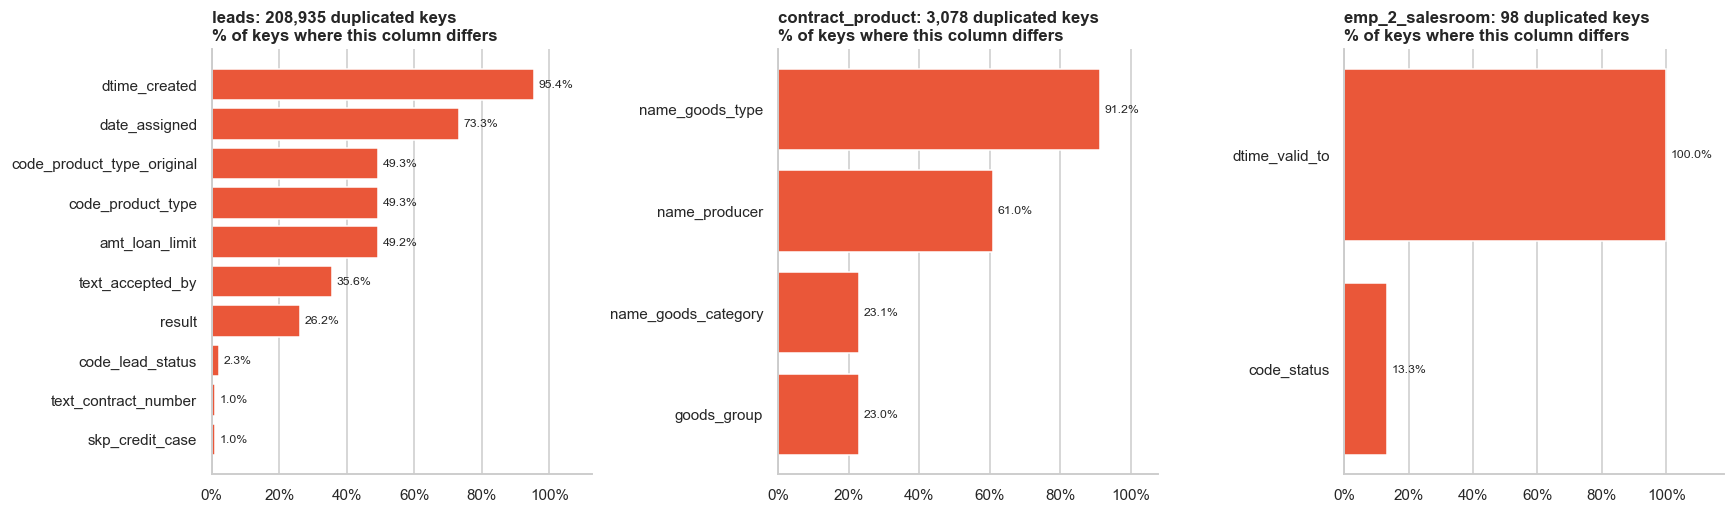

In [9]:
def dup_diff(t, key):
    """Với các khóa bị trùng (sau khi bỏ trùng toàn dòng), đếm số khóa mà từng cột có > 1 giá trị."""
    cols = [c for c in q(f'DESCRIBE {t}').column_name if c not in key]
    kk = ', '.join(key)
    exprs = ', '.join(f'count(*) FILTER (WHERE n_{i} > 1) AS "{c}"' for i, c in enumerate(cols))
    inner = ', '.join(f'count(DISTINCT "{c}") n_{i}' for i, c in enumerate(cols))
    # chỉ xét các khóa xuất hiện > 1 lần (tập nhỏ) để chạy nhanh
    r = q(f'''WITH k AS (SELECT {kk} FROM {t} GROUP BY {kk} HAVING count(*) > 1),
            d AS (SELECT DISTINCT * FROM {t} SEMI JOIN k USING ({kk}))
            SELECT count(*) dup_keys, {exprs} FROM (
            SELECT {kk}, {inner} FROM d GROUP BY {kk} HAVING count(*) > 1)''')
    return r.iloc[0]

DD = {t: dup_diff(t, KEYS[t]) for t in ['leads', 'contract', 'contract_product', 'emp_2_salesroom']}
plot_t = [t for t, s in DD.items() if s['dup_keys'] > 0]
print('Không có khóa trùng:', [t for t in DD if t not in plot_t])
fig, axes = plt.subplots(1, len(plot_t), figsize=(5.3 * len(plot_t), 4.8))
for ax, t in zip(np.atleast_1d(axes), plot_t):
    s = DD[t]; n = s['dup_keys']
    s = (s.drop('dup_keys') / n * 100).sort_values(ascending=False)
    s = s[s > 0]
    barh(ax, s.index, s.values, f'{t}: {n:,} khóa trùng\n% khóa có cột này khác nhau', pct=True, color=C_ALT)
plt.tight_layout(); plt.show()

,id_uuid,dtime_created,date_assigned,id_lead_source,text_accepted_by,skp_employee,amt_loan_limit,code_pos,skp_salesroom,code_lead_status,text_contract_number,text_tenor,code_sa,result,skp_credit_case,skp_client,sample_weight,code_product_type_original,code_product_type
0,92213c2d-1d2c-470e-b157-3d3311cf8764,2026-09-16 05:13:22,2026-09-16 16:00:09,INSTANT_ONE_ALDI,XNA,None,21000000,170443,25883434,4,XNA,XNA,XNA,1.00,-1,1220619,1.00,CCX,CC
1,92213c2d-1d2c-470e-b157-3d3311cf8764,2026-09-06 17:02:05,2026-09-07 08:16:25,INSTANT_ONE_ALDI,262400,None,21000000,170443,25883434,4,XNA,XNA,XNA,1.00,-1,1220619,1.00,CCX,CC


,n_rows,n_ids
0,1,5712656
1,2,208989
2,3,1


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

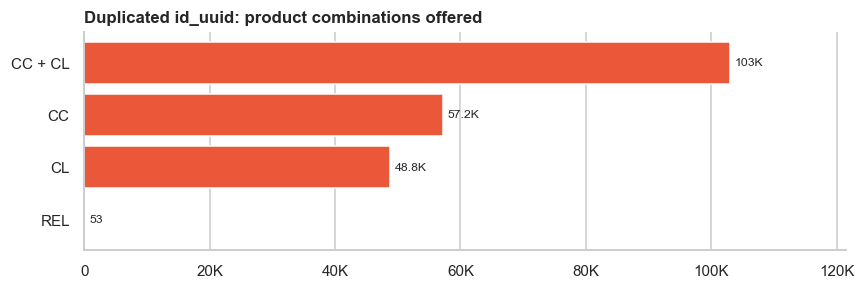

In [10]:
# ví dụ một lead trùng id_uuid
ex = q('''SELECT id_uuid FROM leads GROUP BY 1 HAVING count(*) > 1 LIMIT 1''').id_uuid[0]
display(q(f"SELECT * FROM leads WHERE id_uuid = '{ex}'"))
display(q('''SELECT n_rows, count(*) n_ids FROM (SELECT id_uuid, count(*) n_rows FROM leads GROUP BY 1) GROUP BY 1 ORDER BY 1'''))
# cặp sản phẩm của các id_uuid xuất hiện 2 lần
pairs_prod = q('''SELECT string_agg(code_product_type, ' + ' ORDER BY code_product_type) cap_san_pham, count(*) n
  FROM (SELECT DISTINCT id_uuid, code_product_type FROM leads WHERE id_uuid IN
        (SELECT id_uuid FROM leads GROUP BY 1 HAVING count(*) > 1)) GROUP BY id_uuid''')
pairs_prod = pairs_prod.groupby('cap_san_pham').size().sort_values(ascending=False).head(8)
fig, ax = plt.subplots(figsize=(8, 2.8))
barh(ax, pairs_prod.index, pairs_prod.values, 'id_uuid trùng: tổ hợp sản phẩm được chào', color=C_ALT)
plt.tight_layout(); plt.show()

## 4. Outlier
Với mỗi cột số: phân vị, số giá trị âm / bằng 0, và số giá trị nằm ngoài ngưỡng IQR
(`Q1 − 1.5·IQR`, `Q3 + 1.5·IQR`). Lưu ý: dữ liệu tiền tệ lệch phải rất mạnh nên IQR sẽ “bắt” nhiều điểm —
cần đọc cùng p99 / max để phân biệt **giá trị lớn hợp lý** với **giá trị sai**.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== contract


,cột,n,min,p1,p25,median,p75,p99,max,âm,= 0,ngoài IQR,% ngoài IQR
0,price,779917,"1,000,000.00","3,500,000.00","13,122,000.00","21,500,000.00","38,000,000.00","92,800,000.00","265,000,000.00",0,0,23057,2.96
1,init_pay,3725922,0.00,0.00,0.00,0.00,0.00,"30,000,000.00","245,000,000.00",0,2983050,742872,19.94
2,credit_amount,3775039,0.00,0.00,0.00,"10,000,000.00","24,556,000.00","130,000,000.00","250,000,000.00",0,1137685,205625,5.45
3,ins_amount,3775039,0.00,0.00,0.00,0.00,"478,000.00","11,598,000.00","31,397,800.00",0,2624362,684738,18.14
4,payment_num,2357659,3.00,3.00,9.00,12.00,24.00,48.00,60.00,0,0,40991,1.74
5,amt_billing_1st,815840,0.00,0.00,"250,000.00","950,000.00","3,000,000.00","34,090,549.00","162,940,000.00",0,26165,126005,15.44
6,amt_billing_2nd,815840,0.00,0.00,0.00,0.00,"12,500.00","25,498,007.88","241,790,366.00",0,606641,199896,24.50
7,amt_billing_3rd,815840,0.00,0.00,0.00,0.00,0.00,"24,997,000.00","178,500,000.00",0,654709,161131,19.75
8,dpd_1pd,3775039,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0,3592797,182242,4.83
9,dpd_2pd,3775039,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0,3537888,237151,6.28


=== leads


,cột,n,min,p1,p25,median,p75,p99,max,âm,= 0,ngoài IQR,% ngoài IQR
0,amt_loan_limit,6111265,9.00,"6,000,000.00","20,000,000.00","41,700,000.00","83,900,000.00","246,500,000.00","19,000,000,000.00",0,0,486300,7.96
1,result,6110226,1.00,1.00,1.00,1.00,1.00,7.00,11.00,0,0,806485,13.20
2,sample_weight,6130637,1.00,1.00,1.00,1.00,19.66,19.66,19.66,0,0,0,0.00


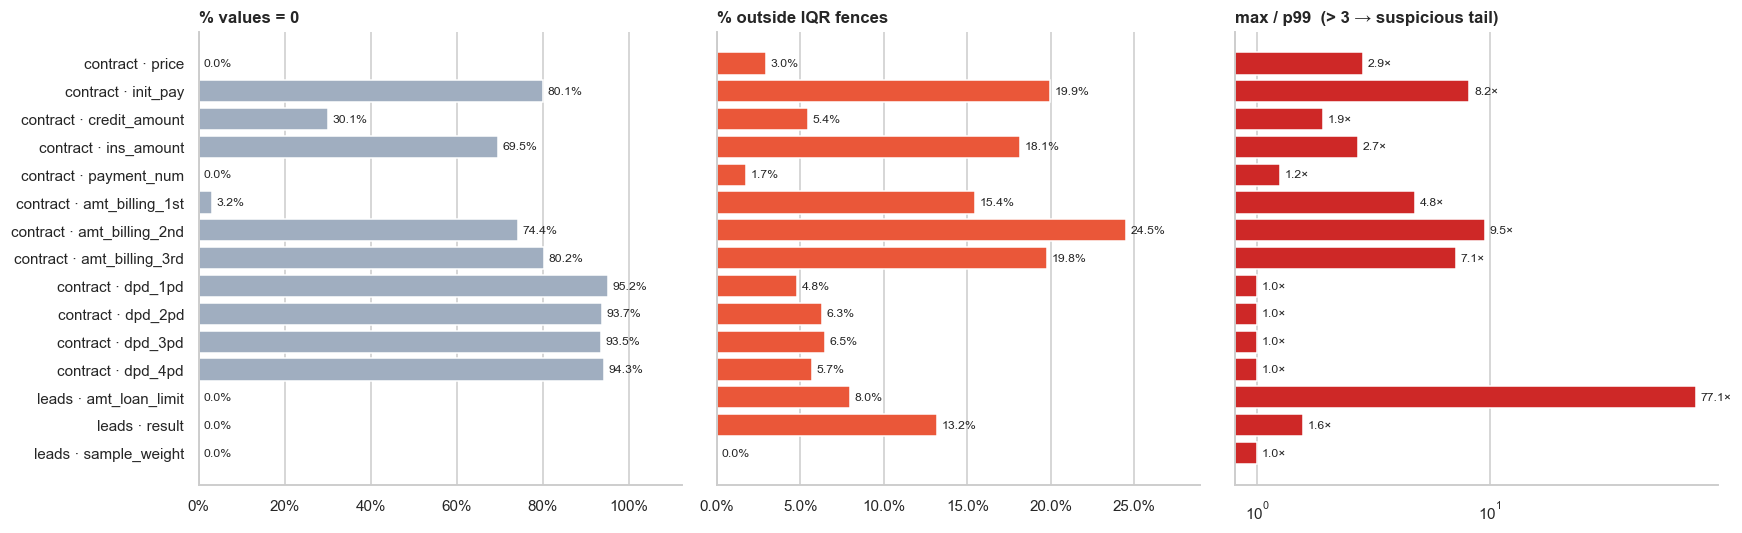

In [11]:
NUM = {
    'contract': ['price', 'init_pay', 'credit_amount', 'ins_amount', 'payment_num',
                 'amt_billing_1st', 'amt_billing_2nd', 'amt_billing_3rd', 'dpd_1pd', 'dpd_2pd', 'dpd_3pd', 'dpd_4pd'],
    'leads': ['amt_loan_limit', 'result', 'sample_weight'],
}
def num_profile(t, cols):
    rows = []
    for c in cols:
        r = con.sql(f'''SELECT count({c}), min({c}), quantile_cont({c}, 0.01), quantile_cont({c}, 0.25), median({c}),
                    quantile_cont({c}, 0.75), quantile_cont({c}, 0.99), max({c}),
                    count(*) FILTER (WHERE {c} < 0), count(*) FILTER (WHERE {c} = 0) FROM {t}''').fetchone()
        q1, q3 = r[3], r[5]
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = con.sql(f'SELECT count(*) FROM {t} WHERE {c} < {lo} OR {c} > {hi}').fetchone()[0]
        rows.append((c, *r, n_out, n_out / max(r[0], 1) * 100))
    return pd.DataFrame(rows, columns=['cột', 'n', 'min', 'p1', 'p25', 'median', 'p75', 'p99', 'max', 'âm', '= 0', 'ngoài IQR', '% ngoài IQR'])

PROF = {t: num_profile(t, cols) for t, cols in NUM.items()}
for t, d in PROF.items():
    print('===', t); display(d)

p = pd.concat([d.assign(bảng=t) for t, d in PROF.items()], ignore_index=True)
p['nhãn'] = p['bảng'] + ' · ' + p['cột']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
barh(axes[0], p['nhãn'], p['= 0'] / p['n'] * 100, '% giá trị = 0', pct=True, color=C_GREY)
barh(axes[1], p['nhãn'], p['% ngoài IQR'], '% nằm ngoài ngưỡng IQR', pct=True, color=C_ALT)
barh(axes[2], p['nhãn'], p['max'] / p['p99'].replace(0, np.nan), 'max / p99  (> 3 → nghi đuôi bất thường)', color=C_BAD,
     log=True, fmt=lambda v: '–' if np.isnan(v) else f'{v:,.1f}×')
for a in axes[1:]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

### 4.1 Số tiền theo sản phẩm (contract) – mỗi sản phẩm có thang giá khác nhau nên phải xét riêng
Boxplot dùng mẫu ngẫu nhiên 400.000 hợp đồng, thang log, chỉ giá trị > 0; tỷ lệ = 0 tính trên toàn bộ dữ liệu.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product,n,p1,p50,p99,max,n_zero,n_neg,median_tenor,max_tenor
0,CL,1389714,"5,000,000.00","21,200,000.00","175,000,000.00","250,000,000.00",0,0,15.00,60.00
1,BNPL,951482,0.00,0.00,"20,000,000.00","50,000,000.00",671787,0,NaN,NaN
2,CD,450582,"2,000,000.00","9,790,000.00","46,000,000.00","100,000,000.00",0,0,6.00,36.00
3,CC,416781,0.00,0.00,0.00,0.00,416781,0,NaN,NaN
4,TW,329335,"7,000,000.00","22,908,000.00","64,243,200.00","80,000,000.00",0,0,12.00,36.00
5,CW,188028,"5,000,000.00","20,000,000.00","50,000,000.00","50,000,000.00",0,0,18.00,38.00
6,None,49117,0.00,0.00,0.00,0.00,49117,0,NaN,NaN


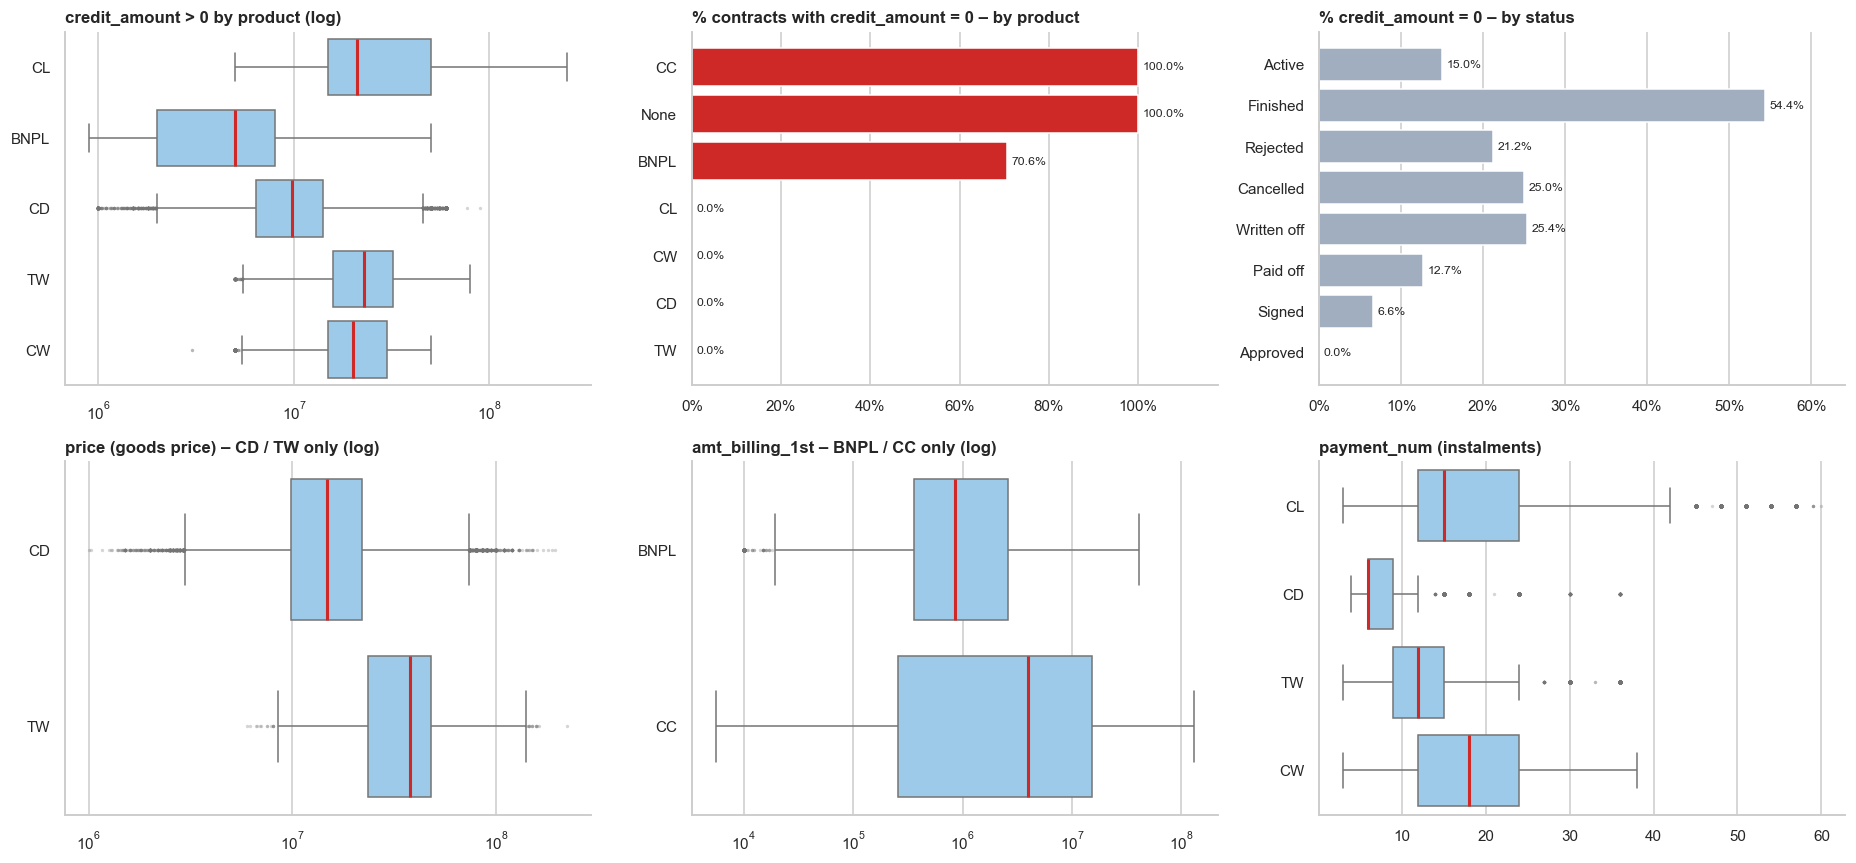

In [12]:
smp = q('''SELECT coalesce(product, 'None') product, credit_amount, price, payment_num, amt_billing_1st
  FROM contract USING SAMPLE 400000 ROWS''')
zero_p = q('''SELECT coalesce(product, 'None') product, 100*avg((credit_amount = 0)::int) pct
  FROM contract GROUP BY 1 ORDER BY pct DESC''')
zero_s = q('''SELECT name_status, count(*) n, 100*avg((credit_amount = 0)::int) pct FROM contract GROUP BY 1 ORDER BY n DESC''')
display(q('''SELECT product, count(*) n,
    quantile_cont(credit_amount, 0.01) p1, median(credit_amount) p50, quantile_cont(credit_amount, 0.99) p99, max(credit_amount) max,
    count(*) FILTER (WHERE credit_amount = 0) n_zero, count(*) FILTER (WHERE credit_amount < 0) n_neg,
    median(payment_num) median_tenor, max(payment_num) max_tenor
  FROM contract GROUP BY 1 ORDER BY 2 DESC'''))

def box(ax, d, col, prods, title, log=True):
    d = d[d['product'].isin(prods) & (d[col] > 0)]
    order = [x for x in prods if x in set(d['product'])]
    sns.boxplot(data=d, y='product', x=col, order=order, log_scale=log, ax=ax, color='#90cdf4', fliersize=1.2,
                flierprops={'alpha': .3}, medianprops={'color': C_BAD, 'lw': 2})
    if not log: ax.xaxis.set_major_formatter(mtick.FuncFormatter(human))
    ax.set_title(title); ax.set_ylabel(''); ax.set_xlabel('')

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
box(axes[0, 0], smp, 'credit_amount', PRODUCTS, 'credit_amount > 0 theo sản phẩm (log)')
barh(axes[0, 1], zero_p['product'], zero_p.pct, '% hợp đồng có credit_amount = 0 – theo sản phẩm', pct=True, color=C_BAD)
barh(axes[0, 2], zero_s.name_status, zero_s.pct, '% credit_amount = 0 – theo trạng thái', pct=True, color=C_GREY)
box(axes[1, 0], smp, 'price', ['CD', 'TW'], 'price (giá món hàng) – chỉ CD / TW (log)')
box(axes[1, 1], smp, 'amt_billing_1st', ['BNPL', 'CC'], 'amt_billing_1st – chỉ BNPL / CC (log)')
box(axes[1, 2], smp, 'payment_num', ['CL', 'CD', 'TW', 'CW'], 'payment_num (số kỳ)', log=False)
for a in axes.flat:
    a.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 4.2 DPD – thực chất là **cờ trễ hạn** kỳ 1–4
`StructureTable` mô tả `dpd_*` là *số ngày trễ*, nhưng dữ liệu chỉ có 0/1 → kiểm tra lại và đọc dưới dạng tỷ lệ.

> Quan sát từ biểu đồ vintage: hợp đồng ký **01–02/2025** gần như không có cờ trễ (≈ 0–4%) trong khi các tháng sau ổn định 5–14%, và các tháng ký gần **09/2026** tụt mạnh vì chưa đến kỳ trả. Khi so rủi ro giữa các shop nên dùng cùng cửa sổ tháng ký (ví dụ 03/2025 – 06/2026).

Các giá trị xuất hiện ở dpd_1pd..dpd_4pd: [0.0, 1.0]


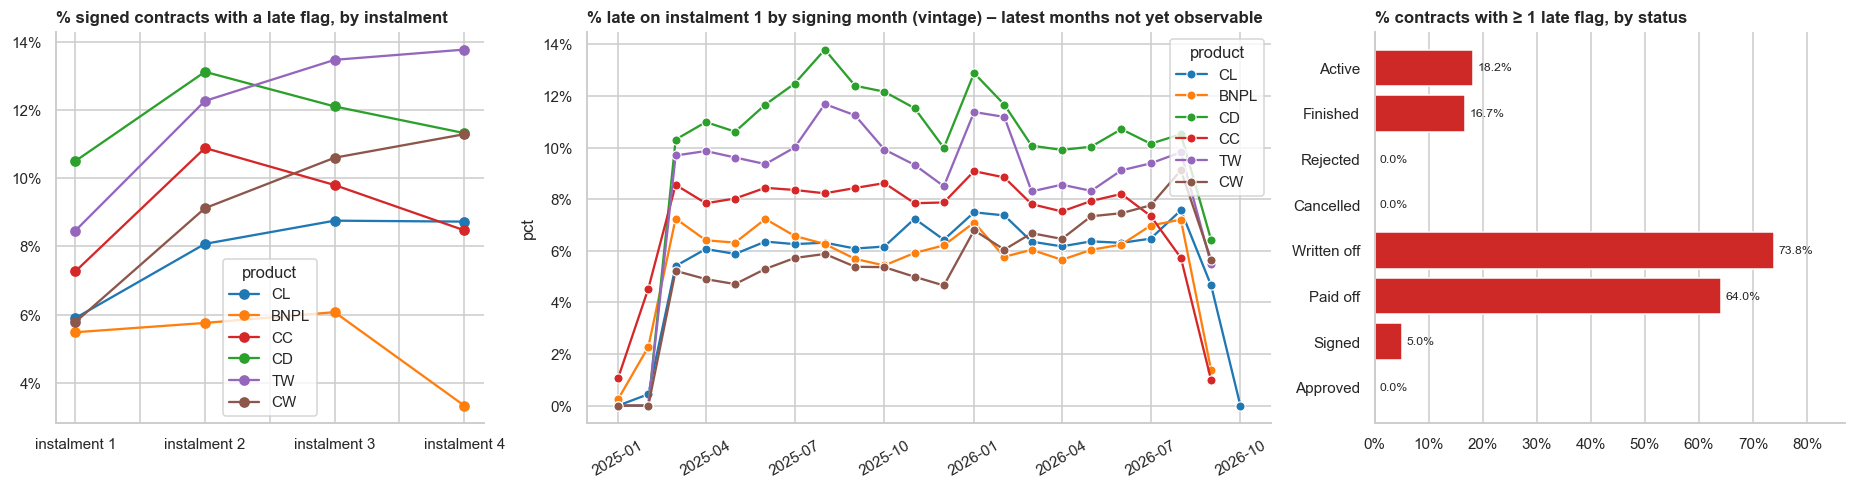

In [13]:
vals = q('SELECT DISTINCT dpd_1pd, dpd_2pd, dpd_3pd, dpd_4pd FROM contract')
print('Các giá trị xuất hiện ở dpd_1pd..dpd_4pd:', sorted(set(pd.unique(vals.values.ravel()))))

dpd = q('''SELECT product, count(*) n, 100*avg(dpd_1pd) "kỳ 1", 100*avg(dpd_2pd) "kỳ 2", 100*avg(dpd_3pd) "kỳ 3", 100*avg(dpd_4pd) "kỳ 4"
  FROM contract WHERE year(date_sign) < 2999 AND product IS NOT NULL GROUP BY 1 ORDER BY n DESC''').set_index('product')
coh = q('''SELECT date_trunc('month', date_sign) thang, product, 100*avg(dpd_1pd) pct, count(*) n
  FROM contract WHERE year(date_sign) < 2999 AND product IS NOT NULL GROUP BY all HAVING count(*) >= 200 ORDER BY 1''')
st = q('''SELECT name_status, count(*) n,
    100*avg((greatest(dpd_1pd, dpd_2pd, dpd_3pd, dpd_4pd) > 0)::int) pct_dpd,
    100*avg((amt_billing_1st > 0)::int) pct_billing FROM contract GROUP BY 1 ORDER BY n DESC''')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1.6, 1.1]})
dpd.drop(columns='n').T.plot(marker='o', ax=axes[0], color=[PCOLOR[c] for c in dpd.index])
axes[0].set_title('% HĐ đã ký có cờ trễ, theo kỳ'); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
sns.lineplot(data=coh, x='thang', y='pct', hue='product', hue_order=[x for x in PRODUCTS if x in set(coh['product'])],
             marker='o', ax=axes[1], palette=PCOLOR)
axes[1].set_title('% trễ kỳ 1 theo tháng ký (vintage) – các tháng gần cuối chưa đủ thời gian quan sát')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=30)
barh(axes[2], st.name_status, st.pct_dpd, '% HĐ có cờ trễ ≥ 1 kỳ, theo trạng thái', pct=True, color=C_BAD)
plt.tight_layout(); plt.show()

> **Lưu ý quan trọng:** `dpd_1pd … dpd_4pd` chỉ nhận giá trị **0 hoặc 1** – đây là **cờ trễ hạn** ở kỳ 1–4,
> *không phải số ngày trễ* như mô tả trong `StructureTable`. Chỉ số rủi ro phải tính dạng tỷ lệ (% hợp đồng trễ kỳ k),
> không tính được mức độ trễ (DPD 10+, 30+…). DPD = 1 chỉ xuất hiện ở hợp đồng đã ký (Active / Finished / Written off / Paid off).

### 4.3 Hạn mức lead (`amt_loan_limit`) theo sản phẩm
Boxplot trên mẫu 300.000 lead; dấu **×** đỏ là min / max thật của toàn bộ dữ liệu.

,code_product_type,n,min,p1,p50,p99,max,n_le0
0,CL,4409471,9,"7,500,000.00","50,000,000.00","250,000,000.00",19000000000,0
1,CC,1245942,5000000,"5,000,000.00","22,000,000.00","50,000,000.00",80000000,0
2,CD,284167,1000000,"8,000,000.00","30,000,000.00","60,000,000.00",60000000,0
3,REL,99219,5000000,"5,000,000.00","24,000,000.00","50,000,000.00",50000000,0
4,TW,91838,5000000,"11,000,000.00","51,000,000.00","80,000,000.00",80000000,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

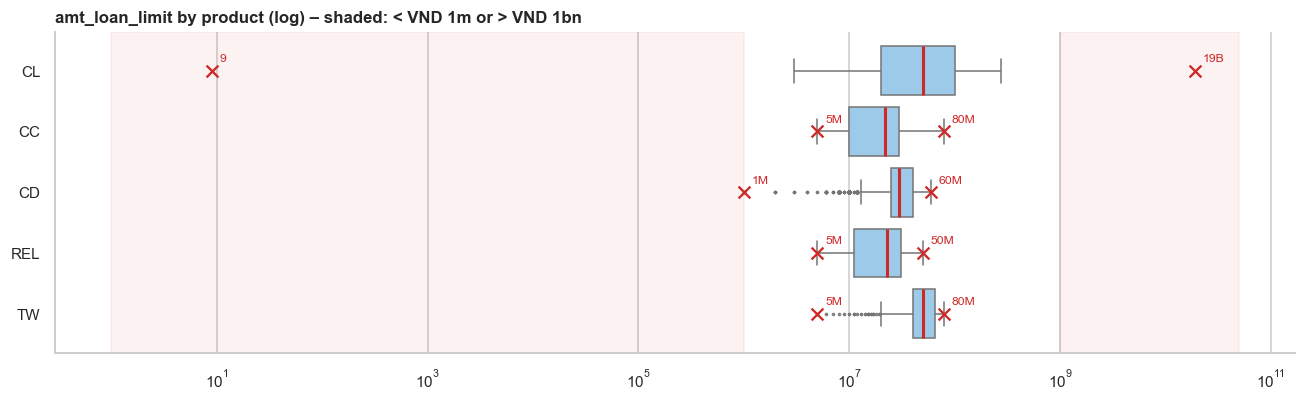

In [14]:
lim = q('''SELECT code_product_type, count(*) n, min(amt_loan_limit) min, quantile_cont(amt_loan_limit, 0.01) p1,
    median(amt_loan_limit) p50, quantile_cont(amt_loan_limit, 0.99) p99, max(amt_loan_limit) max,
    count(*) FILTER (WHERE amt_loan_limit <= 0) n_le0 FROM leads GROUP BY 1 ORDER BY 2 DESC''')
display(lim)
sl = q('SELECT code_product_type, amt_loan_limit FROM leads USING SAMPLE 300000 ROWS')
sl = sl[sl.amt_loan_limit > 0]
fig, ax = plt.subplots(figsize=(12, 3.8))
order = list(lim.code_product_type)
sns.boxplot(data=sl, y='code_product_type', x='amt_loan_limit', order=order, log_scale=True, ax=ax, color='#90cdf4',
            fliersize=1.2, flierprops={'alpha': .3}, medianprops={'color': C_BAD, 'lw': 2})
for i, r in lim.iterrows():
    for v in (r['min'], r['max']):
        ax.scatter(v, i, marker='x', color=C_BAD, s=60, zorder=5)
        ax.annotate(human(v), (v, i), xytext=(5, 6), textcoords='offset points', fontsize=8, color=C_BAD)
ax.axvspan(1, 1e6, color=C_BAD, alpha=.06); ax.axvspan(1e9, 5e10, color=C_BAD, alpha=.06)
ax.set_title('amt_loan_limit theo sản phẩm (log) – vùng đỏ nhạt: < 1 triệu hoặc > 1 tỷ'); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 5. Giá trị phân loại cần quan sát
Top 10 giá trị mỗi cột, tính theo % số dòng. Thanh **đỏ** = giá trị giữ chỗ (`XNA`, `.`, `None`, `-1`).
Riêng `leads` tính **có trọng số** `sample_weight` (vạch đen = % theo số dòng thô, để thấy chênh lệch).

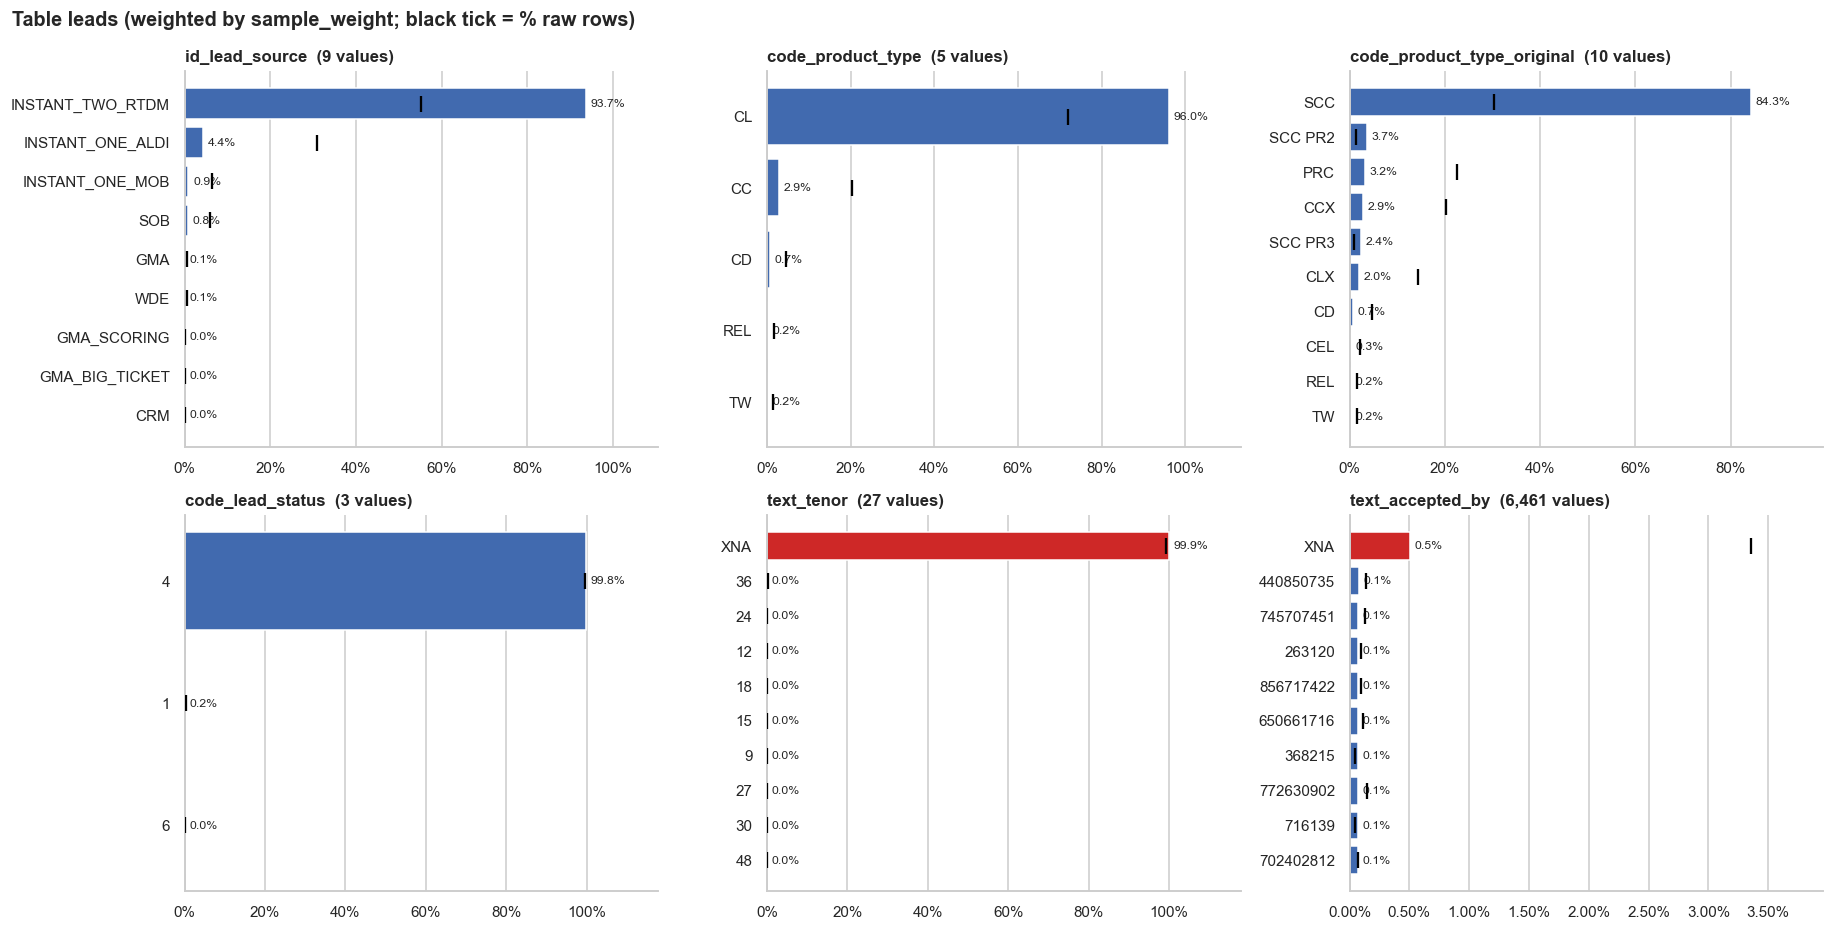

sample_weight ≠ 1 nằm ở đâu:


,id_lead_source,code_product_type,sample_weight,n
0,INSTANT_TWO_RTDM,CL,19.66,2000000


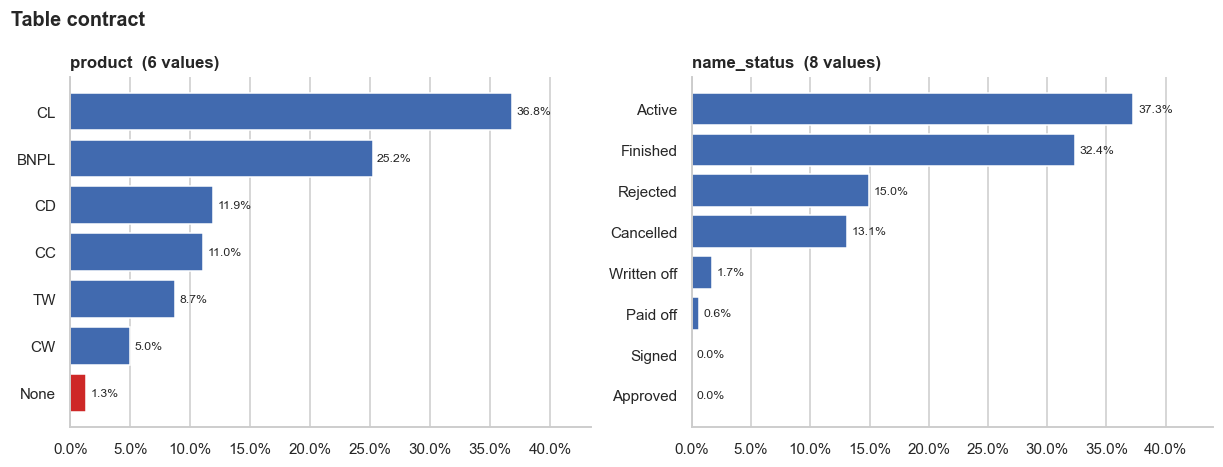

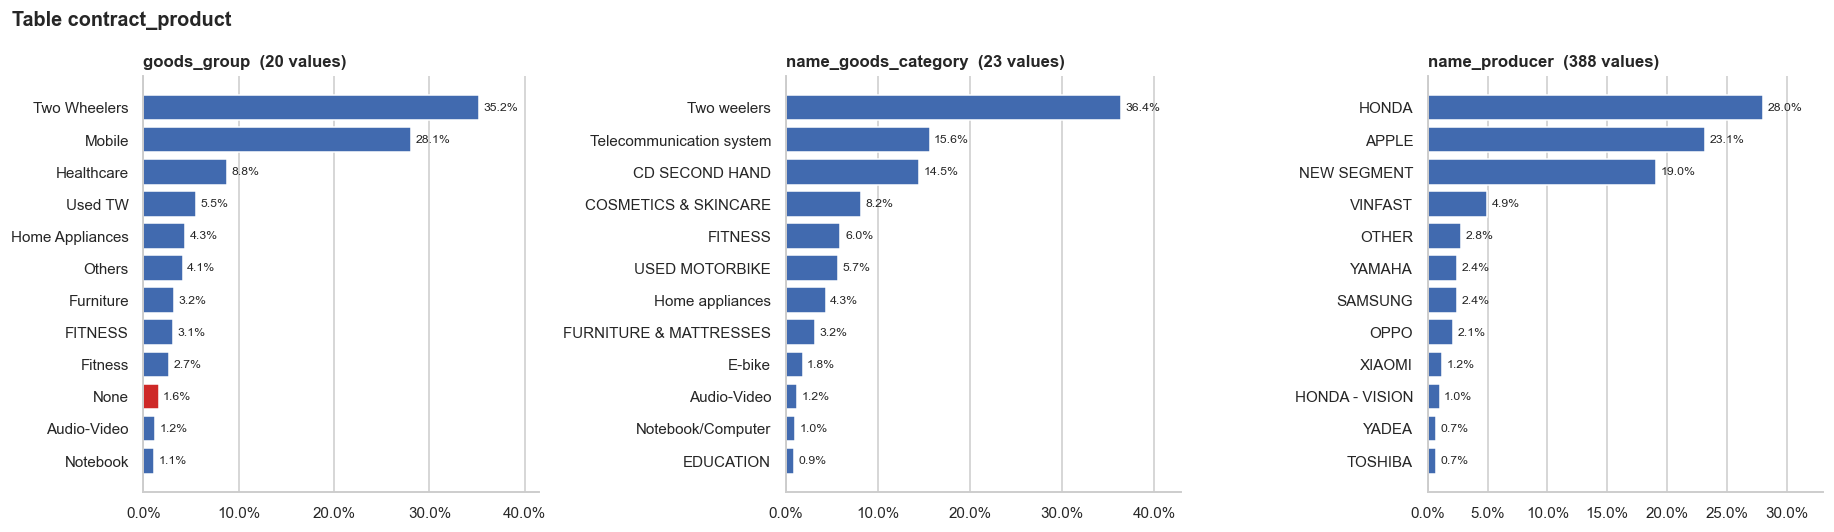

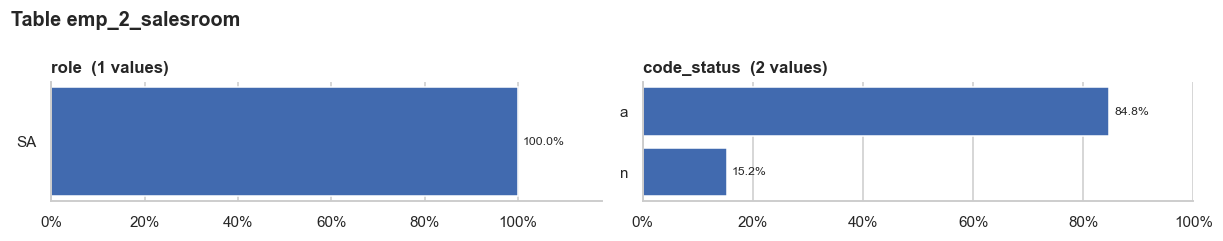

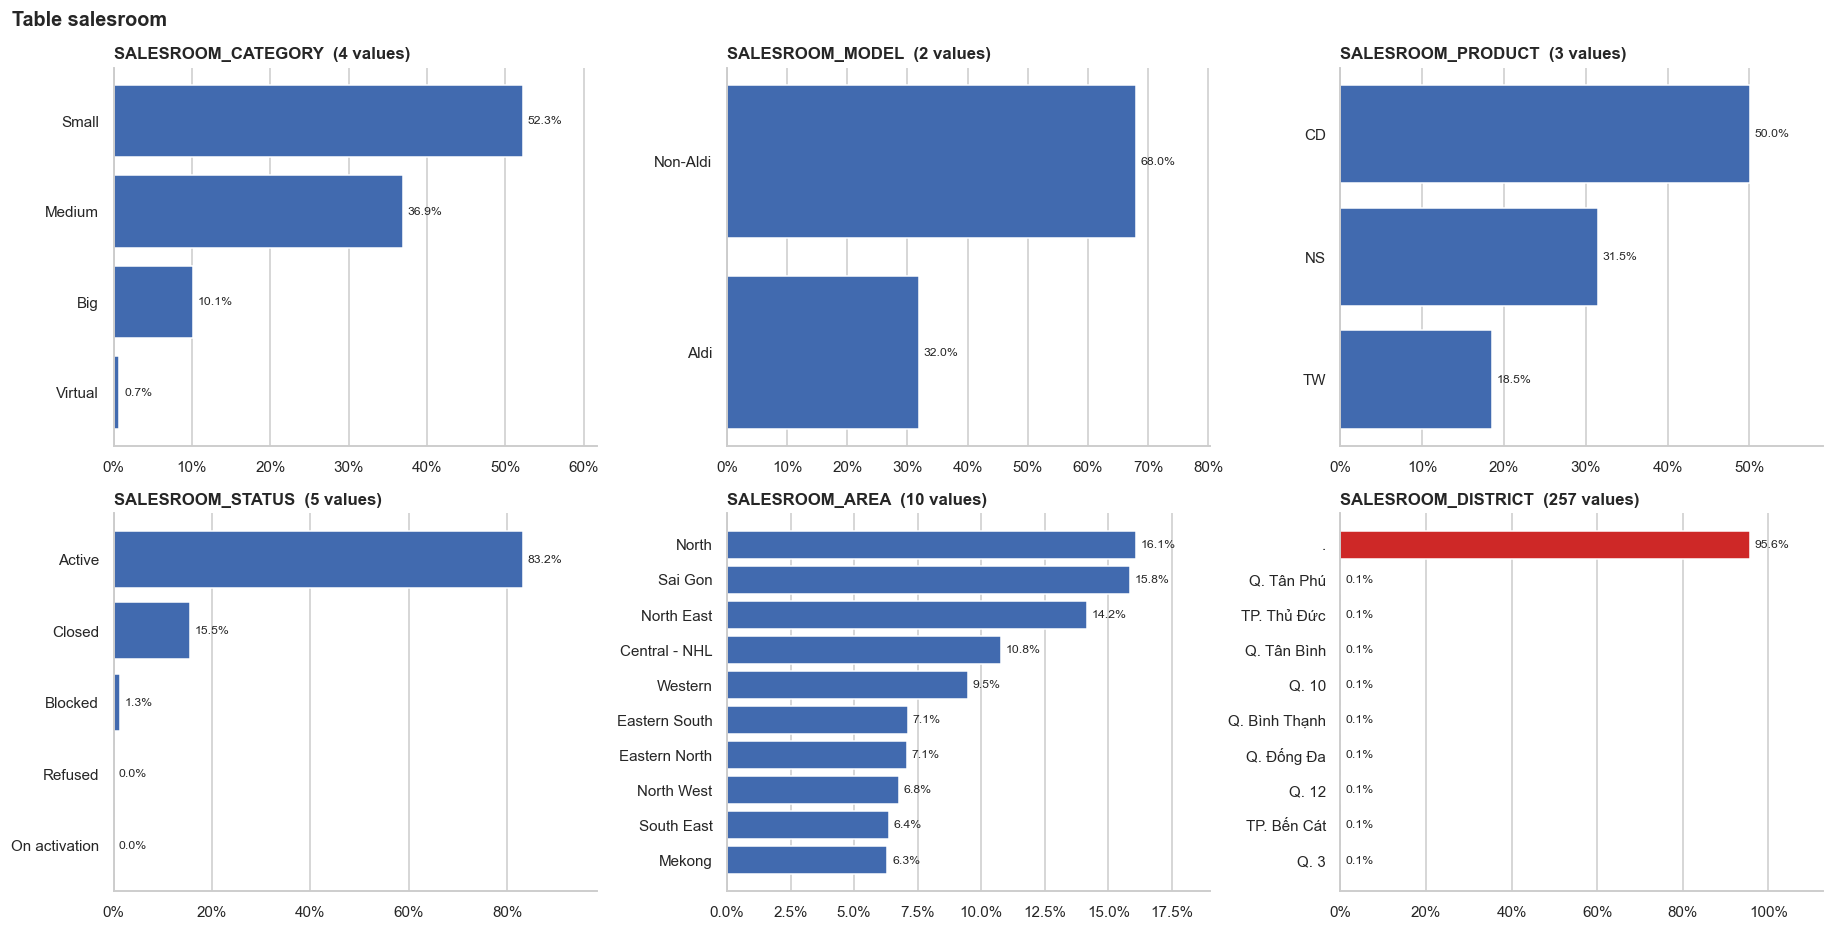

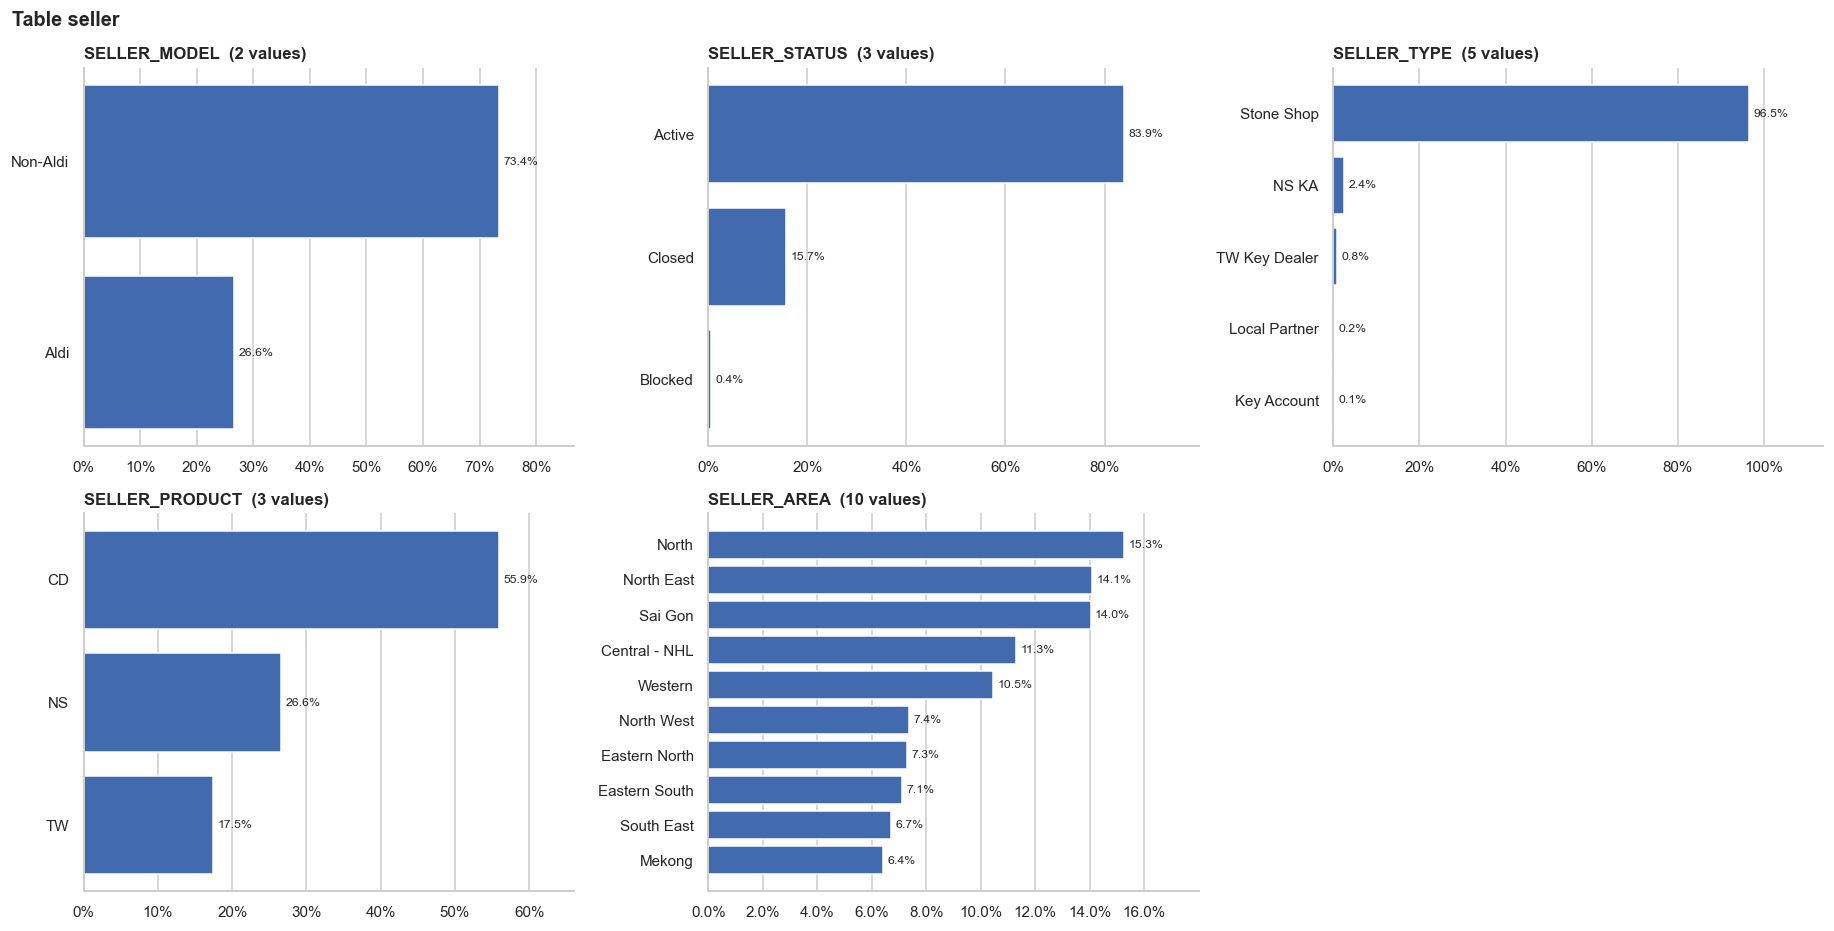

In [15]:
def plot_cats(t, cols, ncols=3, top=10, weight=None, title=None):
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, (0.3 * top + 1.3) * nrows), squeeze=False)
    tot_n, tot_w = con.sql(f"SELECT count(*), {f'sum({weight})' if weight else 'count(*)'} FROM {t}").fetchone()
    for ax, c in zip(axes.flat, cols):
        w = f'sum({weight})' if weight else 'count(*)'
        d = q(f'''SELECT coalesce(CAST("{c}" AS VARCHAR), 'None') v, count(*) n, {w} w FROM {t}
                  GROUP BY 1 ORDER BY w DESC LIMIT {top}''')
        nd = con.sql(f'SELECT count(DISTINCT "{c}") FROM {t}').fetchone()[0]
        barh(ax, d.v, d.w / tot_w * 100, f'{c}  ({nd:,} giá trị)', pct=True, color=colors_for(d.v))
        if weight:
            ax.scatter(d.n / tot_n * 100, np.arange(len(d)), marker='|', color='black', s=120, zorder=4)
    for ax in axes.flat[len(cols):]:
        ax.axis('off')
    fig.suptitle(title or f'Bảng {t}', fontweight='bold', x=0.01, ha='left', fontsize=13)
    plt.tight_layout(); plt.show()

plot_cats('leads', ['id_lead_source', 'code_product_type', 'code_product_type_original', 'code_lead_status', 'text_tenor', 'text_accepted_by'],
          weight='sample_weight', title='Bảng leads (có trọng số sample_weight; vạch đen = % số dòng thô)')
print('sample_weight ≠ 1 nằm ở đâu:')
display(q('''SELECT id_lead_source, code_product_type, sample_weight, count(*) n FROM leads
  WHERE sample_weight <> 1 GROUP BY all ORDER BY n DESC'''))
plot_cats('contract', ['product', 'name_status'], ncols=2)
plot_cats('contract_product', ['goods_group', 'name_goods_category', 'name_producer'], top=12)
plot_cats('emp_2_salesroom', ['role', 'code_status'], ncols=2, top=3)
plot_cats('salesroom', ['SALESROOM_CATEGORY', 'SALESROOM_MODEL', 'SALESROOM_PRODUCT', 'SALESROOM_STATUS', 'SALESROOM_AREA', 'SALESROOM_DISTRICT'])
plot_cats('seller', ['SELLER_MODEL', 'SELLER_STATUS', 'SELLER_TYPE', 'SELLER_PRODUCT', 'SELLER_AREA'])

### 5.1 Đối chiếu `code_lead_status` với từ điển `cl_lead_fin_reason`

,code_lead_status,CODE_FINISH,DESC_DESCRIPTION,n,n_w,pct
0,4,NO_CLUSTER,No Cluster,6110224,"43,378,576.32",99.67
1,1,NOT_INTEREST,Not Interest,20311,"76,166.68",0.33
2,6,EXPIRED_CAMPAIGN,Expired Campaign,102,102.00,0.00


Từ điển cl_lead_fin_reason có các mã: XNA, NOT_INTEREST, EXPIRE_LIFETIME, REPLACED, NO_CLUSTER, EXPIRED_ACCEPTANCE, EXPIRED_CAMPAIGN, DEAL, REJECTED, NOT_APPLICABLE, EXPIRED_OFFER, EXISTING_LEAD_ON_LDS


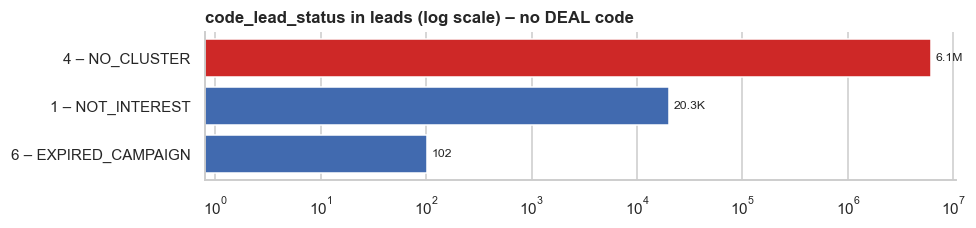

In [16]:
ls_ = q('''SELECT l.code_lead_status, r.CODE_FINISH, r.DESC_DESCRIPTION, count(*) n, sum(sample_weight) n_w,
    round(100*count(*)/sum(count(*)) over (), 2) pct
  FROM leads l LEFT JOIN cl_lead_fin_reason r ON r.ID_SOURCE = l.code_lead_status GROUP BY all ORDER BY n DESC''')
display(ls_)
print('Từ điển cl_lead_fin_reason có các mã:', ', '.join(q('SELECT CODE_FINISH FROM cl_lead_fin_reason ORDER BY ID_SOURCE').CODE_FINISH))
fig, ax = plt.subplots(figsize=(9, 2.2))
barh(ax, ls_.code_lead_status.astype(str) + ' – ' + ls_.CODE_FINISH.fillna('?'), ls_.n,
     'code_lead_status trong leads (thang log) – không có mã DEAL', log=True, color=[C_BAD if c == 'NO_CLUSTER' else C_MAIN for c in ls_.CODE_FINISH])
plt.tight_layout(); plt.show()

### 5.2 Địa giới hành chính trong `salesroom` (trộn địa giới cũ và mới theo NQ 202/2025/QH15)

,dia_gioi_moi,n,n_tinh
0,True,13609,44
1,False,622,52


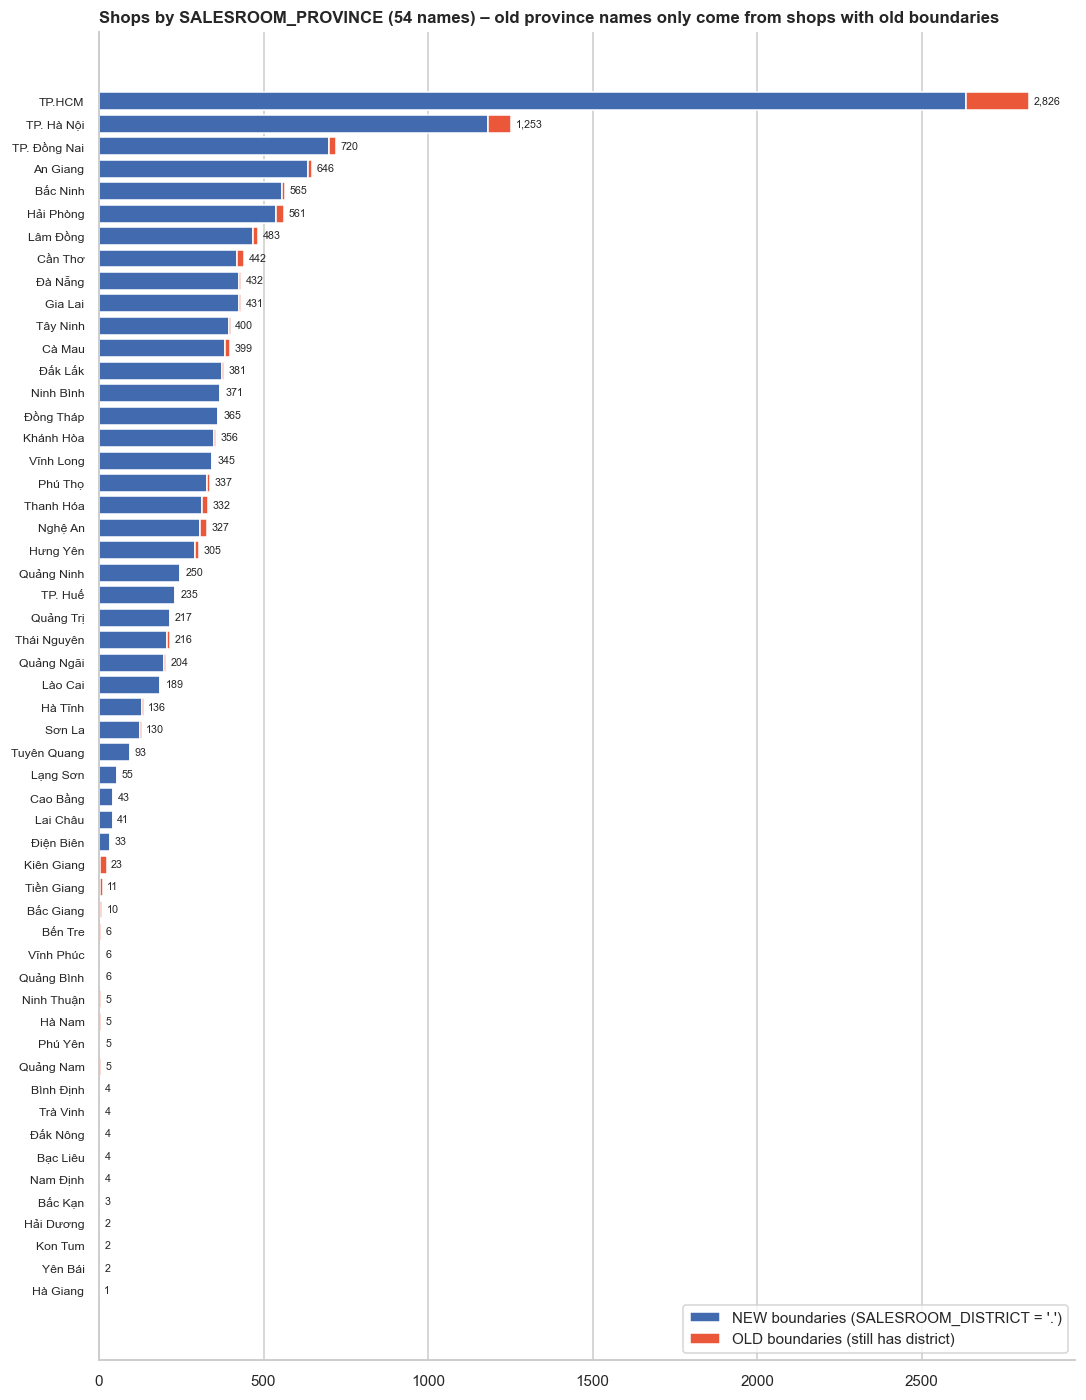

In [17]:
pr = q('''SELECT SALESROOM_PROVINCE p, count(*) FILTER (WHERE SALESROOM_DISTRICT = '.') moi,
    count(*) FILTER (WHERE SALESROOM_DISTRICT <> '.') cu, count(*) n FROM salesroom GROUP BY 1 ORDER BY n DESC''')
display(q('''SELECT (SALESROOM_DISTRICT = '.') AS dia_gioi_moi, count(*) n, count(DISTINCT SALESROOM_PROVINCE) n_tinh
  FROM salesroom GROUP BY 1'''))
fig, ax = plt.subplots(figsize=(10, 0.22 * len(pr) + 1))
y = np.arange(len(pr))
ax.barh(y, pr.moi, color=C_MAIN, label="địa giới MỚI (SALESROOM_DISTRICT = '.')")
ax.barh(y, pr.cu, left=pr.moi, color=C_ALT, label='địa giới CŨ (còn quận/huyện)')
for yi, n in zip(y, pr.n):
    ax.annotate(f'{n:,}', (n, yi), xytext=(3, 0), textcoords='offset points', va='center', fontsize=7)
ax.set_yticks(y, pr.p, fontsize=8); ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.legend(loc='lower right')
ax.set_title(f'Số shop theo SALESROOM_PROVINCE ({len(pr)} tên tỉnh) – tên tỉnh cũ chỉ đến từ shop ghi địa giới cũ')
plt.tight_layout(); plt.show()

## 6. Logic nghiệp vụ

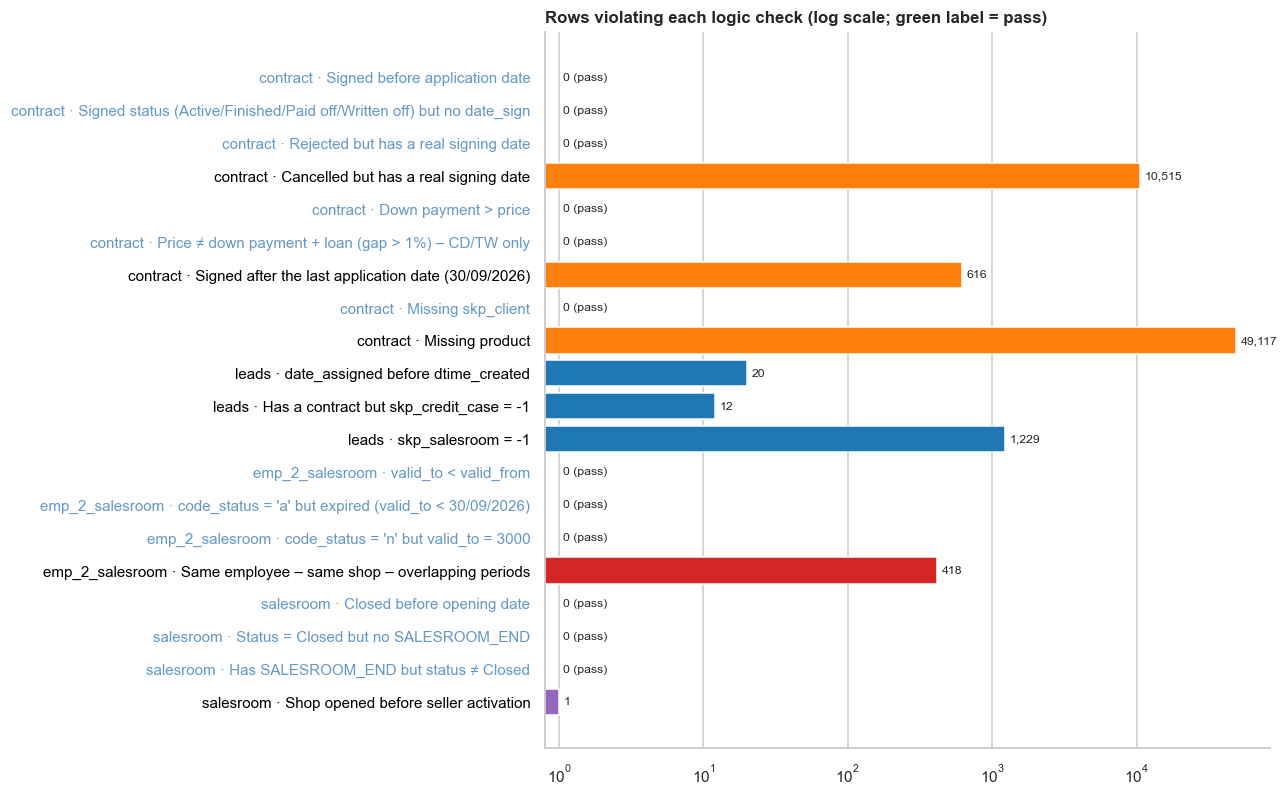

In [18]:
LOGIC = [
    ('contract', 'Ngày ký trước ngày nộp hồ sơ', "SELECT count(*) FROM contract WHERE year(date_sign) < 2999 AND date_sign < date_apply"),
    ('contract', 'Trạng thái đã ký (Active/Finished/Paid off/Written off) nhưng date_sign = 3000',
        "SELECT count(*) FROM contract WHERE name_status IN ('Active','Finished','Paid off','Written off') AND year(date_sign) >= 2999"),
    ('contract', 'Rejected nhưng có ngày ký thật', "SELECT count(*) FROM contract WHERE name_status = 'Rejected' AND year(date_sign) < 2999"),
    ('contract', 'Cancelled nhưng có ngày ký thật', "SELECT count(*) FROM contract WHERE name_status = 'Cancelled' AND year(date_sign) < 2999"),
    ('contract', 'Trả trước > giá món hàng', 'SELECT count(*) FROM contract WHERE init_pay > price AND price > 0'),
    ('contract', 'Giá ≠ trả trước + tiền vay (lệch > 1%) – chỉ CD/TW', "SELECT count(*) FROM contract WHERE product IN ('CD','TW') AND price > 0 AND abs(price - init_pay - credit_amount) > 0.01 * price"),
    ('contract', 'Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026)', "SELECT count(*) FROM contract WHERE year(date_sign) < 2999 AND date_sign > TIMESTAMP '2026-09-30 23:59:59'"),
    ('contract', 'Thiếu skp_client', 'SELECT count(*) FROM contract WHERE skp_client IS NULL'),
    ('contract', 'Thiếu product', 'SELECT count(*) FROM contract WHERE product IS NULL'),
    ('leads', 'date_assigned trước dtime_created', 'SELECT count(*) FROM leads WHERE date_assigned < dtime_created'),
    ('leads', 'Có số hợp đồng nhưng skp_credit_case = -1', "SELECT count(*) FROM leads WHERE text_contract_number <> 'XNA' AND skp_credit_case = -1"),
    ('leads', 'skp_salesroom = -1', 'SELECT count(*) FROM leads WHERE skp_salesroom = -1'),
    ('emp_2_salesroom', 'valid_to < valid_from', 'SELECT count(*) FROM emp_2_salesroom WHERE dtime_valid_to < dtime_valid_from'),
    ('emp_2_salesroom', "code_status = 'a' nhưng đã hết hạn (valid_to < 30/09/2026)", "SELECT count(*) FROM emp_2_salesroom WHERE code_status = 'a' AND dtime_valid_to < TIMESTAMP '2026-09-30'"),
    ('emp_2_salesroom', "code_status = 'n' nhưng valid_to = 3000", "SELECT count(*) FROM emp_2_salesroom WHERE code_status = 'n' AND year(dtime_valid_to) >= 2999"),
    ('emp_2_salesroom', 'Cùng nhân viên – cùng shop – các giai đoạn chồng lấn nhau',
        '''SELECT count(*) FROM emp_2_salesroom a JOIN emp_2_salesroom b ON a.skp_employee = b.skp_employee
           AND a.skp_salesroom = b.skp_salesroom AND a.dtime_valid_from < b.dtime_valid_from AND b.dtime_valid_from < a.dtime_valid_to'''),
    ('salesroom', 'Đóng cửa trước ngày mở', 'SELECT count(*) FROM salesroom WHERE SALESROOM_END < SALESROOM_START'),
    ('salesroom', 'Status = Closed nhưng không có SALESROOM_END', "SELECT count(*) FROM salesroom WHERE SALESROOM_STATUS = 'Closed' AND SALESROOM_END IS NULL"),
    ('salesroom', 'Có SALESROOM_END nhưng status ≠ Closed', "SELECT count(*) FROM salesroom WHERE SALESROOM_END IS NOT NULL AND SALESROOM_STATUS <> 'Closed'"),
    ('salesroom', 'Shop mở trước khi seller được kích hoạt',
        'SELECT count(*) FROM salesroom s JOIN seller e USING (SKP_SELLER) WHERE s.SALESROOM_START < e.SELLER_ACTIVE_DATE'),
]
res = []
for t, desc, sql in LOGIC:
    n = con.sql(sql).fetchone()[0]
    res.append((t, desc, n))
    if n:
        issue(t, 'Logic', desc, n, '')
res = pd.DataFrame(res, columns=['bảng', 'kiểm tra', 'số dòng vi phạm'])

tcolor = dict(zip(TABLES, PAL))
fig, ax = plt.subplots(figsize=(12, 0.32 * len(res) + 1))
barh(ax, [f'{t} · {d}' for t, d in zip(res['bảng'], res['kiểm tra'])], res['số dòng vi phạm'],
     'Số dòng vi phạm từng kiểm tra logic (thang log; nhãn xanh lá = đạt)', log=True, maxlen=80,
     color=[tcolor[t] for t in res['bảng']], fmt=lambda v: '0 (đạt)' if v == 0 else f'{v:,.0f}')
for lbl, v in zip(ax.get_yticklabels(), res['số dòng vi phạm']):
    lbl.set_color(C_OK if v == 0 else 'black')
plt.tight_layout(); plt.show()

## 7. Khóa nối giữa các bảng
Tỷ lệ giá trị khóa ở bảng con **tìm thấy** ở bảng cha. Tỷ lệ thấp không hẳn là lỗi
(ví dụ `salesroom` chỉ có shop mở từ 2025), nhưng quyết định phạm vi phân tích.

,quan hệ,"số dòng (bỏ null, -1)",% dòng khớp,số khóa khác nhau,% khóa khớp
0,contract.skp_salesroom → salesroom,3774985,16.46,26654,42.79
1,leads.skp_salesroom → salesroom,6129408,6.29,27379,39.43
2,emp_2_salesroom.skp_salesroom → salesroom,275856,100.00,14140,100.00
3,salesroom.SKP_SELLER → seller,14231,99.89,11653,99.88
4,salesroom.SKP_EMP_MANAGE → emp_2_salesroom,14231,99.69,298,99.66
5,contract_product.skp_credit_case → contract,784902,100.00,779941,100.00
6,contract.skp_credit_case → contract_product,3775039,20.66,3775039,20.66
7,leads.skp_credit_case (≠ -1) → contract,130381,91.89,113837,91.29
8,leads.skp_client → contract,6118049,25.71,3631388,21.83
9,leads.code_lead_status → cl_lead_fin_reason,6130637,100.00,3,100.00


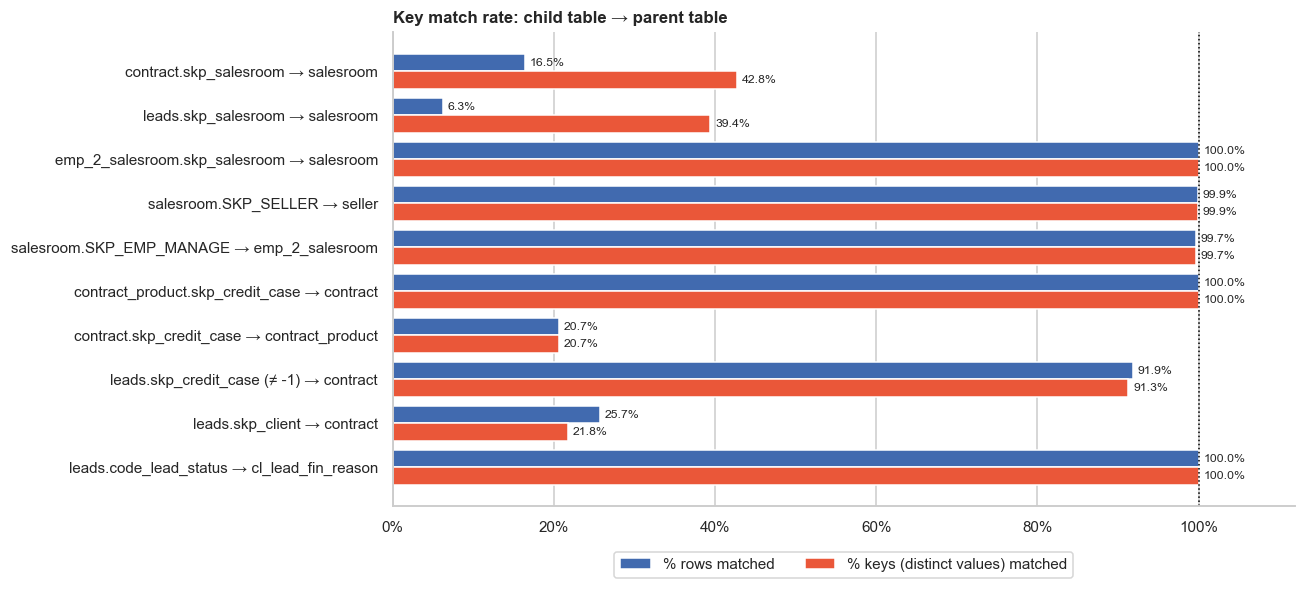

In [19]:
FK = [
    ('contract.skp_salesroom → salesroom', 'contract', 'skp_salesroom', 'salesroom', 'SKP_SALESROOM'),
    ('leads.skp_salesroom → salesroom', 'leads', 'skp_salesroom', 'salesroom', 'SKP_SALESROOM'),
    ('emp_2_salesroom.skp_salesroom → salesroom', 'emp_2_salesroom', 'skp_salesroom', 'salesroom', 'SKP_SALESROOM'),
    ('salesroom.SKP_SELLER → seller', 'salesroom', 'SKP_SELLER', 'seller', 'SKP_SELLER'),
    ('salesroom.SKP_EMP_MANAGE → emp_2_salesroom', 'salesroom', 'SKP_EMP_MANAGE', 'emp_2_salesroom', 'skp_employee'),
    ('contract_product.skp_credit_case → contract', 'contract_product', 'skp_credit_case', 'contract', 'skp_credit_case'),
    ('contract.skp_credit_case → contract_product', 'contract', 'skp_credit_case', 'contract_product', 'skp_credit_case'),
    ('leads.skp_credit_case (≠ -1) → contract', 'leads', 'skp_credit_case', 'contract', 'skp_credit_case'),
    ('leads.skp_client → contract', 'leads', 'skp_client', 'contract', 'skp_client'),
    ('leads.code_lead_status → cl_lead_fin_reason', 'leads', 'code_lead_status', 'cl_lead_fin_reason', 'ID_SOURCE'),
]
rows = []
for name, ct, cc, pt, pc in FK:
    r = con.sql(f'''SELECT count(*) n, count(p.k) hit, count(DISTINCT c.{cc}) nd, count(DISTINCT c.{cc}) FILTER (WHERE p.k IS NOT NULL) nd_hit
        FROM {ct} c LEFT JOIN (SELECT DISTINCT {pc} k FROM {pt}) p ON p.k = c.{cc}
        WHERE c.{cc} IS NOT NULL AND c.{cc} <> -1''').fetchone()
    rows.append((name, r[0], r[1] / r[0] * 100, r[2], r[3] / r[2] * 100))
fk = pd.DataFrame(rows, columns=['quan hệ', 'số dòng (bỏ null, -1)', '% dòng khớp', 'số khóa khác nhau', '% khóa khớp'])
display(fk)

fig, ax = plt.subplots(figsize=(12, 5.5))
y = np.arange(len(fk)); h = .4
ax.barh(y - h / 2, fk['% dòng khớp'], h, color=C_MAIN, label='% dòng khớp')
ax.barh(y + h / 2, fk['% khóa khớp'], h, color=C_ALT, label='% khóa (giá trị khác nhau) khớp')
for yi, a, b in zip(y, fk['% dòng khớp'], fk['% khóa khớp']):
    ax.annotate(f'{a:.1f}%', (a, yi - h / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8)
    ax.annotate(f'{b:.1f}%', (b, yi + h / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8)
ax.set_yticks(y, fk['quan hệ']); ax.invert_yaxis(); ax.set_xlim(0, 112); ax.axvline(100, color='black', ls=':', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.08), ncol=2); ax.set_title('Độ khớp khóa nối bảng con → bảng cha')
plt.tight_layout(); plt.show()

,n_contract,n_shop,credit_ty_dong
shop_trong_salesroom,,,
False,3153684,15249,"62,495.33"
True,621355,11405,"8,100.29"


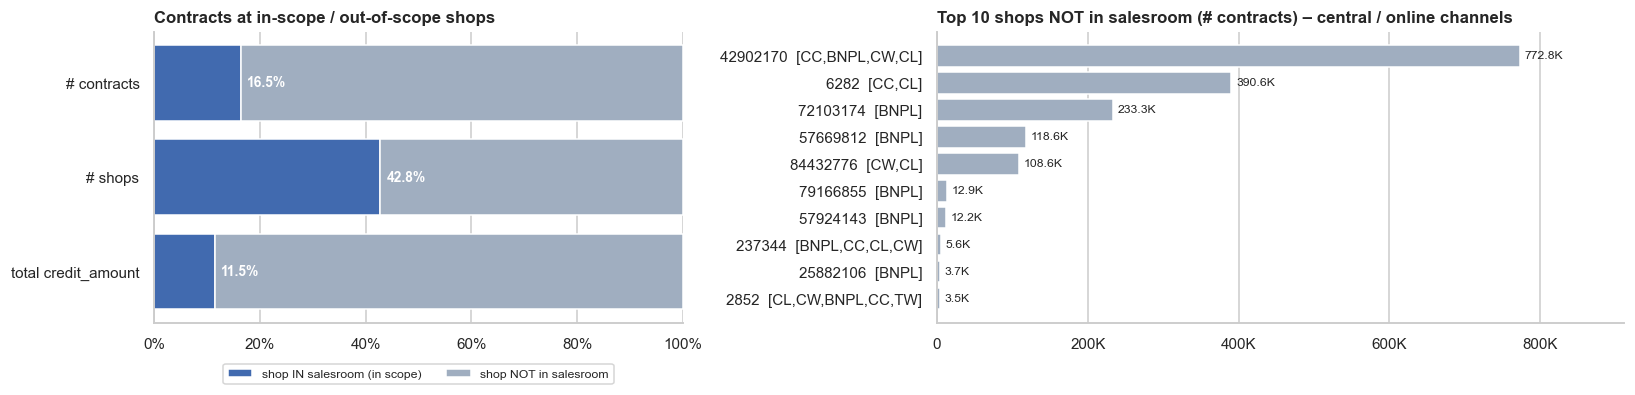

In [20]:
# contract theo shop có / không có trong salesroom – phần không có chiếm bao nhiêu volume?
sc = q('''SELECT (s.SKP_SALESROOM IS NOT NULL) shop_trong_salesroom, count(*) n_contract, count(DISTINCT c.skp_salesroom) n_shop,
    sum(credit_amount)/1e9 credit_ty_dong
  FROM contract c LEFT JOIN salesroom s ON s.SKP_SALESROOM = c.skp_salesroom GROUP BY 1''').set_index('shop_trong_salesroom')
display(sc)
top = q('''SELECT c.skp_salesroom, count(*) n, string_agg(DISTINCT product, ',') products
  FROM contract c WHERE c.skp_salesroom NOT IN (SELECT SKP_SALESROOM FROM salesroom) GROUP BY 1 ORDER BY 2 DESC LIMIT 10''')

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
share = (sc / sc.sum() * 100).T.rename(index={'n_contract': 'số hợp đồng', 'n_shop': 'số shop', 'credit_ty_dong': 'tổng credit_amount'})
yy = np.arange(len(share))
axes[0].barh(yy, share[True], color=C_MAIN, label='shop CÓ trong salesroom (phạm vi)')
axes[0].barh(yy, share[False], left=share[True], color=C_GREY, label='shop KHÔNG có trong salesroom')
for yi, v in zip(yy, share[True]):
    axes[0].annotate(f'{v:.1f}%', (v, yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color='white', fontweight='bold')
axes[0].set_yticks(yy, share.index); axes[0].invert_yaxis(); axes[0].set_xlim(0, 100)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='upper center', bbox_to_anchor=(.5, -.12), ncol=2, fontsize=8); axes[0].set_title('Hợp đồng nằm ở shop trong / ngoài phạm vi')
barh(axes[1], top.skp_salesroom.astype(str) + '  [' + top.products + ']', top.n,
     'Top 10 shop KHÔNG có trong salesroom (số hợp đồng) – kênh trung tâm / online', color=C_GREY)
plt.tight_layout(); plt.show()

### 7.1 Quy tắc nối lead → hợp đồng của đề

Một lead được nối với một hợp đồng khi thỏa **cả 3 tiêu chí**:
1. **Cùng `skp_client`**
2. **Cùng sản phẩm** (`leads.code_product_type` = `contract.product`)
3. **Thời điểm giao lead ≤ thời điểm đăng ký hợp đồng**

Tiêu chí 3 có hai cách hiểu: so với `date_apply` (nộp hồ sơ) hoặc `date_sign` (ký). Để chọn, kiểm tra trên các link **hệ thống đã ghi sẵn** (`leads.skp_credit_case ≠ -1`): link đúng thì phải thỏa quy tắc.

,số link,%
link hệ thống,119802,100.00
1. cùng khách,119733,99.94
2. cùng sản phẩm,118668,99.05
3a. giao ≤ date_apply,69519,58.03
3b. giao ≤ date_sign,88989,74.28
HĐ chưa ký,30117,25.14
giao SAU khi ký,696,0.58


,lead_sp,hd_sp,n
0,REL,CC,821
1,CL,CW,305
2,CC,CL,4
3,CL,CC,4


,id_lead_source,n,tao_sau_apply,giao_sau_apply,giao_sau_ky,phut_tre_tv
0,INSTANT_ONE_MOB,45953,0.05,1.30,0.02,6.00
1,WDE,34445,100.00,100.00,1.23,30.00
2,GMA,12955,97.20,97.36,3.56,20.00
3,INSTANT_TWO_RTDM,12295,0.04,0.13,0.06,"2,126.50"
4,INSTANT_ONE_ALDI,10942,0.60,3.21,0.77,712.00
5,GMA_BIG_TICKET,1165,100.00,100.00,0.22,5.00
6,CRM,748,100.00,100.00,3.65,61.00
7,GMA_SCORING,98,0.00,5.10,0.00,8.00


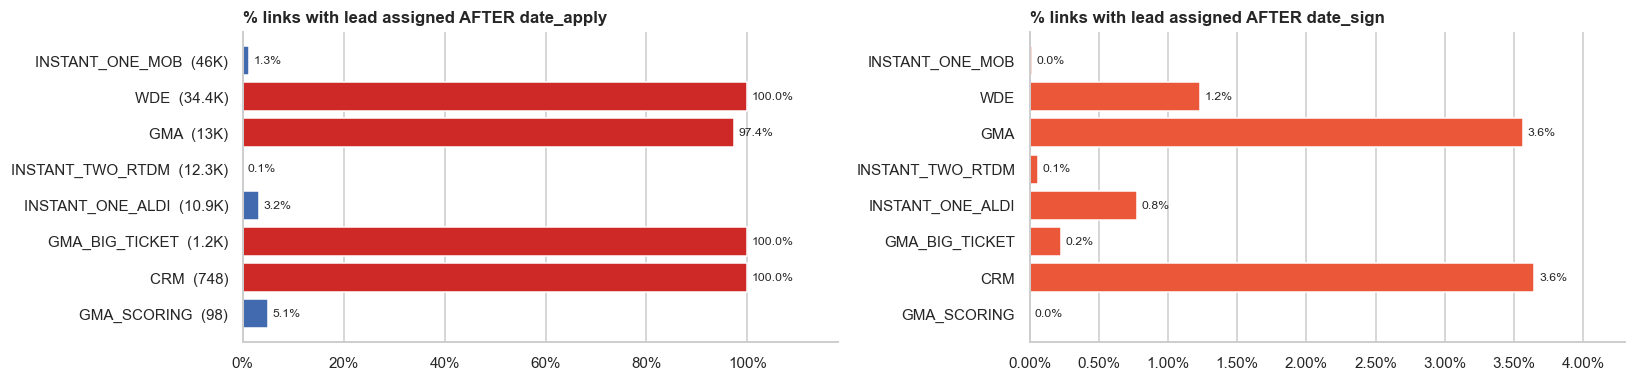

In [21]:
con.sql('''CREATE OR REPLACE TABLE lk AS
SELECT l.id_uuid, l.code_product_type, l.id_lead_source, l.dtime_created, l.date_assigned,
       l.skp_client l_client, c.skp_client c_client, c.product, c.date_apply,
       CASE WHEN year(c.date_sign) < 2999 THEN c.date_sign END date_sign
FROM leads l JOIN contract c USING (skp_credit_case) WHERE l.skp_credit_case <> -1''')
r = q('''SELECT count(*) "link hệ thống",
  count(*) FILTER (WHERE l_client = c_client) "1. cùng khách",
  count(*) FILTER (WHERE code_product_type = product) "2. cùng sản phẩm",
  count(*) FILTER (WHERE date_assigned <= date_apply) "3a. giao ≤ date_apply",
  count(*) FILTER (WHERE date_assigned <= date_sign) "3b. giao ≤ date_sign",
  count(*) FILTER (WHERE date_sign IS NULL) "HĐ chưa ký",
  count(*) FILTER (WHERE date_assigned > date_sign) "giao SAU khi ký"
FROM lk''').T.rename(columns={0: 'số link'})
r['%'] = 100 * r['số link'] / r['số link'].iloc[0]
display(r)
display(q('''SELECT code_product_type lead_sp, product hd_sp, count(*) n FROM lk
             WHERE code_product_type IS DISTINCT FROM product GROUP BY ALL ORDER BY n DESC'''))

# thứ tự thời gian theo nguồn lead (chỉ link cùng khách + cùng sản phẩm)
src_ = q('''SELECT id_lead_source, count(*) n,
  100 * avg((dtime_created > date_apply)::INT) tao_sau_apply,
  100 * avg((date_assigned > date_apply)::INT) giao_sau_apply,
  100 * avg((date_assigned > date_sign)::INT) FILTER (WHERE date_sign IS NOT NULL) giao_sau_ky,
  median(date_diff('minute', date_apply, date_assigned)) FILTER (WHERE date_assigned > date_apply) phut_tre_tv
FROM lk WHERE l_client = c_client AND code_product_type = product GROUP BY 1 ORDER BY n DESC''')
display(src_)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
barh(ax[0], src_.id_lead_source + '  (' + src_.n.map(human) + ')', src_.giao_sau_apply,
     '% link có giờ giao lead SAU date_apply', pct=True, color=[C_BAD if v > 50 else C_MAIN for v in src_.giao_sau_apply])
barh(ax[1], src_.id_lead_source, src_.giao_sau_ky, '% link có giờ giao lead SAU date_sign', pct=True, color=C_ALT)
plt.tight_layout(); plt.show()

n_apply = int(r.loc['link hệ thống', 'số link'] - r.loc['3a. giao ≤ date_apply', 'số link'])
issue('leads', 'Logic', 'Link hệ thống có giờ giao lead > date_apply', n_apply,
      'Không phải lỗi: WDE/GMA/CRM sinh lead SAU khi khách nộp hồ sơ → đo 2 hướng (apply / sign), cột lead_flow')
issue('leads', 'Logic', 'Link hệ thống khác sản phẩm (REL→CC, CL→CW…)', int(r.loc['link hệ thống', 'số link'] - r.loc['2. cùng sản phẩm', 'số link']),
      'REL ghép như CC; CL↔CW không ghép')
issue('leads', 'Logic', 'Link hệ thống: giao lead SAU khi ký', int(r.loc['giao SAU khi ký', 'số link']), 'Loại – vi phạm quy tắc thời gian')

**Kết luận 7.1**
- Tiêu chí 1–2 gần như luôn đúng (sai lệch sản phẩm chủ yếu là `REL` → `CC`: hợp đồng không có mã REL).
- Tiêu chí 3 phụ thuộc **nguồn lead**: với WDE / GMA / GMA_BIG_TICKET / CRM, lead được **tạo sau khi khách đã nộp hồ sơ** (97–100% link) – lead dùng để chăm sóc hồ sơ có sẵn đến lúc ký, không phải tìm khách mới. Các nguồn INSTANT_* thì lead có trước hồ sơ (≈ 99%).
- So với `date_sign`, chỉ vài trăm link vi phạm (giao lead sau khi ký) → đó mới là lỗi thật.

→ Khi làm sạch, tạo bảng `lead_contract_link` đo **2 hướng**, mỗi hướng ghép 1-1, trong 30 ngày:

| Hướng | Điều kiện thời gian | Trả lời câu hỏi | Áp dụng cho |
|---|---|---|---|
| `match_apply` / `converted_apply` | `date_assigned ≤ date_apply` | Lead có **tạo ra hồ sơ mới** không? | `lead_flow = 'ORIGINATION'` |
| `match_sign` / `converted_sign` | `date_assigned ≤ date_sign` (HĐ đã ký) | Lead có **giúp ra hợp đồng ký** không? | Mọi lead, báo cáo tách theo `lead_flow` |

## 8. Biến nhân khẩu học (demographic)

Round 3 **không có bảng khách hàng**. Thông tin mang tính nhân khẩu học chỉ có ở 2 nguồn:

| Nguồn | Biến | Phạm vi |
|---|---|---|
| Round 3 – `salesroom`, `seller` | Phường / quận / tỉnh / vùng của shop và đại lý | 100% shop trong phạm vi |
| Round 2 – `CUSTOMER` | Giới tính, ngày sinh (→ tuổi), học vấn, số con, có xe, tần suất lương, số người phụ thuộc, địa chỉ, số phiên app/tuần | Chỉ khách có mặt ở Round 2 |
| Round 2 – `CONTRACT` | Thu nhập chính / hộ gia đình, loại thu nhập, nghề nghiệp | Chỉ khách có mặt ở Round 2 |

> Lưu ý từ đề Round 2: *“Avoid using demographic factors to determine risk without sufficient evidence or justification.”*

### 8.1 Địa lý shop & đại lý (Round 3)

,n_tinh_shop,n_tinh_seller,n_phuong,town_null,prov_null
0,54,54,2315,0,0


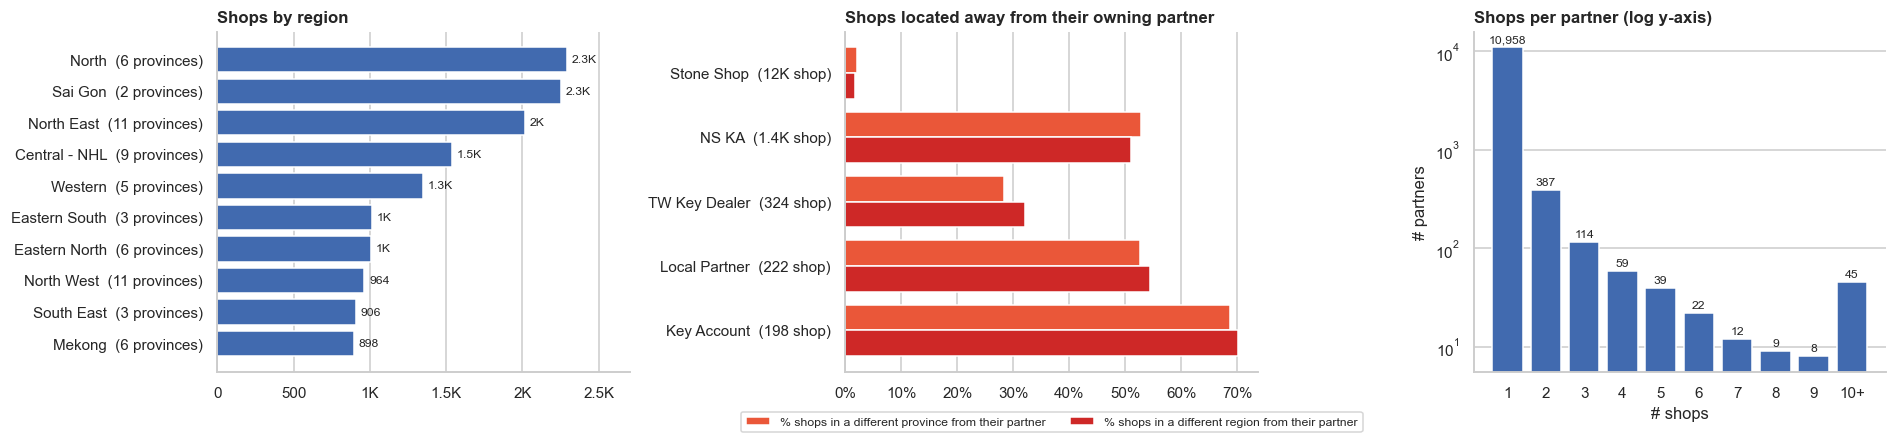

In [22]:
area = q('''SELECT SALESROOM_AREA, count(*) n_shop, count(DISTINCT SALESROOM_PROVINCE) n_tinh FROM salesroom GROUP BY 1 ORDER BY 2 DESC''')
display(q('''SELECT count(DISTINCT SALESROOM_PROVINCE) n_tinh_shop, count(DISTINCT SELLER_PROVINCE) n_tinh_seller,
    count(DISTINCT SALESROOM_TOWN) n_phuong, count(*) FILTER (WHERE SALESROOM_TOWN IS NULL) town_null,
    count(*) FILTER (WHERE SALESROOM_PROVINCE IS NULL) prov_null FROM salesroom, seller WHERE salesroom.SKP_SELLER = seller.SKP_SELLER'''))
# shop nằm khác tỉnh / khác vùng với đại lý sở hữu (đại lý chuỗi có shop nhiều tỉnh là bình thường)
st_ = q('''SELECT e.SELLER_TYPE, count(*) n_shop,
    100*avg((s.SALESROOM_PROVINCE <> e.SELLER_PROVINCE)::int) pct_khac_tinh,
    100*avg((s.SALESROOM_AREA <> e.SELLER_AREA)::int) pct_khac_vung
  FROM salesroom s JOIN seller e USING (SKP_SELLER) GROUP BY 1 ORDER BY 2 DESC''')
# số shop / đại lý
nps = q('''SELECT CASE WHEN k >= 10 THEN '10+' ELSE k::VARCHAR END grp, count(*) n_seller, min(k) kmin
  FROM (SELECT SKP_SELLER, count(*) k FROM salesroom GROUP BY 1) GROUP BY 1 ORDER BY kmin''')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
barh(axes[0], area.SALESROOM_AREA + '  (' + area.n_tinh.astype(str) + ' tỉnh)', area.n_shop, 'Số shop theo vùng')
y = np.arange(len(st_)); h = .4
axes[1].barh(y - h / 2, st_.pct_khac_tinh, h, color=C_ALT, label='% shop khác tỉnh với đại lý')
axes[1].barh(y + h / 2, st_.pct_khac_vung, h, color=C_BAD, label='% shop khác vùng với đại lý')
axes[1].set_yticks(y, st_.SELLER_TYPE + '  (' + st_.n_shop.map(human) + ' shop)'); axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].grid(axis='y', visible=False)
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.1), ncol=2); axes[1].set_title('Shop khác địa bàn với đại lý sở hữu')
axes[2].bar(nps.grp, nps.n_seller, color=C_MAIN); axes[2].set_yscale('log')
for x, v in zip(nps.grp, nps.n_seller):
    axes[2].annotate(f'{v:,}', (x, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
axes[2].set_title('Số shop / đại lý (trục y log)'); axes[2].set_xlabel('số shop'); axes[2].set_ylabel('số đại lý'); axes[2].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

### 8.2 Hồ sơ nhân khẩu học khách hàng (Round 2 `CUSTOMER` + thu nhập / nghề nghiệp từ Round 2 `CONTRACT`)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1000528 khách Round 2


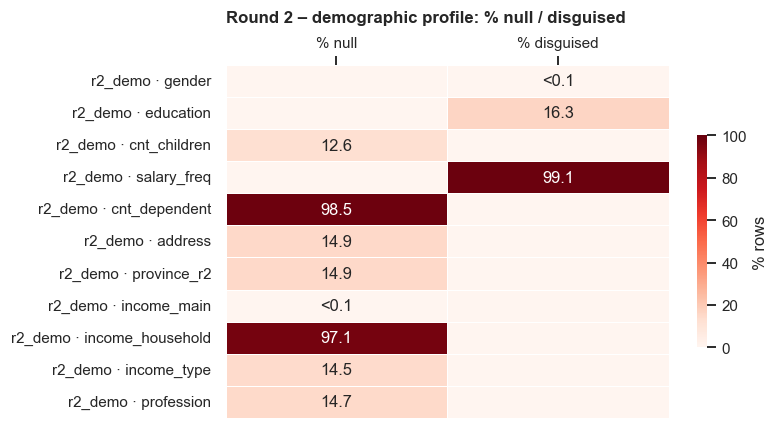

Số cột KHÔNG thiếu / tổng số cột: {'r2_demo': '5/16'}


In [23]:
R2 = pathlib.Path(r'D:/Thi/BI/BI10_ROUND02_DATASET/data')
con.sql(f"""CREATE OR REPLACE TABLE r2_customer AS
  SELECT SKP_CLIENT::BIGINT skp_client, NAME_GENDER gender, NAME_EDUCATION_TYPE education,
         try_cast(DATE_BIRTH AS TIMESTAMP) date_birth,
         date_diff('year', try_cast(DATE_BIRTH AS TIMESTAMP), TIMESTAMP '2025-06-05') age,
         try_cast(CNT_CHILDREN AS INT) cnt_children, FLAG_CAR_OWNER flag_car, NAME_SALARY_FREQUENCY salary_freq,
         try_cast(CNT_PERSON_DEPENDENT AS INT) cnt_dependent, ADDRESS address,
         trim(split_part(ADDRESS, ',', -1)) province_r2,
         try_cast(AVG_SESSION_PER_WEEK_2025 AS DOUBLE) avg_session
  FROM read_csv('{(R2 / 'CUSTOMER.csv').as_posix()}', all_varchar=true, quote='\"')""")
# thu nhập / nghề nghiệp: lấy hồ sơ gần nhất có khai báo của mỗi khách
con.sql(f"""CREATE OR REPLACE TABLE r2_income AS
  SELECT SKP_CLIENT::BIGINT skp_client,
         arg_max(try_cast(AMT_INCOME_MAIN AS DOUBLE), try_cast(APPLY_CONTRACT_TIME AS TIMESTAMP))
             FILTER (WHERE try_cast(AMT_INCOME_MAIN AS DOUBLE) > 0) income_main,
         arg_max(try_cast(AMT_INCOME_HOUSEHOLD AS DOUBLE), try_cast(APPLY_CONTRACT_TIME AS TIMESTAMP))
             FILTER (WHERE try_cast(AMT_INCOME_HOUSEHOLD AS DOUBLE) > 0) income_household,
         arg_max(NAME_INCOME_TYPE, try_cast(APPLY_CONTRACT_TIME AS TIMESTAMP)) FILTER (WHERE NAME_INCOME_TYPE <> 'XNA') income_type,
         arg_max(CODE_PROFESSION, try_cast(APPLY_CONTRACT_TIME AS TIMESTAMP)) FILTER (WHERE CODE_PROFESSION <> 'XNA') profession
  FROM read_csv('{(R2 / 'CONTRACT.csv').as_posix()}', all_varchar=true, quote='\"') GROUP BY 1""")
con.sql('CREATE OR REPLACE TABLE demo AS SELECT * FROM r2_customer LEFT JOIN r2_income USING (skp_client)')
print(con.sql('SELECT count(*) FROM demo').fetchone()[0], 'khách Round 2')
NULLS['r2_demo'] = null_profile('demo')
plot_nulls({'r2_demo': NULLS['r2_demo']}, 'Round 2 – hồ sơ nhân khẩu học: % null / trá hình')

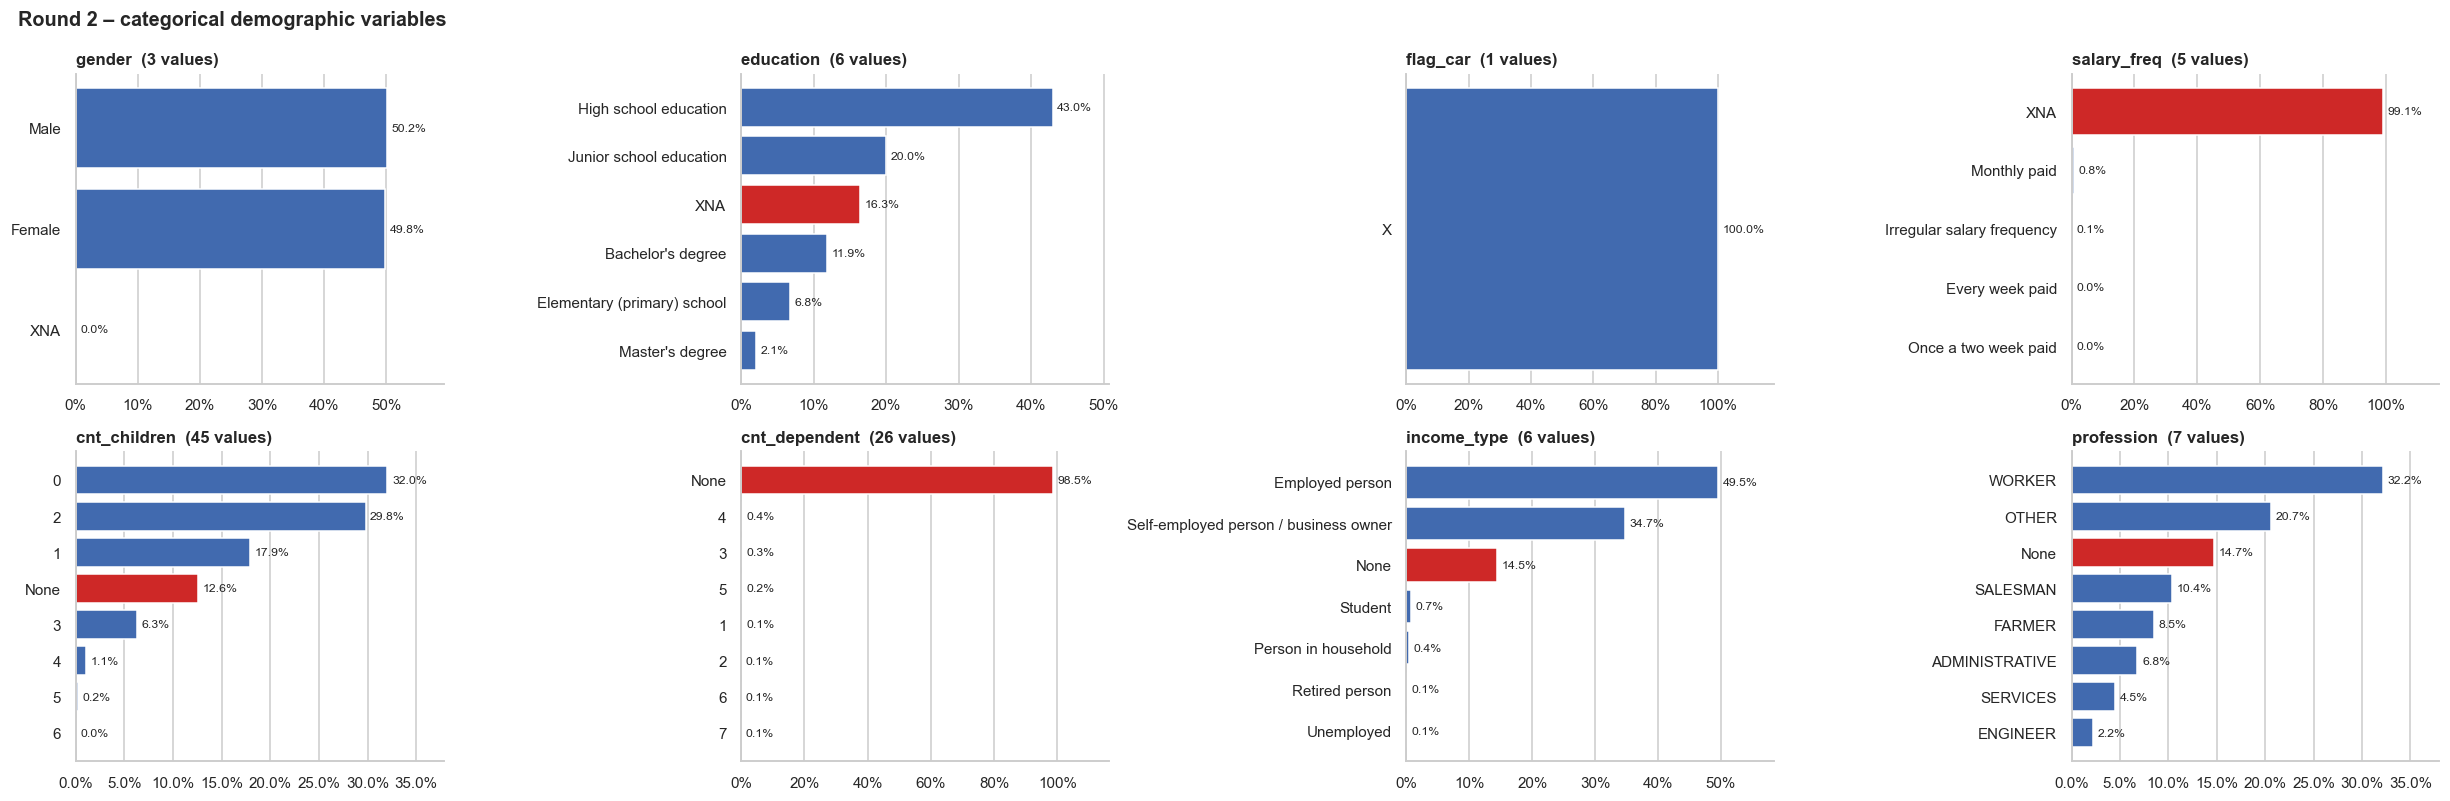

In [24]:
# giá trị phân loại (% tính trên TOÀN BỘ khách, không chỉ top hiển thị)
plot_cats('demo', ['gender', 'education', 'flag_car', 'salary_freq', 'cnt_children', 'cnt_dependent', 'income_type', 'profession'],
          ncols=4, top=8, title='Round 2 – biến nhân khẩu học dạng phân loại')

,cột,n,min,p1,p25,median,p75,p99,max,âm,= 0,ngoài IQR,% ngoài IQR
0,age,1000528,2.00,19.00,29.00,36.00,44.00,59.00,124.00,0,0,40,0.00
1,cnt_children,874457,0.00,0.00,0.00,1.00,2.00,4.00,99.00,0,320538,965,0.11
2,cnt_dependent,14869,0.00,0.00,3.00,4.00,5.00,11.00,47.00,0,260,517,3.48
3,income_main,1000524,1.00,"5,000,000.00","10,000,000.00","12,000,000.00","15,000,000.00","40,000,000.00","900,000,000.00",0,0,57026,5.70
4,income_household,28526,"20,000.00","4,000,000.00","10,000,000.00","12,000,000.00","17,000,000.00","40,000,000.00","3,000,000,000.00",0,0,1629,5.71
5,avg_session,1000528,0.00,0.00,0.00,0.00,0.00,1.73,37.73,0,930051,70477,7.04


,tuoi_duoi_18,tuoi_tren_80,tuoi_tren_100,sinh_som_nhat,sinh_muon_nhat,thu_nhap_duoi_1tr,thu_nhap_tren_200tr,thu_nhap_ho_nho_hon_ca_nhan,so_con_tren_6,pct_session_0
0,4,14,12,1901-10-04,2023-10-17,317,99,14702,574,92.96


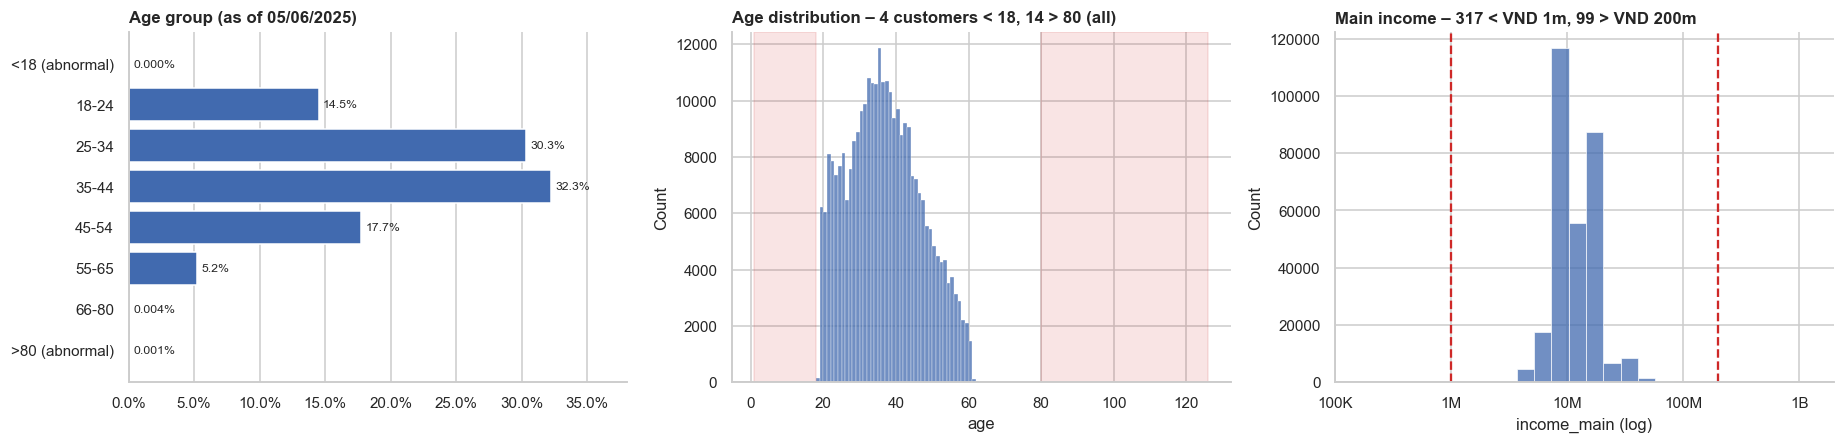

In [25]:
# tuổi, thu nhập, số phiên app: phân vị + giá trị bất thường
display(num_profile('demo', ['age', 'cnt_children', 'cnt_dependent', 'income_main', 'income_household', 'avg_session']))
anom = q('''SELECT
    count(*) FILTER (WHERE age < 18) tuoi_duoi_18, count(*) FILTER (WHERE age > 80) tuoi_tren_80,
    count(*) FILTER (WHERE age > 100) tuoi_tren_100, min(date_birth) sinh_som_nhat, max(date_birth) sinh_muon_nhat,
    count(*) FILTER (WHERE income_main < 1e6) thu_nhap_duoi_1tr, count(*) FILTER (WHERE income_main > 200e6) thu_nhap_tren_200tr,
    count(*) FILTER (WHERE income_household < income_main) thu_nhap_ho_nho_hon_ca_nhan,
    count(*) FILTER (WHERE cnt_children > 6) so_con_tren_6,
    100*avg((avg_session = 0)::int) pct_session_0
  FROM demo''')
display(anom)
ag = q('''SELECT CASE WHEN age < 18 THEN '<18 (bất thường)' WHEN age < 25 THEN '18-24' WHEN age < 35 THEN '25-34'
    WHEN age < 45 THEN '35-44' WHEN age < 55 THEN '45-54' WHEN age < 66 THEN '55-65' WHEN age <= 80 THEN '66-80'
    ELSE '>80 (bất thường)' END nhom_tuoi, count(*) n
  FROM demo WHERE age IS NOT NULL GROUP BY 1''')
ag = ag.set_index('nhom_tuoi').reindex(['<18 (bất thường)', '18-24', '25-34', '35-44', '45-54', '55-65', '66-80', '>80 (bất thường)']).fillna(0)
dd = q('SELECT age, income_main, avg_session FROM demo USING SAMPLE 300000 ROWS')
a = anom.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
barh(axes[0], ag.index, ag.n / ag.n.sum() * 100, 'Nhóm tuổi (tính đến 05/06/2025)', pct=True,
     color=[C_BAD if 'bất' in i else C_MAIN for i in ag.index], fmt=lambda v: f'{v:.1f}%' if v >= 0.1 else f'{v:.3f}%')
sns.histplot(dd.age.dropna(), binwidth=1, color=C_MAIN, ax=axes[1])
axes[1].axvspan(dd.age.min() - 1, 18, color=C_BAD, alpha=.12); axes[1].axvspan(80, max(dd.age.max(), 125) + 1, color=C_BAD, alpha=.12)
axes[1].set_title(f"Phân bố tuổi – {a.tuoi_duoi_18} khách < 18, {a.tuoi_tren_80} khách > 80 (toàn bộ)"); axes[1].set_xlabel('tuổi')
sns.histplot(dd.income_main.dropna(), bins=60, log_scale=True, color=C_MAIN, ax=axes[2])
for v in (1e6, 200e6):
    axes[2].axvline(v, color=C_BAD, ls='--')
axes[2].set_xlim(1e5, 2e9); axes[2].xaxis.set_major_formatter(mtick.FuncFormatter(human)); axes[2].set_xlabel('income_main (log)')
axes[2].set_title(f"Thu nhập chính – {a.thu_nhap_duoi_1tr} < 1 triệu, {a.thu_nhap_tren_200tr} > 200 triệu")
plt.tight_layout(); plt.show()

for desc, n in con.sql('''SELECT 'Tuổi < 18 hoặc > 80', count(*) FILTER (WHERE age < 18 OR age > 80) FROM demo
    UNION ALL SELECT 'Thu nhập chính < 1 triệu hoặc > 200 triệu', count(*) FILTER (WHERE income_main < 1e6 OR income_main > 200e6) FROM demo''').fetchall():
    if n: issue('R2 CUSTOMER/CONTRACT', 'Outlier', desc, n, 'Gán null / không dùng cho giá trị bất thường')

,n_tinh,dia_chi_null,dia_chi_khong_du_3_cap
0,68,149242,60


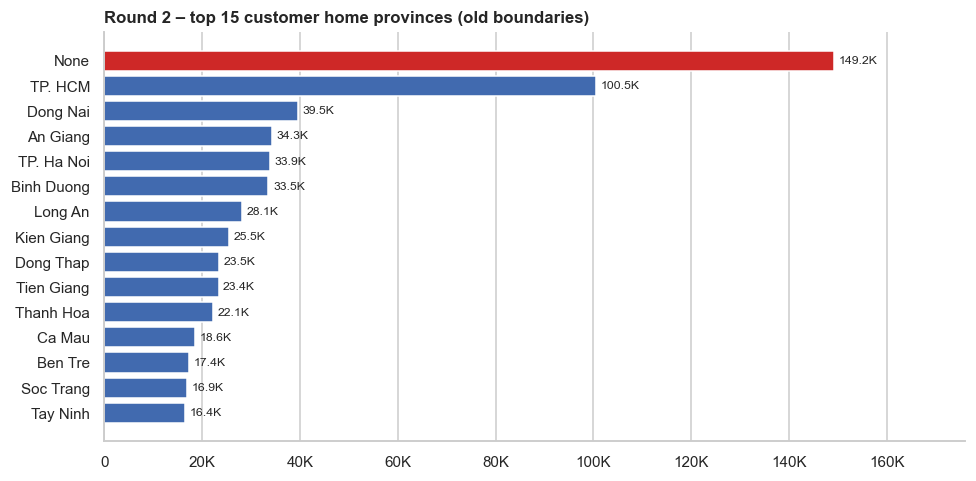

In [26]:
# địa chỉ khách (địa giới CŨ, không dấu) – tỉnh = phần cuối chuỗi
pv2 = q('''SELECT coalesce(province_r2, 'None') province_r2, count(*) n FROM demo GROUP BY 1 ORDER BY 2 DESC LIMIT 15''')
display(q('''SELECT count(DISTINCT province_r2) n_tinh, count(*) FILTER (WHERE address IS NULL) dia_chi_null,
    count(*) FILTER (WHERE len(string_split(address, ',')) <> 3) dia_chi_khong_du_3_cap FROM demo'''))
fig, ax = plt.subplots(figsize=(9, 4.5))
barh(ax, pv2.province_r2, pv2.n, 'Round 2 – top 15 tỉnh nơi ở của khách (địa giới cũ)', color=colors_for(pv2.province_r2))
plt.tight_layout(); plt.show()

### 8.3 Độ phủ & độ lệch khi gắn nhân khẩu học Round 2 vào khách Round 3
Nếu dùng biến nhân khẩu học cho Round 3, cần biết: (a) phủ được bao nhiêu hợp đồng / shop, (b) nhóm được phủ có **giống** tổng thể không.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

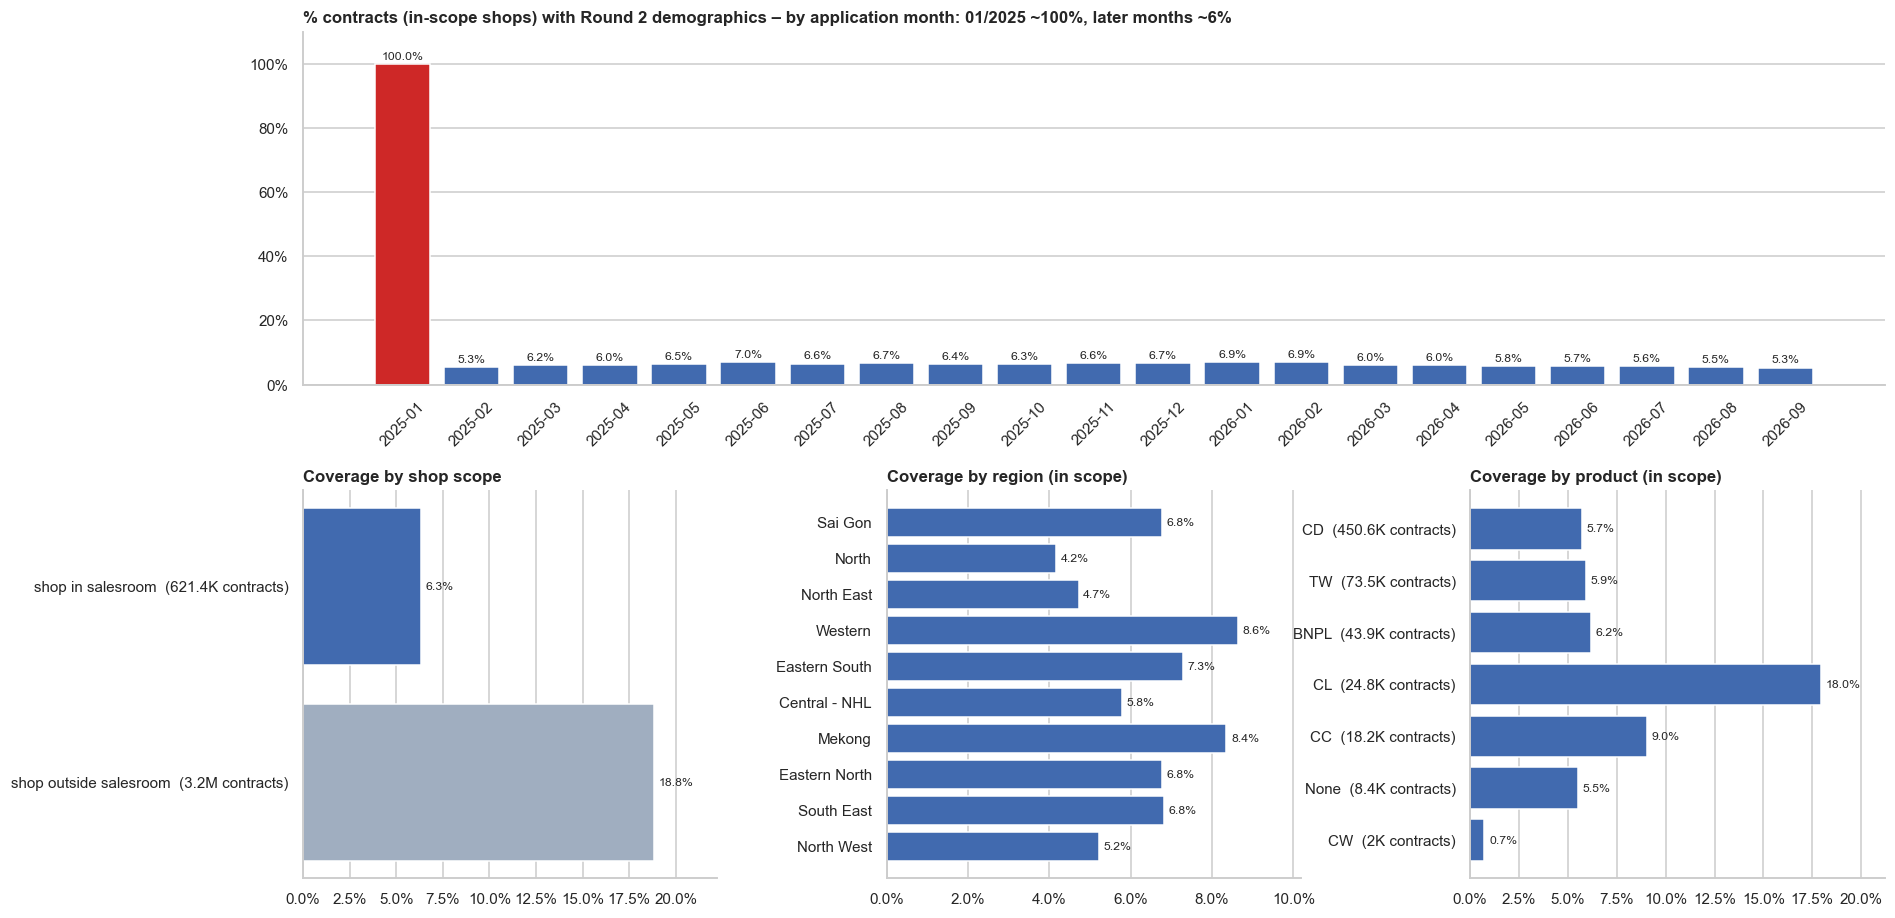

In [27]:
con.sql('''CREATE OR REPLACE TABLE ctr_demo AS
  SELECT c.*, d.skp_client IS NOT NULL has_demo, s.SKP_SALESROOM IS NOT NULL in_scope, s.SALESROOM_AREA area, s.SALESROOM_PROVINCE shop_province
  FROM contract c LEFT JOIN demo d ON d.skp_client = c.skp_client::BIGINT
  LEFT JOIN salesroom s ON s.SKP_SALESROOM = c.skp_salesroom''')
cv_scope = q('''SELECT in_scope, count(*) n, 100*avg(has_demo::int) pct FROM ctr_demo GROUP BY 1 ORDER BY 1 DESC''')
cv_month = q('''SELECT strftime(date_apply, '%Y-%m') thang, count(*) n, 100*avg(has_demo::int) pct
  FROM ctr_demo WHERE in_scope GROUP BY 1 ORDER BY 1''')
cv_area = q('''SELECT area, count(*) n, 100*avg(has_demo::int) pct FROM ctr_demo WHERE in_scope GROUP BY 1 ORDER BY 2 DESC''')
cv_prod = q('''SELECT coalesce(product, 'None') product, count(*) n, 100*avg(has_demo::int) pct
  FROM ctr_demo WHERE in_scope GROUP BY 1 ORDER BY 2 DESC''')

fig, ax = plt.subplot_mosaic([['m', 'm', 'm'], ['s', 'a', 'p']], figsize=(17, 8.5), gridspec_kw={'height_ratios': [1, 1.1]})
m = ax['m']
m.bar(cv_month.thang, cv_month.pct, color=[C_BAD if p > 50 else C_MAIN for p in cv_month.pct])
for x, v in zip(cv_month.thang, cv_month.pct):
    m.annotate(f'{v:.1f}%', (x, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
m.set_ylim(0, 110); m.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); m.tick_params(axis='x', rotation=45)
m.grid(axis='x', visible=False)
m.set_title('% hợp đồng (shop trong phạm vi) có nhân khẩu học Round 2 – theo tháng nộp hồ sơ: 01/2025 gần 100%, các tháng sau ~6%')
barh(ax['s'], cv_scope.in_scope.map({True: 'shop trong salesroom', False: 'shop ngoài salesroom'}) + '  (' + cv_scope.n.map(human) + ' HĐ)',
     cv_scope.pct, 'Độ phủ theo phạm vi shop', pct=True, color=[C_MAIN, C_GREY])
barh(ax['a'], cv_area.area, cv_area.pct, 'Độ phủ theo vùng (trong phạm vi)', pct=True)
barh(ax['p'], cv_prod['product'] + '  (' + cv_prod.n.map(human) + ' HĐ)', cv_prod.pct, 'Độ phủ theo sản phẩm (trong phạm vi)', pct=True)
plt.tight_layout(); plt.show()

,in_r3_scope,n,tuoi_tb,pct_nu,pct_dai_hoc_tro_len,thu_nhap_trung_vi_trieu,pct_tphcm
0,True,31329,35.00,53.60,14.00,12.00,13.60
1,False,969199,36.50,49.70,13.90,12.00,11.70


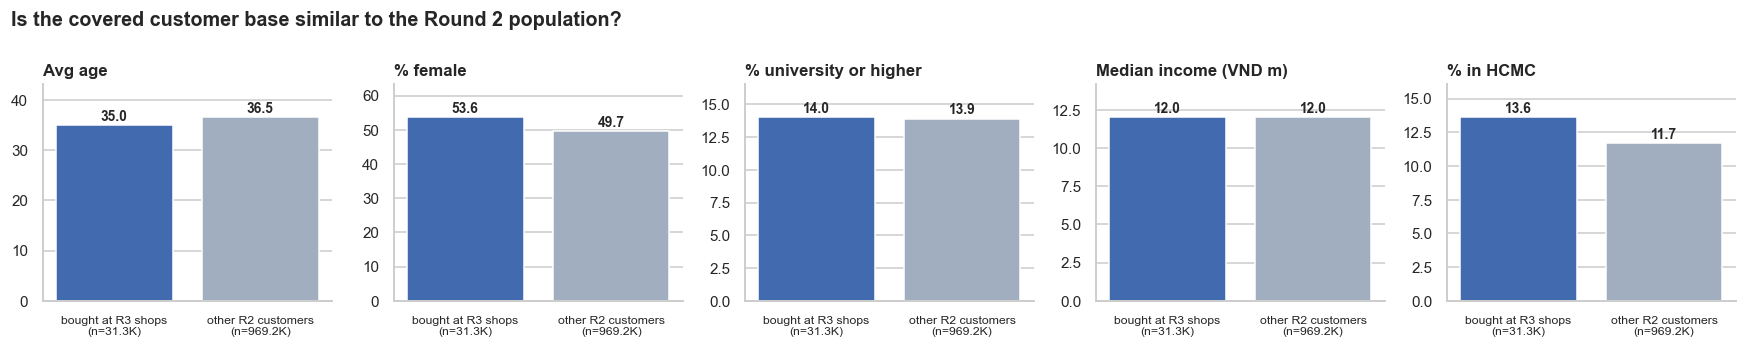

In [28]:
# độ lệch: hồ sơ khách Round 2 có mua ở shop trong phạm vi Round 3 so với toàn bộ khách Round 2
con.sql('''CREATE OR REPLACE TABLE demo_flag AS SELECT d.*, d.skp_client IN (SELECT skp_client::BIGINT FROM ctr_demo WHERE in_scope AND has_demo) AS in_r3_scope FROM demo d''')
cmp = q('''SELECT in_r3_scope, count(*) n, round(avg(age) FILTER (WHERE age BETWEEN 18 AND 80), 1) tuoi_tb,
    round(100*avg((gender = 'Female')::int), 1) pct_nu,
    round(100*avg((education IN ('Bachelor''s degree', 'Master''s degree'))::int), 1) pct_dai_hoc_tro_len,
    round(median(income_main)/1e6, 1) thu_nhap_trung_vi_trieu, round(100*avg((province_r2 = 'TP. HCM')::int), 1) pct_tphcm
  FROM demo_flag GROUP BY 1''')
display(cmp)
c = cmp.set_index('in_r3_scope')
METRICS = {'tuoi_tb': 'Tuổi TB', 'pct_nu': '% nữ', 'pct_dai_hoc_tro_len': '% ĐH trở lên',
           'thu_nhap_trung_vi_trieu': 'Thu nhập trung vị (tr)', 'pct_tphcm': '% ở TP.HCM'}
fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 3.2))
for ax, (k, lab) in zip(axes, METRICS.items()):
    v = [c.loc[True, k], c.loc[False, k]]
    ax.bar([f'mua ở shop R3\n(n={human(c.loc[True, "n"])})', f'khách R2 còn lại\n(n={human(c.loc[False, "n"])})'], v, color=[C_MAIN, C_GREY])
    for i, x in enumerate(v):
        ax.annotate(f'{x:,.1f}', (i, x), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
    ax.set_title(lab); ax.tick_params(axis='x', labelsize=8); ax.grid(axis='x', visible=False); ax.margins(y=.18)
fig.suptitle('Tệp khách được phủ có giống tổng thể Round 2 không?', fontweight='bold', x=0.01, ha='left')
plt.tight_layout(); plt.show()

Hợp đồng (shop trong phạm vi, khách có địa chỉ) mà khách ở CÙNG tỉnh với shop – sau quy đổi sáp nhập: 79.5%
Tỉnh nơi ở chưa quy đổi được (kiểm tra lại bảng map): []


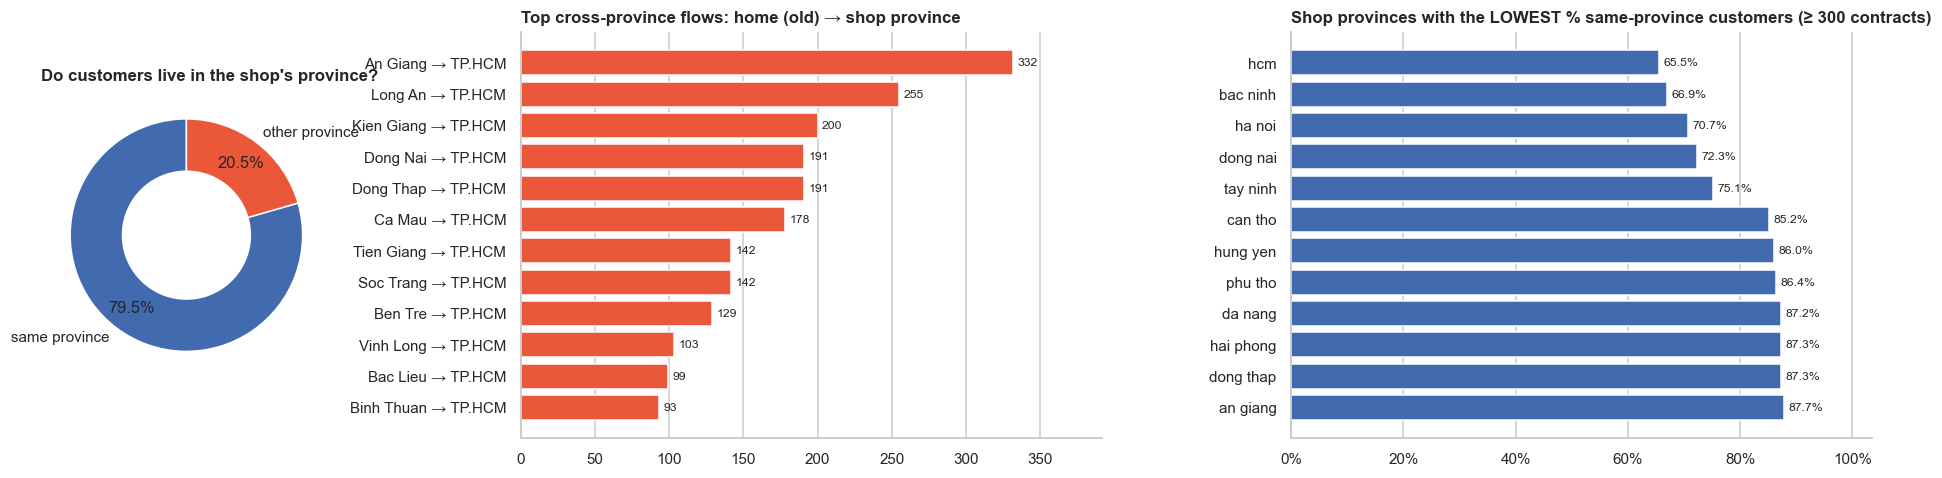

In [29]:
# khách mua ở shop cùng tỉnh với nơi ở?
# Địa chỉ R2 theo địa giới CŨ (63 tỉnh, không dấu); shop R3 phần lớn theo địa giới MỚI (34 tỉnh, NQ 202/2025/QH15)
# -> chuẩn hóa tên (bỏ dấu, bỏ 'TP.') rồi quy đổi tỉnh cũ -> tỉnh mới trước khi so.
import unicodedata
def norm(s):
    if s is None: return None
    s = s.replace('Đ', 'D').replace('đ', 'd')
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode().lower()
    return ' '.join(s.replace('tp.', ' ').replace('thanh pho', ' ').replace('-', ' ').split())
MERGE_2025 = {  # tỉnh cũ -> tỉnh mới (chỉ liệt kê tỉnh bị sáp nhập; tỉnh giữ nguyên tự map về chính nó)
    'ha giang': 'tuyen quang', 'yen bai': 'lao cai', 'bac kan': 'thai nguyen', 'vinh phuc': 'phu tho', 'hoa binh': 'phu tho',
    'bac giang': 'bac ninh', 'thai binh': 'hung yen', 'hai duong': 'hai phong', 'ha nam': 'ninh binh', 'nam dinh': 'ninh binh',
    'quang binh': 'quang tri', 'quang nam': 'da nang', 'kon tum': 'quang ngai', 'binh dinh': 'gia lai', 'ninh thuan': 'khanh hoa',
    'dak nong': 'lam dong', 'binh thuan': 'lam dong', 'phu yen': 'dak lak', 'binh duong': 'hcm', 'ba ria vung tau': 'hcm',
    'binh phuoc': 'dong nai', 'long an': 'tay ninh', 'soc trang': 'can tho', 'hau giang': 'can tho',
    'ben tre': 'vinh long', 'tra vinh': 'vinh long', 'tien giang': 'dong thap', 'bac lieu': 'ca mau', 'kien giang': 'an giang',
    'thua thien hue': 'hue', 'dak lak': 'dak lak', 'ho chi minh': 'hcm',
}
to_new = lambda s: None if s is None else MERGE_2025.get(norm(s), norm(s))
pairs = q('''SELECT d.province_r2, c.shop_province, count(*) n FROM ctr_demo c JOIN demo d ON d.skp_client = c.skp_client::BIGINT
  WHERE c.in_scope GROUP BY all''')
pairs['tinh_moi_noi_o'] = pairs.province_r2.map(to_new)
pairs['tinh_moi_shop'] = pairs.shop_province.map(to_new)
pairs['cung_tinh'] = [a == b if a and b else None for a, b in zip(pairs.tinh_moi_noi_o, pairs.tinh_moi_shop)]
known = pairs[pairs.cung_tinh.notna()]
same = known.loc[known.cung_tinh == True, 'n'].sum() / known.n.sum()
print(f"Hợp đồng (shop trong phạm vi, khách có địa chỉ) mà khách ở CÙNG tỉnh với shop – sau quy đổi sáp nhập: {same:.1%}")
print('Tỉnh nơi ở chưa quy đổi được (kiểm tra lại bảng map):', sorted(set(pairs.tinh_moi_noi_o.dropna()) - set(pairs.tinh_moi_shop.dropna()))[:20])

flows = known[known.cung_tinh == False].groupby(['province_r2', 'shop_province']).n.sum().sort_values(ascending=False).head(12)
by_shop = known.groupby('tinh_moi_shop').apply(lambda g: pd.Series({'n': g.n.sum(), 'pct_cung': g.loc[g.cung_tinh == True, 'n'].sum() / g.n.sum() * 100}),
                                               include_groups=False)
by_shop = by_shop[by_shop.n >= 300].sort_values('pct_cung').head(12)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={'width_ratios': [.6, 1.2, 1.2]})
axes[0].pie([same, 1 - same], labels=['cùng tỉnh', 'khác tỉnh'], autopct='%1.1f%%', colors=[C_MAIN, C_ALT], startangle=90,
            wedgeprops={'width': .45}, pctdistance=.78)
axes[0].set_title('Khách ở cùng tỉnh với shop?')
barh(axes[1], [f'{a} → {b}' for a, b in flows.index], flows.values, 'Top luồng khác tỉnh: nơi ở (cũ) → tỉnh shop', color=C_ALT)
barh(axes[2], by_shop.index, by_shop.pct_cung, 'Tỉnh shop có % khách cùng tỉnh THẤP nhất (≥ 300 HĐ)', pct=True)
plt.tight_layout(); plt.show()

### 8.4 Nhận xét – biến nhân khẩu học

**Địa lý shop (Round 3) – dùng được, chất lượng tốt**
- 54 tên tỉnh, 10 vùng, 2.315 phường; không có null.
- 95,6% shop ghi theo **địa giới mới** (`SALESROOM_DISTRICT = '.'`), 4,4% (622 shop) còn theo địa giới cũ → 54 tên tỉnh thay vì 34. Cần quy đổi về 34 tỉnh mới trước khi gộp theo tỉnh.
- 96% đại lý là *Stone Shop* (1 shop / đại lý, cùng tỉnh). Đại lý chuỗi (Key Account, NS KA, Local Partner) có > 50% shop nằm khác tỉnh với đại lý → khi phân tích theo địa lý dùng **tỉnh của shop**, không dùng tỉnh của đại lý.

**Nhân khẩu học khách (Round 2) – chỉ dùng làm bối cảnh / kiểm chứng**

| Biến | Đánh giá | Dùng? |
|---|---|---|
| `FLAG_CAR_OWNER` | 100% = `X` (một giá trị duy nhất) | ❌ Bỏ |
| `NAME_SALARY_FREQUENCY` | 99,1% = XNA | ❌ Bỏ |
| `CNT_PERSON_DEPENDENT` | 98,5% null, max 47 | ❌ Bỏ |
| `AMT_INCOME_HOUSEHOLD` | chỉ ~2,9% khách có, 14.702 trường hợp nhỏ hơn thu nhập cá nhân | ❌ Bỏ |
| `AVG_SESSION_PER_WEEK_2025` | 93% = 0 | ⚠ Chỉ dùng dạng cờ có / không dùng app |
| `NAME_GENDER` | 50/50, gần như không thiếu | ⚠ Chỉ mô tả, **không dùng để chấm rủi ro** |
| `DATE_BIRTH` → tuổi | trung vị 36; 4 khách < 18 tuổi, 14 khách > 80 (max 124, sinh năm 1901 / 2023) | ✅ Gán null cho tuổi ngoài 18–80 |
| `NAME_EDUCATION_TYPE` | 16% XNA | ✅ Giữ, XNA thành một nhóm riêng |
| `CNT_CHILDREN` | 12,6% null, max 99, 574 khách > 6 con | ✅ Gộp nhóm 0 / 1 / 2 / 3+ |
| `AMT_INCOME_MAIN` | trung vị 12 triệu; 317 khách < 1 triệu, 99 khách > 200 triệu (max 900 triệu) | ✅ Cắt ở p1–p99 |
| `NAME_INCOME_TYPE`, `CODE_PROFESSION` | ~14,5% thiếu | ✅ Giữ |
| `ADDRESS` | 14,9% null; địa giới **cũ**, không dấu, dạng `phường,quận,tỉnh` | ✅ Lấy tỉnh, quy đổi sang 34 tỉnh mới |

**Độ phủ – đây là giới hạn lớn nhất**
- Chỉ **6,3%** hợp đồng ở shop trong phạm vi Round 3 có thông tin nhân khẩu học (riêng tháng 01/2025 là 99,9% – tệp Round 2 được chọn từ khách có hợp đồng tháng 1/2025).
- Tệp được phủ hơi lệch so với toàn bộ khách Round 2: nhiều nữ hơn (53,6% so với 49,7%), trẻ hơn (35,0 so với 36,5 tuổi), nhiều TP.HCM hơn (13,6% so với 11,7%).
- → **Không đủ để làm chỉ số theo shop.** Chỉ dùng để mô tả chân dung khách và kiểm chứng giả thuyết, ghi rõ giới hạn khi trình bày.

**Phát hiện dùng được cho bài toán shop**
- Sau khi quy đổi sáp nhập, **79,5%** hợp đồng có khách ở **cùng tỉnh** với shop → thị trường của một shop chủ yếu là dân trong tỉnh, nên dữ liệu ngoài (dân số, thu nhập) có thể gắn **theo tỉnh**.
- 20,5% còn lại chủ yếu là khách có địa chỉ ở miền Tây / Đông Nam Bộ nhưng mua ở **TP.HCM** (lao động nhập cư) → thị trường của shop TP.HCM rộng hơn dân số đăng ký của thành phố.

## 9. Tổng hợp vấn đề

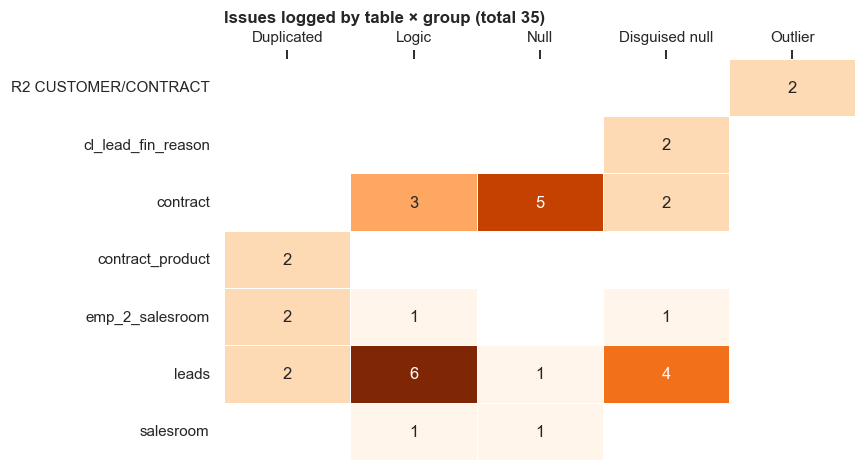

,bảng,nhóm,vấn đề,số dòng,cách xử lý
0,R2 CUSTOMER/CONTRACT,Outlier,Thu nhập chính < 1 triệu hoặc > 200 triệu,416,Gán null / không dùng cho giá trị bất thường
1,R2 CUSTOMER/CONTRACT,Outlier,Tuổi < 18 hoặc > 80,18,Gán null / không dùng cho giá trị bất thường
2,cl_lead_fin_reason,Null trá hình,CODE_FINISH: 8.3% là XNA/-1/3000,1,Đổi XNA / -1 / 3000-01-01 thành NULL khi làm sạch
3,cl_lead_fin_reason,Null trá hình,DESC_DESCRIPTION: 8.3% là XNA/-1/3000,1,Đổi XNA / -1 / 3000-01-01 thành NULL khi làm sạch
4,contract,Logic,Thiếu product,"49,117",Không nối được với lead theo sản phẩm – loại khỏi phân tích chuyển đổi
5,contract,Logic,Cancelled nhưng có ngày ký thật,"10,515",Hủy sau khi ký – không tính vào doanh số đã ký
6,contract,Logic,Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026),616,Hợp lệ (nộp trước 30/09) – giữ
7,contract,Null,price: 79.3% null,"2,995,122",Đúng nghiệp vụ: chỉ CD / TW có giá món hàng
8,contract,Null,amt_billing_1st: 78.4% null,"2,959,199",Đúng nghiệp vụ: chỉ BNPL / CC có sao kê
9,contract,Null,amt_billing_2nd: 78.4% null,"2,959,199",Đúng nghiệp vụ: chỉ BNPL / CC có sao kê


In [30]:
DEFAULT_ACTION = {
    'Null': 'Null có nghĩa nghiệp vụ (xem mục 2.1) – không impute; lọc theo sản phẩm / trạng thái',
    'Null trá hình': 'Đổi XNA / -1 / 3000-01-01 thành NULL khi làm sạch',
    'Duplicated': 'Xem mục 3 và 10',
    'Logic': 'Gắn cờ / loại khi phân tích (xem mục 10)',
    'Outlier': 'Gán null / cắt p1–p99',
}
ACTION = {  # ghi đè theo (bảng, chuỗi con trong mô tả vấn đề)
    ('leads', 'skp_employee'): 'Bỏ cột – trống 100%; nhân sự lấy từ emp_2_salesroom',
    ('leads', 'text_tenor'): 'Không dùng (99% XNA)',
    ('leads', 'text_contract_number'): 'Không dùng làm cờ chuyển đổi; nối lead→HĐ theo quy tắc của đề',
    ('leads', 'skp_credit_case'): 'Không dùng làm cờ chuyển đổi; nối lead→HĐ theo quy tắc của đề',
    ('leads', 'skp_salesroom = -1'): 'Loại khỏi phân tích theo shop',
    ('contract', 'date_sign'): 'date_sign = 3000 → hồ sơ chưa ký; đổi thành NULL',
    ('contract', 'price'): 'Đúng nghiệp vụ: chỉ CD / TW có giá món hàng',
    ('contract', 'payment_num'): 'Đúng nghiệp vụ: BNPL / CC không có số kỳ cố định',
    ('contract', 'amt_billing'): 'Đúng nghiệp vụ: chỉ BNPL / CC có sao kê',
    ('contract', 'Cancelled nhưng có ngày ký'): 'Hủy sau khi ký – không tính vào doanh số đã ký',
    ('contract', 'Ký sau ngày cuối'): 'Hợp lệ (nộp trước 30/09) – giữ',
    ('contract', 'Thiếu product'): 'Không nối được với lead theo sản phẩm – loại khỏi phân tích chuyển đổi',
    ('contract_product', 'Trùng khóa'): 'HĐ có > 1 món hàng – gộp hoặc lấy món đầu',
    ('emp_2_salesroom', 'Trùng khóa'): 'Giữ valid_to lớn nhất; đếm SA bằng DISTINCT skp_employee',
    ('leads', 'id_uuid'): 'Khóa lead = lead_id; (uuid, sản phẩm) trùng = lead được đẩy lại sau ~1 tuần',
}
def action_for(t, g, desc, cur):
    for (tt, key), a in ACTION.items():
        if tt == t and key in desc:
            return a
    return cur or DEFAULT_ACTION.get(g, '')

iss = pd.DataFrame(ISSUES, columns=['bảng', 'nhóm', 'vấn đề', 'số dòng', 'cách xử lý'])
iss['cách xử lý'] = [action_for(*r) for r in iss[['bảng', 'nhóm', 'vấn đề', 'cách xử lý']].itertuples(index=False)]
iss = iss.sort_values(['bảng', 'nhóm', 'số dòng'], ascending=[True, True, False]).reset_index(drop=True)

hm = iss.pivot_table(index='bảng', columns='nhóm', values='vấn đề', aggfunc='count').fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(hm) + 1.3))
sns.heatmap(hm, annot=True, fmt='d', cmap='Oranges', cbar=False, linewidths=.5, ax=ax, mask=hm == 0)
ax.grid(False); ax.xaxis.tick_top(); ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(axis='y', rotation=0)
ax.set_title(f'Số vấn đề ghi nhận theo bảng × nhóm (tổng {len(iss)})', pad=24)
plt.tight_layout(); plt.show()

display(iss.style.format({'số dòng': '{:,}'}).bar(subset=['số dòng'], color='#fbd38d', vmin=0)
        .set_properties(**{'text-align': 'left'}))

## 10. Kết luận & quy tắc làm sạch đề xuất

### Duplicated
| Bảng | Hiện tượng | Xử lý |
|---|---|---|
| `leads` | 55 dòng trùng toàn bộ. ~209K `id_uuid` xuất hiện 2 lần: ~103K là **cùng phiên được chào 2 sản phẩm** (CL + CC); ~106K là **cùng uuid + cùng sản phẩm, được đẩy lại sau ~1 tuần** (khác `dtime_created`, một nửa khác `result`) | Bỏ trùng toàn dòng; khóa lead = `lead_id` (đánh số khi làm sạch); đếm lead duy nhất theo `(id_uuid, code_product_type)` |
| `contract` | Không trùng | – |
| `contract_product` | 1.400 dòng trùng toàn bộ; 3.078 hợp đồng có > 1 món hàng (khác hãng / loại) | Bỏ trùng; nếu cần 1 dòng / hợp đồng thì lấy món đầu hoặc gộp |
| `emp_2_salesroom` | 912 dòng trùng toàn bộ; 98 bộ (nhân viên, shop, ngày bắt đầu) có 2 ngày kết thúc khác nhau; 418 cặp giai đoạn chồng lấn | Bỏ trùng; với trùng khóa giữ `valid_to` lớn nhất; khi đếm số SA của shop theo tháng dùng `DISTINCT skp_employee` |

### Null & null trá hình
- `leads.skp_employee`: **trống 100%** → không phân tích được nhân viên theo lead.
- `leads.text_tenor` 99,3% XNA; `text_contract_number` / `skp_credit_case` chỉ có ở ~2% lead → không dùng làm cờ chuyển đổi, nối theo quy tắc của đề.
- `contract.price` chỉ có ở **CD / TW** (sản phẩm mua hàng); `payment_num` trống ở **BNPL / CC** (không có số kỳ cố định).
- `contract.amt_billing_*` chỉ có ở **BNPL / CC** → là dư nợ sao kê của sản phẩm hạn mức, không phải tiền góp của khoản vay trả góp.
- `contract.credit_amount = 0` ở **100% CC** và ~70% BNPL → với CC / BNPL, đo quy mô bằng `amt_billing_1st`, không dùng `credit_amount`.
- `contract.product` null ở 49.147 hợp đồng (1,3%) → không nối được với lead theo sản phẩm.
- `date_sign = 3000-01-01`: hồ sơ chưa ký (Rejected / Cancelled) → đổi thành null.
- `contract.skp_client`: 325 hợp đồng = -1 (mã giữ chỗ) và 7 hợp đồng null → **đã bỏ khi nạp dữ liệu** (332 dòng, < 0,01%), không ảnh hưởng tỷ lệ.

### Outlier
- `leads.amt_loan_limit`: min 9 đồng, max **19 tỷ** (CL) → cắt theo p1–p99 từng sản phẩm.
- Số tiền hợp đồng nằm trong khoảng hợp lý (CL ≤ 250 triệu, TW ≤ 80 triệu, CD ≤ 100 triệu); không có giá trị âm.
- Số ngoài IQR của `init_pay`, `ins_amount`, `amt_billing_*` cao (15–25%) vì phần lớn = 0 → **không phải outlier thật**, chỉ là phân bố lệch.

### Logic
- 10.515 hợp đồng *Cancelled* nhưng có ngày ký thật → hủy sau khi ký; không tính vào doanh số đã ký.
- 616 hợp đồng ký sau 30/09/2026 (nộp hồ sơ trước đó) → hợp lệ, giữ.
- 20 lead có `date_assigned` trước `dtime_created`; 1.229 lead có `skp_salesroom = -1` → loại khỏi phân tích theo shop.
- `emp_2_salesroom.role` chỉ có **SA** → không có thông tin cấp quản lý.

### Khóa nối & phạm vi
- `salesroom` chỉ chứa **shop mở từ 2025**: chỉ 16,5% hợp đồng và 6,3% lead nối được → phạm vi phân tích = 14.231 shop này.
- `contract_product` chỉ phủ 20,7% hợp đồng (chủ yếu CD / TW); nhãn không thống nhất (`FITNESS` / `Fitness`, `Two weelers`) → chuẩn hóa chữ hoa/thường trước khi gộp nhóm.
- `salesroom → seller` khớp 99,9%; `emp_2_salesroom → salesroom` khớp 100%.
- `code_lead_status`: 99,7% = 4 (*No Cluster*), không có *DEAL* → **không dùng** làm kết quả lead.

### Nối lead → hợp đồng (mục 7.1)
- Quy tắc của đề: cùng `skp_client` + cùng sản phẩm + giao lead ≤ thời điểm đăng ký HĐ.
- WDE / GMA / GMA_BIG_TICKET / CRM sinh lead **sau** khi khách nộp hồ sơ → đo 2 hướng: `converted_apply` (lead tạo hồ sơ, chỉ cho `lead_flow = ORIGINATION`) và `converted_sign` (lead ra HĐ ký, mọi lead).
- Ghép 1-1 trong 30 ngày, ưu tiên link hệ thống; `REL` ghép như `CC`; bỏ khách `skp_client = -1`. Kết quả ở `data_clean/lead_contract_link.csv`.
- Lead giao từ 09/2026 chưa đủ thời gian chuyển đổi (HĐ chỉ đến 30/09/2026) → loại khi tính tỷ lệ.

### Nhân khẩu học
Xem mục 8.4: địa lý shop dùng được; nhân khẩu học khách (Round 2) chỉ phủ 6,3% hợp đồng trong phạm vi → chỉ dùng mô tả / kiểm chứng.